In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [ ]:
import shutil

total, used, free = shutil.disk_usage("/kaggle/working")

print(f"Total disk space: {total / (1024**3):.2f} GB")
print(f"Used disk space: {used / (1024**3):.2f} GB")
print(f"Free disk space: {free / (1024**3):.2f} GB")

In [ ]:
import os
import requests

url = "https://zenodo.org/records/18147026/files/Anev.zip?download=1"
output_path = "/kaggle/working/Anev.zip"

response = requests.get(url, stream=True, timeout=60)
response.raise_for_status()

with open(output_path, "wb") as f:
    for chunk in response.iter_content(chunk_size=1024 * 1024):
        if chunk:
            f.write(chunk)

print("Downloaded:", output_path)
print("Size (GB):", round(os.path.getsize(output_path) / 1e9, 2))

In [ ]:
import os
import zipfile

zip_path = "/kaggle/working/Anev.zip"

print("ZIP exists:", os.path.exists(zip_path))
print("ZIP size (GB):", round(os.path.getsize(zip_path) / 1e9, 2))

with zipfile.ZipFile(zip_path, "r") as z:
    files = z.infolist()

    print("\nTotal items:", len(files))
    print("\nFirst 20 items:")

    for item in files[:20]:
        print(item.filename, "| Size (MB):",
              round(item.file_size / 1e6, 2))

    total_size = sum(item.file_size for item in files)
    print("\nTotal uncompressed size (GB):",
          round(total_size / 1e9, 2))

In [ ]:
import os
import zipfile

zip_path = "/kaggle/working/Anev.zip"
extract_dir = "/kaggle/working/AortaSeg60"

os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    for item in z.infolist():
        name = item.filename

        # Keep only the actual Anev case folders
        if not name.startswith("Anev_"):
            continue

        # Skip macOS metadata
        if "/.DS_Store" in name or name.endswith("/.DS_Store"):
            continue

        # Extract only entries inside Anev case folders
        z.extract(item, extract_dir)

print("Extraction completed!")
print("Dataset location:", extract_dir)
print("Case folders:", sorted(
    name for name in os.listdir(extract_dir)
    if name.startswith("Anev_")
))

In [ ]:
import os
import glob

root = "/kaggle/working/AortaSeg60"

images = sorted(glob.glob(
    root + "/Anev_*/nifti/*_image.nii.gz"
))
masks = sorted(glob.glob(
    root + "/Anev_*/segmentation/*_segmentation.nii.gz"
))

print("Number of CT images:", len(images))
print("Number of segmentation masks:", len(masks))

print("\nFirst CT image:", images[0] if images else "Not found")
print("First mask:", masks[0] if masks else "Not found")

In [ ]:
!pip install -q SimpleITK

In [ ]:
import os
import glob
import SimpleITK as sitk

root = "/kaggle/working/AortaSeg60"

images = sorted(glob.glob(
    root + "/Anev_*/nifti/*_image.nii.gz"
))
masks = sorted(glob.glob(
    root + "/Anev_*/segmentation/*_segmentation.nii.gz"
))

mask_by_case = {
    os.path.basename(os.path.dirname(os.path.dirname(path))): path
    for path in masks
}

print("CT images:", len(images))
print("Masks:", len(masks))
print("\nIMAGE-MASK VALIDATION\n")

for image_path in images:
    case_name = os.path.basename(
        os.path.dirname(os.path.dirname(image_path))
    )
    mask_path = mask_by_case.get(case_name)

    if mask_path is None:
        print(case_name, "- MASK MISSING")
        continue

    image = sitk.ReadImage(image_path)
    mask = sitk.ReadImage(mask_path)

    print(f"\n{case_name}")
    print("  Image size:   ", image.GetSize())
    print("  Mask size:    ", mask.GetSize())
    print("  Image spacing:", image.GetSpacing())
    print("  Mask spacing: ", mask.GetSpacing())
    print("  Same size:    ", image.GetSize() == mask.GetSize())
    print("  Same spacing: ", all(
        abs(a - b) < 1e-5
        for a, b in zip(image.GetSpacing(), mask.GetSpacing())
    ))
    print("  Same origin:  ", all(
        abs(a - b) < 1e-4
        for a, b in zip(image.GetOrigin(), mask.GetOrigin())
    ))
    print("  Same direction:", all(
        abs(a - b) < 1e-5
        for a, b in zip(image.GetDirection(), mask.GetDirection())
    ))
    print("  Mask labels:  ", sitk.GetArrayViewFromImage(mask).min(),
          "to", sitk.GetArrayViewFromImage(mask).max())

In [ ]:
import os
import glob
import SimpleITK as sitk

root = "/kaggle/working/AortaSeg60"

for image_path in sorted(
    glob.glob(root + "/Anev_*/nifti/*_image.nii.gz")
):
    case = os.path.basename(
        os.path.dirname(os.path.dirname(image_path))
    )

    mask_path = (
        f"{root}/{case}/segmentation/"
        f"{case}_segmentation.nii.gz"
    )

    image = sitk.ReadImage(image_path)
    mask = sitk.ReadImage(mask_path)

    image_origin = image.GetOrigin()
    mask_origin = mask.GetOrigin()

    difference = tuple(
        round(m - i, 4)
        for i, m in zip(image_origin, mask_origin)
    )

    print(f"\n{case}")
    print("CT origin:   ", image_origin)
    print("Mask origin: ", mask_origin)
    print("Mask - CT:   ", difference)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import SimpleITK as sitk

case = "Anev_01"
root = "/kaggle/working/AortaSeg60"

image_path = f"{root}/{case}/nifti/{case}_image.nii.gz"
mask_path = f"{root}/{case}/segmentation/{case}_segmentation.nii.gz"

image = sitk.GetArrayFromImage(sitk.ReadImage(image_path))
mask = sitk.GetArrayFromImage(sitk.ReadImage(mask_path))

# Find the slice containing the most segmented voxels
slice_counts = np.count_nonzero(mask, axis=(1, 2))
z = int(np.argmax(slice_counts))

print("Selected slice:", z)
print("Mask pixels on slice:", int(slice_counts[z]))

plt.figure(figsize=(9, 9))
plt.imshow(image[z], cmap="gray", vmin=-200, vmax=600)
plt.contour(mask[z] > 0, levels=[0.5], colors="red", linewidths=0.8)
plt.title(f"{case}: CT with segmentation boundary")
plt.axis("off")
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import SimpleITK as sitk

case = "Anev_01"
root = "/kaggle/working/AortaSeg60"

image = sitk.GetArrayFromImage(
    sitk.ReadImage(f"{root}/{case}/nifti/{case}_image.nii.gz")
)
mask = sitk.GetArrayFromImage(
    sitk.ReadImage(f"{root}/{case}/segmentation/{case}_segmentation.nii.gz")
)

# Inspect slices from different parts of the volume
slices = [image.shape[0] // 5, 2 * image.shape[0] // 5,
          3 * image.shape[0] // 5, 4 * image.shape[0] // 5,
          image.shape[0] - 1]

fig, axes = plt.subplots(1, 5, figsize=(18, 5))

for ax, z in zip(axes, slices):
    ax.imshow(image[z], cmap="gray", vmin=-200, vmax=600)
    if np.any(mask[z]):
        ax.contour(mask[z] > 0, levels=[0.5], colors="red", linewidths=0.7)
    ax.set_title(f"Slice {z}\nMask voxels: {np.count_nonzero(mask[z])}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import SimpleITK as sitk

case = "Anev_01"
root = "/kaggle/working/AortaSeg60"

ct = sitk.ReadImage(
    f"{root}/{case}/nifti/{case}_image.nii.gz"
)
mask = sitk.ReadImage(
    f"{root}/{case}/segmentation/{case}_segmentation.nii.gz"
)

def physical_bounds(image):
    size = image.GetSize()
    origin = image.GetOrigin()
    spacing = image.GetSpacing()
    direction = image.GetDirection()

    corners = []
    for x in [0, size[0] - 1]:
        for y in [0, size[1] - 1]:
            for z in [0, size[2] - 1]:
                corners.append(
                    image.TransformIndexToPhysicalPoint((x, y, z))
                )

    return [
        (min(p[i] for p in corners), max(p[i] for p in corners))
        for i in range(3)
    ]

print("CT origin:", ct.GetOrigin())
print("Mask origin:", mask.GetOrigin())
print("CT physical bounds (X, Y, Z):")
print(physical_bounds(ct))
print("Mask physical bounds (X, Y, Z):")
print(physical_bounds(mask))

In [ ]:
import numpy as np
import SimpleITK as sitk

case = "Anev_01"
root = "/kaggle/working/AortaSeg60"

ct = sitk.ReadImage(
    f"{root}/{case}/nifti/{case}_image.nii.gz"
)
mask = sitk.ReadImage(
    f"{root}/{case}/segmentation/{case}_segmentation.nii.gz"
)

mask_array = sitk.GetArrayFromImage(mask)
print("Mask shape (Z, Y, X):", mask_array.shape)
print("Foreground voxels:", int(np.count_nonzero(mask_array)))

# Count connected foreground components
components = sitk.ConnectedComponent(
    sitk.Cast(mask > 0, sitk.sitkUInt8)
)
stats = sitk.LabelShapeStatisticsImageFilter()
stats.Execute(components)

component_sizes = sorted(
    [stats.GetNumberOfPixels(label)
     for label in stats.GetLabels()],
    reverse=True
)

print("Connected components:", len(component_sizes))
print("Largest component sizes:", component_sizes[:10])

print("\nCT and mask geometry:")
print("Same size:", ct.GetSize() == mask.GetSize())
print("Same spacing:", ct.GetSpacing() == mask.GetSpacing())
print("Same direction:", ct.GetDirection() == mask.GetDirection())
print("Same origin:", ct.GetOrigin() == mask.GetOrigin())

In [ ]:
import os
import SimpleITK as sitk

case = "Anev_01"
root = "/kaggle/working/AortaSeg60"

ct_path = f"{root}/{case}/nifti/{case}_image.nii.gz"
mask_path = f"{root}/{case}/segmentation/{case}_segmentation.nii.gz"

test_path = f"/kaggle/working/{case}_mask_geometry_test.nii.gz"

ct = sitk.ReadImage(ct_path)
mask = sitk.ReadImage(mask_path)

# Confirm matching voxel grids before making the test copy
assert ct.GetSize() == mask.GetSize()
assert ct.GetSpacing() == mask.GetSpacing()
assert ct.GetDirection() == mask.GetDirection()

# Change geometry on a separate copy only
test_mask = sitk.Image(mask)
test_mask.CopyInformation(ct)

sitk.WriteImage(test_mask, test_path)

print("Temporary test mask saved:", test_path)
print("Original mask remains unchanged.")
print("Test mask origin:", sitk.ReadImage(test_path).GetOrigin())
print("CT origin:", ct.GetOrigin())

In [ ]:
from IPython.display import FileLink, display

ct_path = (
    "/kaggle/working/AortaSeg60/"
    "Anev_01/nifti/Anev_01_image.nii.gz"
)

display(FileLink(ct_path))

In [ ]:
from IPython.display import FileLink, display

mask_path = (
    "/kaggle/working/"
    "Anev_01_mask_geometry_test.nii.gz"
)

display(FileLink(mask_path))

In [ ]:
import os
import zipfile
from IPython.display import FileLink, display

mask_path = "/kaggle/working/Anev_01_mask_geometry_test.nii.gz"
zip_path = "/kaggle/working/Anev_01_test_mask_download.zip"

assert os.path.exists(mask_path), f"Mask not found: {mask_path}"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    z.write(mask_path, arcname="Anev_01_mask_geometry_test.nii.gz")

print("ZIP created:", os.path.exists(zip_path))
print("ZIP size (MB):", round(os.path.getsize(zip_path) / 1e6, 2))
display(FileLink(zip_path))

In [ ]:
import os
import shutil

data_dir = "/kaggle/working/AortaSeg60"

print("Dataset folder exists:", os.path.exists(data_dir))

if os.path.exists(data_dir):
    cases = sorted(
        name for name in os.listdir(data_dir)
        if os.path.isdir(os.path.join(data_dir, name))
    )
    print("Cases found:", len(cases))
    print("Case names:", cases)

usage = shutil.disk_usage("/kaggle/working")
print(f"\nFree disk space: {usage.free / (1024**3):.2f} GiB")

In [ ]:
import os
import shutil

data_dir = "/kaggle/working/AortaSeg60"

print("Dataset folder exists:", os.path.exists(data_dir))

if os.path.exists(data_dir):
    cases = sorted(
        name for name in os.listdir(data_dir)
        if os.path.isdir(os.path.join(data_dir, name))
    )
    print("Cases found:", len(cases))
    print("Case names:", cases)

usage = shutil.disk_usage("/kaggle/working")
print(f"\nFree disk space: {usage.free / (1024**3):.2f} GiB")

In [ ]:
import os

for path in [
    "/kaggle/working/Anev.zip",
    "/kaggle/working/AortaSeg60",
    "/kaggle/working/Anev_01_mask_geometry_test.nii.gz",
]:
    print(path, "->", "EXISTS" if os.path.exists(path) else "NOT FOUND")

In [ ]:

import os
import requests
import hashlib
from tqdm.auto import tqdm

url = "https://zenodo.org/records/18147026/files/Anev.zip?download=1"
output_path = "/kaggle/working/Anev.zip"
temp_path = output_path + ".part"

try:
    with requests.get(
        url, stream=True, timeout=(30, 180)
    ) as response:
        response.raise_for_status()
        total = int(response.headers.get("content-length", 0))

        with open(temp_path, "wb") as f:
            with tqdm(
                total=total if total else None,
                unit="B",
                unit_scale=True,
                desc="Downloading Anev.zip"
            ) as progress:
                for chunk in response.iter_content(
                    chunk_size=1024 * 1024
                ):
                    if chunk:
                        f.write(chunk)
                        progress.update(len(chunk))

    os.replace(temp_path, output_path)

    print("\nDownload complete:", output_path)
    print("File size (GB):",
          round(os.path.getsize(output_path) / 1e9, 2))

    sha256 = hashlib.sha256()
    with open(output_path, "rb") as f:
        for chunk in iter(
            lambda: f.read(4 * 1024 * 1024), b""
        ):
            sha256.update(chunk)

    print("SHA-256:", sha256.hexdigest())

except Exception as e:
    if os.path.exists(temp_path):
        os.remove(temp_path)
    print("Download failed:", repr(e))


In [ ]:

import os
import zipfile
import shutil

zip_path = "/kaggle/working/Anev.zip"
extract_dir = "/kaggle/working/AortaSeg60"

# Check available storage
free_gb = shutil.disk_usage("/kaggle/working").free / (1024**3)
print(f"Free space before extraction: {free_gb:.2f} GiB")

# Verify ZIP integrity and inspect contents
with zipfile.ZipFile(zip_path, "r") as z:
    bad_file = z.testzip()
    if bad_file is not None:
        raise RuntimeError(f"Corrupt ZIP member: {bad_file}")

    items = [
        item for item in z.infolist()
        if item.filename.startswith("Anev_")
        and not item.is_dir()
        and "/__MACOSX/" not in item.filename
        and not item.filename.endswith(".DS_Store")
    ]

    required_gb = sum(item.file_size for item in items) / (1024**3)
    print("ZIP integrity: OK")
    print("Files to extract:", len(items))
    print(f"Uncompressed data size: {required_gb:.2f} GiB")

    if required_gb + 1.0 > free_gb:
        raise RuntimeError("Not enough free space for safe extraction.")

    os.makedirs(extract_dir, exist_ok=True)

    for item in items:
        z.extract(item, extract_dir)

print("Extraction completed:", extract_dir)

cases = sorted(
    name for name in os.listdir(extract_dir)
    if name.startswith("Anev_")
    and os.path.isdir(os.path.join(extract_dir, name))
)

print("Case folders:", len(cases))
print(cases)


In [ ]:

import os
import glob
import SimpleITK as sitk

root = "/kaggle/working/AortaSeg60"

images = sorted(glob.glob(
    root + "/Anev_*/nifti/*_image.nii.gz"
))
masks = sorted(glob.glob(
    root + "/Anev_*/segmentation/*_segmentation.nii.gz"
))

print("CT images:", len(images))
print("Masks:", len(masks))
print("\nCASE-BY-CASE VALIDATION")

all_valid = True

for image_path in images:
    case = os.path.basename(
        os.path.dirname(os.path.dirname(image_path))
    )
    mask_path = (
        f"{root}/{case}/segmentation/"
        f"{case}_segmentation.nii.gz"
    )

    if not os.path.exists(mask_path):
        print(f"{case}: MASK MISSING")
        all_valid = False
        continue

    ct = sitk.ReadImage(image_path)
    mask = sitk.ReadImage(mask_path)

    same_size = ct.GetSize() == mask.GetSize()
    same_spacing = all(
        abs(a - b) < 1e-5
        for a, b in zip(ct.GetSpacing(), mask.GetSpacing())
    )
    same_direction = all(
        abs(a - b) < 1e-5
        for a, b in zip(ct.GetDirection(), mask.GetDirection())
    )
    same_origin = all(
        abs(a - b) < 1e-4
        for a, b in zip(ct.GetOrigin(), mask.GetOrigin())
    )

    print(
        f"{case}: size={same_size}, "
        f"spacing={same_spacing}, "
        f"direction={same_direction}, "
        f"origin={same_origin}"
    )

    if not (same_size and same_spacing and same_direction):
        all_valid = False

print("\nAll files present and voxel grids compatible:",
      all_valid)


In [ ]:

import os
import glob
import SimpleITK as sitk

root = "/kaggle/working/AortaSeg60"

print("CASE | Z SLICES | Z SPACING | MASK-CT OFFSET | EXPECTED OFFSET | MATCH")

for image_path in sorted(glob.glob(
    root + "/Anev_*/nifti/*_image.nii.gz"
)):
    case = os.path.basename(
        os.path.dirname(os.path.dirname(image_path))
    )
    mask_path = (
        f"{root}/{case}/segmentation/"
        f"{case}_segmentation.nii.gz"
    )

    ct = sitk.ReadImage(image_path)
    mask = sitk.ReadImage(mask_path)

    n_slices = ct.GetSize()[2]
    z_spacing = ct.GetSpacing()[2]

    actual_offset = mask.GetOrigin()[2] - ct.GetOrigin()[2]
    expected_offset = -(n_slices - 1) * z_spacing

    matches = abs(actual_offset - expected_offset) < 0.01

    print(
        f"{case} | {n_slices} | {z_spacing:.4f} | "
        f"{actual_offset:.3f} | {expected_offset:.3f} | {matches}"
    )


In [ ]:

import os
import glob
import SimpleITK as sitk

root = "/kaggle/working/AortaSeg60"
output_root = "/kaggle/working/AortaSeg60_corrected_test"

os.makedirs(output_root, exist_ok=True)

for image_path in sorted(glob.glob(
    root + "/Anev_*/nifti/*_image.nii.gz"
)):
    case = os.path.basename(
        os.path.dirname(os.path.dirname(image_path))
    )
    mask_path = (
        f"{root}/{case}/segmentation/"
        f"{case}_segmentation.nii.gz"
    )

    ct = sitk.ReadImage(image_path)
    original_mask = sitk.ReadImage(mask_path)

    # Confirm matching voxel grid dimensions before copying metadata
    assert ct.GetSize() == original_mask.GetSize()
    assert ct.GetSpacing() == original_mask.GetSpacing()
    assert ct.GetDirection() == original_mask.GetDirection()

    # Create a separate copy; never overwrite the original
    corrected_mask = sitk.Image(original_mask)
    corrected_mask.CopyInformation(ct)

    case_dir = os.path.join(output_root, case)
    os.makedirs(case_dir, exist_ok=True)

    corrected_path = os.path.join(
        case_dir, f"{case}_segmentation_geometry_test.nii.gz"
    )
    sitk.WriteImage(corrected_mask, corrected_path)

    # Verify saved geometry
    check = sitk.ReadImage(corrected_path)
    assert check.GetOrigin() == ct.GetOrigin()
    assert check.GetSize() == ct.GetSize()

    print(f"{case}: test copy saved and geometry verified")

print("\nAll 10 test copies created.")
print("Original masks remain unchanged.")
print("Output folder:", output_root)


In [ ]:

import os
import glob
import numpy as np
import SimpleITK as sitk

root = "/kaggle/working/AortaSeg60"
corrected_root = "/kaggle/working/AortaSeg60_corrected_test"

print("CASE | LABELS PRESERVED | GEOMETRY MATCH | FOREGROUND VOXELS")
all_passed = True

for image_path in sorted(glob.glob(
    root + "/Anev_*/nifti/*_image.nii.gz"
)):
    case = os.path.basename(
        os.path.dirname(os.path.dirname(image_path))
    )

    original_path = (
        f"{root}/{case}/segmentation/"
        f"{case}_segmentation.nii.gz"
    )
    corrected_path = (
        f"{corrected_root}/{case}/"
        f"{case}_segmentation_geometry_test.nii.gz"
    )

    ct = sitk.ReadImage(image_path)
    original = sitk.ReadImage(original_path)
    corrected = sitk.ReadImage(corrected_path)

    original_array = sitk.GetArrayFromImage(original)
    corrected_array = sitk.GetArrayFromImage(corrected)

    labels_preserved = np.array_equal(
        original_array, corrected_array
    )
    geometry_match = (
        corrected.GetSize() == ct.GetSize()
        and corrected.GetSpacing() == ct.GetSpacing()
        and corrected.GetDirection() == ct.GetDirection()
        and corrected.GetOrigin() == ct.GetOrigin()
    )
    foreground = int(np.count_nonzero(corrected_array))

    passed = labels_preserved and geometry_match
    all_passed = all_passed and passed

    print(
        f"{case} | {labels_preserved} | "
        f"{geometry_match} | {foreground}"
    )

print("\nAll checks passed:", all_passed)


In [ ]:
import os
import SimpleITK as sitk
import numpy as np

base = "/kaggle/working/AortaSeg60"
corrected = "/kaggle/working/AortaSeg60_corrected_test"

for i in range(1, 11):
    case = f"Anev_{i:02d}"

    ct_path = os.path.join(
        base, case, "nifti", f"{case}_image.nii.gz"
    )
    mask_path = os.path.join(
        corrected, case,
        f"{case}_segmentation_geometry_test.nii.gz"
    )

    ct = sitk.ReadImage(ct_path)
    mask = sitk.ReadImage(mask_path)

    ct_arr = sitk.GetArrayViewFromImage(ct)
    mask_arr = sitk.GetArrayViewFromImage(mask)

    same_geometry = (
        ct.GetSize() == mask.GetSize()
        and ct.GetSpacing() == mask.GetSpacing()
        and ct.GetOrigin() == mask.GetOrigin()
        and ct.GetDirection() == mask.GetDirection()
    )

    foreground = int(np.count_nonzero(mask_arr))

    print(
        f"{case}: geometry_match={same_geometry}, "
        f"foreground_voxels={foreground}"
    )

In [ ]:
import SimpleITK as sitk
import os

case = "Anev_01"
root = "/kaggle/working/AortaSeg60"

ct_path = os.path.join(
    root, case, "nifti", f"{case}_image.nii.gz"
)
mask_path = os.path.join(
    root, case, "segmentation",
    f"{case}_segmentation.nii.gz"
)

ct = sitk.ReadImage(ct_path)
mask = sitk.ReadImage(mask_path)

print("CT size:       ", ct.GetSize())
print("Mask size:     ", mask.GetSize())
print("CT spacing:    ", ct.GetSpacing())
print("Mask spacing:  ", mask.GetSpacing())
print("CT origin:     ", ct.GetOrigin())
print("Mask origin:   ", mask.GetOrigin())
print("CT direction:  ", ct.GetDirection())
print("Mask direction:", mask.GetDirection())

In [ ]:
import os
import SimpleITK as sitk
import numpy as np

case = "Anev_01"
root = "/kaggle/working/AortaSeg60"

ct_path = os.path.join(
    root, case, "nifti", f"{case}_image.nii.gz"
)
mask_path = os.path.join(
    root, case, "segmentation",
    f"{case}_segmentation.nii.gz"
)

out_dir = "/kaggle/working/geometry_candidates"
os.makedirs(out_dir, exist_ok=True)

ct = sitk.ReadImage(ct_path)
mask = sitk.ReadImage(mask_path)

mask_array = sitk.GetArrayFromImage(mask)

# Candidate A: preserve slice order
candidate_a = sitk.GetImageFromArray(mask_array)
candidate_a.CopyInformation(ct)

# Candidate B: reverse slice order (Z axis)
candidate_b = sitk.GetImageFromArray(np.flip(mask_array, axis=0).copy())
candidate_b.CopyInformation(ct)

sitk.WriteImage(
    candidate_a,
    os.path.join(out_dir, "Anev_01_candidate_A.nii.gz")
)
sitk.WriteImage(
    candidate_b,
    os.path.join(out_dir, "Anev_01_candidate_B_flipZ.nii.gz")
)

print("Saved both candidates to:", out_dir)
print("Candidate A foreground:", np.count_nonzero(mask_array))
print("Candidate B foreground:", np.count_nonzero(np.flip(mask_array, axis=0)))

In [ ]:
from IPython.display import display, FileLink
import os

folder = "/kaggle/working/geometry_candidates"

display(FileLink(
    os.path.join(folder, "Anev_01_candidate_A.nii.gz")
))
display(FileLink(
    os.path.join(folder, "Anev_01_candidate_B_flipZ.nii.gz")
))

In [ ]:
import os

folder = "/kaggle/working/geometry_candidates"

print("Folder exists:", os.path.exists(folder))
print("Files found:")

for name in os.listdir(folder):
    path = os.path.join(folder, name)
    print(name, "-", round(os.path.getsize(path) / (1024**2), 2), "MB")

In [ ]:
import SimpleITK as sitk
import numpy as np
import os

root = "/kaggle/working/AortaSeg60"
case = "Anev_01"

ct = sitk.ReadImage(
    f"{root}/{case}/nifti/{case}_image.nii.gz"
)
mask = sitk.ReadImage(
    f"{root}/{case}/segmentation/{case}_segmentation.nii.gz"
)

ct_arr = sitk.GetArrayFromImage(ct)
mask_arr = sitk.GetArrayFromImage(mask)

# Show which slices contain the largest mask areas.
areas = np.count_nonzero(mask_arr, axis=(1, 2))
largest = np.argsort(areas)[-10:][::-1]

print("Largest mask slices (array Z index, voxel count):")
for z in largest:
    print(int(z), int(areas[z]))

print("\nCT Z range:", float(ct_arr.min()), float(ct_arr.max()))
print("Mask unique values:", np.unique(mask_arr)[:20])
print("Mask array shape:", mask_arr.shape)

In [ ]:
import numpy as np

areas = np.count_nonzero(mask_arr, axis=(1, 2))
nonempty = np.flatnonzero(areas > 0)

print("First non-empty slice:", int(nonempty[0]))
print("Last non-empty slice:", int(nonempty[-1]))
print("Total slices with mask:", len(nonempty))
print("Total CT slices:", ct_arr.shape[0])

print("\nMask area at selected slices:")
for z in np.linspace(nonempty[0], nonempty[-1], 8, dtype=int):
    print(f"Slice {z}: {areas[z]} voxels")

In [ ]:
import SimpleITK as sitk
import numpy as np

ct_path = (
    "/kaggle/working/AortaSeg60/"
    "Anev_01/nifti/Anev_01_image.nii.gz"
)

ct = sitk.ReadImage(ct_path)
ct_array = sitk.GetArrayFromImage(ct)

print("Image shape (Z, Y, X):", ct_array.shape)
print("Data type:", ct_array.dtype)
print("Minimum intensity:", ct_array.min())
print("Maximum intensity:", ct_array.max())
print("Mean intensity:", round(float(ct_array.mean()), 2))
print("Voxel spacing (mm):", ct.GetSpacing())
print("Image size:", ct.GetSize())

In [ ]:
import numpy as np
import os

# Clip CT intensities
ct_clipped = np.clip(ct_array, -200, 1000)

# Normalize to [0, 1]
ct_normalized = (
    (ct_clipped - (-200)) / (1000 - (-200))
).astype(np.float32)

print("Original range:", ct_array.min(), "to", ct_array.max())
print("Clipped range:", ct_clipped.min(), "to", ct_clipped.max())
print("Normalized range:", ct_normalized.min(), "to", ct_normalized.max())
print("Normalized dtype:", ct_normalized.dtype)
print("Array shape:", ct_normalized.shape)
print("Memory used (MB):", round(ct_normalized.nbytes / (1024**2), 2))

In [ ]:
import SimpleITK as sitk
import numpy as np
import os

output_dir = "/kaggle/working/preprocessed"
os.makedirs(output_dir, exist_ok=True)

# Convert the normalized array back to a NIfTI image
processed_ct = sitk.GetImageFromArray(ct_normalized)

# Preserve original spatial metadata
processed_ct.CopyInformation(ct)

output_path = os.path.join(
    output_dir, "Anev_01_image_normalized.nii.gz"
)

sitk.WriteImage(processed_ct, output_path, useCompression=True)

print("Saved:", output_path)
print("File size (MB):", round(os.path.getsize(output_path) / (1024**2), 2))

# Verify the saved file
check = sitk.ReadImage(output_path)
check_array = sitk.GetArrayViewFromImage(check)

print("Verified shape:", check_array.shape)
print("Verified range:", float(check_array.min()), "to", float(check_array.max()))
print("Spacing preserved:", check.GetSpacing() == ct.GetSpacing())
print("Origin preserved:", check.GetOrigin() == ct.GetOrigin())

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Display the middle axial slice
z = ct_normalized.shape[0] // 2

plt.figure(figsize=(7, 7))
plt.imshow(ct_normalized[z], cmap="gray", vmin=0, vmax=1)
plt.title(f"Normalized CT — Anev_01, Slice {z}")
plt.axis("off")
plt.show()

In [ ]:
import os
import numpy as np
import SimpleITK as sitk

def preprocess_ct(input_path, output_path):
    # Read the original CT
    image = sitk.ReadImage(input_path)
    array = sitk.GetArrayFromImage(image)

    # Clip intensities
    array = np.clip(array, -200, 1000)

    # Normalize to [0, 1]
    array = ((array + 200) / 1200).astype(np.float32)

    # Convert back to NIfTI and preserve metadata
    processed = sitk.GetImageFromArray(array)
    processed.CopyInformation(image)

    # Save compressed output
    os.makedirs(os.path.dirname(output_path), exist_ok=True)
    sitk.WriteImage(processed, output_path, useCompression=True)

    print(
        f"Saved: {output_path} | "
        f"Shape: {array.shape} | "
        f"Range: {array.min():.1f}–{array.max():.1f}"
    )

# Test on the existing Anev_01 CT
preprocess_ct(
    "/kaggle/working/AortaSeg60/Anev_01/nifti/Anev_01_image.nii.gz",
    "/kaggle/working/preprocessed/Anev_01_image_normalized.nii.gz"
)

In [ ]:
import os

base_dir = "/kaggle/working/AortaSeg60"
output_dir = "/kaggle/working/preprocessed"

for i in range(2, 11):
    case = f"Anev_{i:02d}"

    input_path = os.path.join(
        base_dir, case, "nifti", f"{case}_image.nii.gz"
    )

    output_path = os.path.join(
        output_dir, f"{case}_image_normalized.nii.gz"
    )

    if not os.path.exists(input_path):
        print(f"SKIPPED: {case} — CT file not found")
        continue

    preprocess_ct(input_path, output_path)

print("\nCT preprocessing loop finished.")
print("Output folder:", output_dir)
print("Number of saved files:",
      len([f for f in os.listdir(output_dir)
           if f.endswith(".nii.gz")]))

In [ ]:
import os
import SimpleITK as sitk
import numpy as np

folder = "/kaggle/working/preprocessed"

for i in range(1, 11):
    case = f"Anev_{i:02d}"
    path = os.path.join(
        folder, f"{case}_image_normalized.nii.gz"
    )

    image = sitk.ReadImage(path)
    arr = sitk.GetArrayViewFromImage(image)

    valid = (
        np.isfinite(arr).all()
        and float(arr.min()) >= 0
        and float(arr.max()) <= 1
    )

    print(
        f"{case}: shape={arr.shape}, "
        f"range=({arr.min():.1f}, {arr.max():.1f}), "
        f"valid={valid}"
    )

In [ ]:
import os
import numpy as np
import SimpleITK as sitk

ct_path = (
    "/kaggle/working/preprocessed/"
    "Anev_01_image_normalized.nii.gz"
)

output_dir = "/kaggle/working/patch_test"
os.makedirs(output_dir, exist_ok=True)

image = sitk.ReadImage(ct_path)
volume = sitk.GetArrayFromImage(image)  # (Z, Y, X)

# Patch dimensions: (Z, Y, X)
patch_size = (64, 128, 128)

z, y, x = volume.shape
pz, py, px = patch_size

# Extract a central patch
z0 = (z - pz) // 2
y0 = (y - py) // 2
x0 = (x - px) // 2

patch = volume[
    z0:z0 + pz,
    y0:y0 + py,
    x0:x0 + px
].copy()

patch_path = os.path.join(
    output_dir, "Anev_01_patch.npy"
)
np.save(patch_path, patch)

print("Original volume:", volume.shape)
print("Patch shape:", patch.shape)
print("Patch range:", float(patch.min()), "to", float(patch.max()))
print("Patch size (MB):", round(os.path.getsize(patch_path) / (1024**2), 2))
print("Saved:", patch_path)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

patch = np.load(
    "/kaggle/working/patch_test/Anev_01_patch.npy"
)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(patch[patch.shape[0] // 2], cmap="gray")
axes[0].set_title("Axial slice")

axes[1].imshow(patch[:, patch.shape[1] // 2, :], cmap="gray")
axes[1].set_title("Coronal slice")

axes[2].imshow(patch[:, :, patch.shape[2] // 2], cmap="gray")
axes[2].set_title("Sagittal slice")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import SimpleITK as sitk

folder = "/kaggle/working/geometry_candidates"

a = sitk.GetArrayFromImage(
    sitk.ReadImage(f"{folder}/Anev_01_candidate_A.nii.gz")
) > 0

b = sitk.GetArrayFromImage(
    sitk.ReadImage(f"{folder}/Anev_01_candidate_B_flipZ.nii.gz")
) > 0

intersection = np.count_nonzero(a & b)
union = np.count_nonzero(a | b)

print("Candidate A voxels:", np.count_nonzero(a))
print("Candidate B voxels:", np.count_nonzero(b))
print("Intersection voxels:", intersection)
print("Overlap IoU:", round(intersection / union, 4))

In [ ]:
import SimpleITK as sitk
import numpy as np

root = "/kaggle/working/AortaSeg60/Anev_01"

ct = sitk.ReadImage(
    f"{root}/nifti/Anev_01_image.nii.gz"
)
mask = sitk.ReadImage(
    f"{root}/segmentation/Anev_01_segmentation.nii.gz"
)

print("CT origin:", ct.GetOrigin())
print("Mask origin:", mask.GetOrigin())

print("\nCT physical Z bounds:")
print(ct.GetOrigin()[2],
      ct.GetOrigin()[2] + (ct.GetSize()[2] - 1) * ct.GetSpacing()[2])

print("\nMask physical Z bounds:")
print(mask.GetOrigin()[2],
      mask.GetOrigin()[2] + (mask.GetSize()[2] - 1) * mask.GetSpacing()[2])

# Compare the original mask with its Z-reversed version
arr = sitk.GetArrayFromImage(mask)
reversed_arr = np.flip(arr, axis=0)

print("\nOriginal mask shape:", arr.shape)
print("Reversed mask shape:", reversed_arr.shape)
print("Same voxel count:", np.count_nonzero(arr) == np.count_nonzero(reversed_arr))

In [ ]:
import numpy as np
import SimpleITK as sitk

root = "/kaggle/working/AortaSeg60/Anev_01"

ct = sitk.GetArrayFromImage(
    sitk.ReadImage(f"{root}/nifti/Anev_01_image.nii.gz")
)
mask = sitk.GetArrayFromImage(
    sitk.ReadImage(f"{root}/segmentation/Anev_01_segmentation.nii.gz")
)

# Foreground mask locations by slice
mask_area = np.count_nonzero(mask, axis=(1, 2))

# Report slice indices and the distribution of mask voxels
print("First non-empty mask slice:", np.flatnonzero(mask_area > 0)[0])
print("Last non-empty mask slice:", np.flatnonzero(mask_area > 0)[-1])

print("\nMask area at selected slices:")
for z in [333, 427, 522, 616, 711, 805, 900, 995]:
    print(f"Slice {z}: {mask_area[z]} voxels")

print("\nCT slice indices:", ct.shape[0])

In [ ]:
import numpy as np
import SimpleITK as sitk

root = "/kaggle/working/AortaSeg60/Anev_01"

ct = sitk.GetArrayFromImage(
    sitk.ReadImage(f"{root}/nifti/Anev_01_image.nii.gz")
)
mask = sitk.GetArrayFromImage(
    sitk.ReadImage(f"{root}/segmentation/Anev_01_segmentation.nii.gz")
) > 0

# Approximate contrast-enhanced tissue range
bright = (ct > 100) & (ct < 500)

for name, m in [
    ("Original order", mask),
    ("Reversed Z", np.flip(mask, axis=0))
]:
    overlap = np.count_nonzero(m & bright)
    print(name)
    print("Mask voxels:", np.count_nonzero(m))
    print("Mask voxels in intensity range:", overlap)
    print("Fraction:", round(overlap / np.count_nonzero(m), 4))

In [ ]:
import os
import numpy as np
import SimpleITK as sitk

case = "Anev_02"
root = "/kaggle/working/AortaSeg60"

ct = sitk.GetArrayFromImage(
    sitk.ReadImage(
        f"{root}/{case}/nifti/{case}_image.nii.gz"
    )
)

mask = sitk.GetArrayFromImage(
    sitk.ReadImage(
        f"{root}/{case}/segmentation/"
        f"{case}_segmentation.nii.gz"
    )
) > 0

bright = (ct > 100) & (ct < 500)

for name, m in [
    ("Original order", mask),
    ("Reversed Z", np.flip(mask, axis=0))
]:
    overlap = np.count_nonzero(m & bright)
    fraction = overlap / max(np.count_nonzero(m), 1)

    print(f"{name}: {fraction:.4f} ({fraction * 100:.2f}%)")

In [ ]:
import os
import numpy as np
import SimpleITK as sitk

root = "/kaggle/working/AortaSeg60"

for i in range(1, 11):
    case = f"Anev_{i:02d}"

    ct = sitk.GetArrayFromImage(
        sitk.ReadImage(
            f"{root}/{case}/nifti/{case}_image.nii.gz"
        )
    )

    mask = sitk.GetArrayFromImage(
        sitk.ReadImage(
            f"{root}/{case}/segmentation/"
            f"{case}_segmentation.nii.gz"
        )
    ) > 0

    bright = (ct > 100) & (ct < 500)
    denominator = max(np.count_nonzero(mask), 1)

    original = np.count_nonzero(mask & bright) / denominator
    reversed_z = np.count_nonzero(
        np.flip(mask, axis=0) & bright
    ) / denominator

    print(
        f"{case}: original={original:.2%}, "
        f"reversed={reversed_z:.2%}"
    )

In [ ]:
import os
import numpy as np
import SimpleITK as sitk

root = "/kaggle/working/AortaSeg60"
cases = ["Anev_03", "Anev_05", "Anev_08", "Anev_10"]

for case in cases:
    path = os.path.join(
        root, case, "segmentation",
        f"{case}_segmentation.nii.gz"
    )

    mask = sitk.GetArrayFromImage(sitk.ReadImage(path)) > 0

    print(
        f"{case}: shape={mask.shape}, "
        f"foreground={np.count_nonzero(mask)}, "
        f"first_slice={np.flatnonzero(mask.any(axis=(1, 2)))[0]}, "
        f"last_slice={np.flatnonzero(mask.any(axis=(1, 2)))[-1]}"
    )

In [ ]:
import os
import numpy as np
import SimpleITK as sitk

root = "/kaggle/working/AortaSeg60"
cases = ["Anev_03", "Anev_05", "Anev_08", "Anev_10"]

masks = {}

for case in cases:
    path = os.path.join(
        root, case, "segmentation",
        f"{case}_segmentation.nii.gz"
    )
    masks[case] = (
        sitk.GetArrayFromImage(sitk.ReadImage(path)) > 0
    )

reference = masks["Anev_03"]

for case in cases[1:]:
    comparison = masks[case]
    equal = np.array_equal(reference, comparison)
    intersection = np.count_nonzero(reference & comparison)
    union = np.count_nonzero(reference | comparison)
    iou = intersection / union if union else 1.0

    print(f"Anev_03 vs {case}: identical={equal}, IoU={iou:.6f}")

In [ ]:
import os
import numpy as np
import SimpleITK as sitk

root = "/kaggle/working/AortaSeg60"
cases = ["Anev_03", "Anev_05", "Anev_08", "Anev_10"]

ct_arrays = {}

for case in cases:
    path = os.path.join(
        root, case, "nifti", f"{case}_image.nii.gz"
    )
    ct_arrays[case] = sitk.GetArrayFromImage(
        sitk.ReadImage(path)
    )

reference = ct_arrays["Anev_03"]

for case in cases[1:]:
    arr = ct_arrays[case]

    print(
        f"Anev_03 vs {case}: "
        f"identical={np.array_equal(reference, arr)}, "
        f"same_shape={reference.shape == arr.shape}"
    )

In [ ]:
import os
import hashlib
import SimpleITK as sitk

root = "/kaggle/working/AortaSeg60"
hashes = {}

for i in range(1, 11):
    case = f"Anev_{i:02d}"
    path = os.path.join(
        root, case, "nifti", f"{case}_image.nii.gz"
    )

    image = sitk.ReadImage(path)
    array = sitk.GetArrayViewFromImage(image)

    digest = hashlib.sha256(array.tobytes()).hexdigest()
    hashes.setdefault(digest, []).append(case)

print("Unique CT voxel arrays:", len(hashes))

for group in hashes.values():
    print(" / ".join(group))

In [ ]:
import os
import zipfile
import hashlib

zip_path = "/kaggle/working/Anev.zip"

print("ZIP exists:", os.path.exists(zip_path))

if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path) as z:
        print("Archive integrity:", z.testzip())
        print("\nMatching CT entries:")
        for name in z.namelist():
            if name.endswith("_image.nii.gz"):
                print(name)

In [ ]:
import zipfile
import hashlib

zip_path = "/kaggle/working/Anev.zip"

cases = ["Anev_03", "Anev_05", "Anev_08", "Anev_10"]

with zipfile.ZipFile(zip_path) as z:
    for case in cases:
        name = f"{case}/nifti/{case}_image.nii.gz"
        data = z.read(name)
        digest = hashlib.sha256(data).hexdigest()
        print(f"{case}: {digest}")

In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory (GB):",
        round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2)
    )
else:
    print("GPU unavailable — enable it in Kaggle Settings.")

In [ ]:
import os
import shutil

source = "/kaggle/working/preprocessed"
backup = "/kaggle/working/preprocessed_backup"

shutil.make_archive(backup, "zip", source)

print("Backup created:", backup + ".zip")
print(
    "Backup size (MB):",
    round(os.path.getsize(backup + ".zip") / (1024**2), 2)
)

In [ ]:
from IPython.display import FileLink, display

display(FileLink(
    "/kaggle/working/preprocessed_backup.zip"
))

In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Number of GPUs:", torch.cuda.device_count())

if torch.cuda.is_available():
    for i in range(torch.cuda.device_count()):
        print(f"GPU {i}:", torch.cuda.get_device_name(i))

In [ ]:
import os

print("Preprocessed folder exists:",
      os.path.exists("/kaggle/working/preprocessed"))

print("Backup ZIP exists:",
      os.path.exists("/kaggle/working/preprocessed_backup.zip"))

print("Available working files:")
print(os.listdir("/kaggle/working"))

In [ ]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file == "preprocessed_backup.zip":
            print("Found backup:", os.path.join(root, file))

In [ ]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file == "preprocessed_backup.zip":
            print("Found backup:", os.path.join(root, file))

In [ ]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file == "preprocessed_backup.zip":
            print("Found backup:", os.path.join(root, file))

In [ ]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    print("Folder:", root)
    for file in files:
        print("  File:", file)

In [ ]:
import os
import shutil

source = "/kaggle/input/datasets/anupatigouthamteja/corovision-preprocessed-backup"
destination = "/kaggle/working/preprocessed"

os.makedirs(destination, exist_ok=True)

for file in os.listdir(source):
    if file.endswith(".nii"):
        shutil.copy2(
            os.path.join(source, file),
            os.path.join(destination, file)
        )

print("Files restored:", len(os.listdir(destination)))
print("Sample files:", sorted(os.listdir(destination))[:3])

In [ ]:
import os
import SimpleITK as sitk

folder = "/kaggle/working/preprocessed"

for filename in sorted(os.listdir(folder)):
    path = os.path.join(folder, filename)
    image = sitk.ReadImage(path)

    print(
        filename,
        "| Size:", image.GetSize(),
        "| Spacing:", image.GetSpacing()
    )

In [ ]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    masks = [
        f for f in files
        if "mask" in f.lower() or "label" in f.lower() or "seg" in f.lower()
    ]
    for f in masks:
        print(os.path.join(root, f))

In [ ]:
import os

for name in os.listdir("/kaggle/input/datasets/anupatigouthamteja"):
    path = os.path.join(
        "/kaggle/input/datasets/anupatigouthamteja", name
    )
    print(name, "->", "Folder" if os.path.isdir(path) else "File")

In [ ]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file.lower().endswith(".zip"):
            print(os.path.join(root, file))

In [ ]:
import os

base = "/kaggle/input/datasets/anupatigouthamteja"

for root, dirs, files in os.walk(base):
    print("\nFolder:", root)
    for f in files[:15]:
        print("  ", f)
    if not files and not dirs:
        print("  (empty folder)")

In [ ]:
import os
import SimpleITK as sitk

base = "/kaggle/input/datasets/anupatigouthamteja/corovision-anev-original"

for i in range(1, 11):
    case = f"Anev_{i:02d}"

    ct_path = os.path.join(base, case, "nifti", f"{case}_image.nii")
    mask_path = os.path.join(base, case, "segmentation", f"{case}_segmentation.nii")

    ct = sitk.ReadImage(ct_path)
    mask = sitk.ReadImage(mask_path)

    print(f"\n{case}")
    print("CT size:       ", ct.GetSize())
    print("Mask size:     ", mask.GetSize())
    print("Spacing match: ", ct.GetSpacing() == mask.GetSpacing())
    print("Origin match:  ", ct.GetOrigin() == mask.GetOrigin())
    print("Direction match:", ct.GetDirection() == mask.GetDirection())

In [ ]:
import os
import SimpleITK as sitk
import numpy as np

base = "/kaggle/input/datasets/anupatigouthamteja/corovision-anev-original"

for i in range(1, 11):
    case = f"Anev_{i:02d}"

    ct = sitk.ReadImage(
        os.path.join(base, case, "nifti", f"{case}_image.nii")
    )
    mask = sitk.ReadImage(
        os.path.join(base, case, "segmentation", f"{case}_segmentation.nii")
    )

    origin_diff = np.array(mask.GetOrigin()) - np.array(ct.GetOrigin())
    expected_z = -(ct.GetSize()[2] - 1) * ct.GetSpacing()[2]

    print(
        case,
        "| Origin difference:", np.round(origin_diff, 3),
        "| Expected Z difference:", round(expected_z, 3)
    )

In [ ]:
import os
import numpy as np
import SimpleITK as sitk

base = "/kaggle/input/datasets/anupatigouthamteja/corovision-anev-original"
out = "/kaggle/working/mask_candidates/Anev_01"
os.makedirs(out, exist_ok=True)

ct = sitk.ReadImage(
    f"{base}/Anev_01/nifti/Anev_01_image.nii"
)
mask = sitk.ReadImage(
    f"{base}/Anev_01/segmentation/Anev_01_segmentation.nii"
)

# Candidate A: original voxel order, CT metadata
candidate_a = sitk.Image(mask)
candidate_a.CopyInformation(ct)
sitk.WriteImage(candidate_a, f"{out}/candidate_A_original.nii.gz")

# Candidate B: reverse slice order, CT metadata
mask_array = sitk.GetArrayFromImage(mask)  # (Z, Y, X)
reversed_array = mask_array[::-1].copy()
candidate_b = sitk.GetImageFromArray(reversed_array)
candidate_b.CopyInformation(ct)
sitk.WriteImage(candidate_b, f"{out}/candidate_B_reversed.nii.gz")

print("Created both candidates in:", out)
print("Original mask labels:", np.unique(mask_array)[:20])
print("Reversed mask labels:", np.unique(reversed_array)[:20])

In [ ]:
import os
import SimpleITK as sitk

base = "/kaggle/input/datasets/anupatigouthamteja/corovision-anev-original"
out_base = "/kaggle/working/corrected_masks"
os.makedirs(out_base, exist_ok=True)

for i in range(1, 11):
    case = f"Anev_{i:02d}"

    ct_path = f"{base}/{case}/nifti/{case}_image.nii"
    mask_path = f"{base}/{case}/segmentation/{case}_segmentation.nii"

    ct = sitk.ReadImage(ct_path)
    mask = sitk.ReadImage(mask_path)

    # Reverse mask slices along Z
    mask_array = sitk.GetArrayFromImage(mask)
    reversed_array = mask_array[::-1].copy()

    corrected = sitk.GetImageFromArray(reversed_array)
    corrected.CopyInformation(ct)

    output_path = f"{out_base}/{case}_mask_reversed.nii.gz"
    sitk.WriteImage(corrected, output_path)

    print(f"{case}: saved")

print("\nAll 10 candidate masks created.")

In [ ]:
import os
import SimpleITK as sitk
import numpy as np

ct_base = "/kaggle/input/datasets/anupatigouthamteja/corovision-anev-original"
mask_base = "/kaggle/working/corrected_masks"

for i in range(1, 11):
    case = f"Anev_{i:02d}"

    ct = sitk.ReadImage(
        f"{ct_base}/{case}/nifti/{case}_image.nii"
    )
    mask = sitk.ReadImage(
        f"{mask_base}/{case}_mask_reversed.nii.gz"
    )

    labels = np.unique(sitk.GetArrayViewFromImage(mask))

    print(
        f"{case}: size_match={ct.GetSize() == mask.GetSize()}, "
        f"spacing_match={ct.GetSpacing() == mask.GetSpacing()}, "
        f"origin_match={ct.GetOrigin() == mask.GetOrigin()}, "
        f"direction_match={ct.GetDirection() == mask.GetDirection()}, "
        f"labels={labels}"
    )

In [ ]:
import os
import numpy as np
import SimpleITK as sitk

ct_path = (
    "/kaggle/input/datasets/anupatigouthamteja/"
    "corovision-preprocessed-backup/Anev_01_image_normalized.nii"
)
mask_path = (
    "/kaggle/working/corrected_masks/"
    "Anev_01_mask_reversed.nii.gz"
)

ct = sitk.GetArrayFromImage(sitk.ReadImage(ct_path))
mask = sitk.GetArrayFromImage(sitk.ReadImage(mask_path))

print("CT shape (Z, Y, X):", ct.shape)
print("Mask shape (Z, Y, X):", mask.shape)
print("CT range:", float(ct.min()), float(ct.max()))
print("Mask foreground voxels:", int(np.count_nonzero(mask)))
print("Mask foreground fraction:", float(mask.mean()))

In [ ]:
import numpy as np

# ct and mask are the arrays from your previous cell.
# Array order is (Z, Y, X).

# Find coordinates belonging to the segmentation.
coords = np.argwhere(mask > 0)

# Select a foreground voxel near the middle of the foreground coordinates.
center = coords[len(coords) // 2]
cz, cy, cx = map(int, center)

# Extract a 64 x 128 x 128 patch, clipping at volume boundaries.
pz, py, px = 64, 128, 128

z0 = max(0, min(cz - pz // 2, ct.shape[0] - pz))
y0 = max(0, min(cy - py // 2, ct.shape[1] - py))
x0 = max(0, min(cx - px // 2, ct.shape[2] - px))

image_patch = ct[z0:z0+pz, y0:y0+py, x0:x0+px].copy()
mask_patch = mask[z0:z0+pz, y0:y0+py, x0:x0+px].copy()

print("Patch image shape:", image_patch.shape)
print("Patch mask shape:", mask_patch.shape)
print("Foreground voxels in patch:", int(mask_patch.sum()))
print("Foreground fraction:", float(mask_patch.mean()))

In [ ]:
import torch

for i in range(torch.cuda.device_count()):
    props = torch.cuda.get_device_properties(i)
    print(f"GPU {i}: {props.name}")
    print(f"Total memory: {props.total_memory / 1024**3:.2f} GiB")

image_tensor = torch.from_numpy(image_patch).float()[None, None].cuda()
mask_tensor = torch.from_numpy(mask_patch.astype("float32"))[None, None].cuda()

print("Image tensor:", tuple(image_tensor.shape))
print("Mask tensor:", tuple(mask_tensor.shape))
print("GPU allocated memory:", f"{torch.cuda.memory_allocated() / 1024**3:.2f} GiB")

In [ ]:

import torch
import torch.nn as nn

class Small3DUNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.enc1 = nn.Sequential(
            nn.Conv3d(1, 8, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv3d(8, 8, 3, padding=1),
            nn.ReLU(inplace=True),
        )
        self.pool1 = nn.MaxPool3d(2)

        self.enc2 = nn.Sequential(
            nn.Conv3d(8, 16, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv3d(16, 16, 3, padding=1),
            nn.ReLU(inplace=True),
        )
        self.pool2 = nn.MaxPool3d(2)

        self.bridge = nn.Sequential(
            nn.Conv3d(16, 32, 3, padding=1),
            nn.ReLU(inplace=True),
        )

        self.up2 = nn.ConvTranspose3d(32, 16, 2, stride=2)
        self.dec2 = nn.Sequential(
            nn.Conv3d(32, 16, 3, padding=1),
            nn.ReLU(inplace=True),
        )

        self.up1 = nn.ConvTranspose3d(16, 8, 2, stride=2)
        self.dec1 = nn.Sequential(
            nn.Conv3d(16, 8, 3, padding=1),
            nn.ReLU(inplace=True),
        )

        self.out = nn.Conv3d(8, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        b = self.bridge(self.pool2(e2))

        d2 = self.up2(b)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.out(d1)

device = torch.device("cuda:0")
model = Small3DUNet().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.BCEWithLogitsLoss()

# Use mixed precision to reduce GPU memory usage.
scaler = torch.amp.GradScaler("cuda")

model.train()
optimizer.zero_grad(set_to_none=True)

with torch.autocast(device_type="cuda", dtype=torch.float16):
    logits = model(image_tensor)
    loss = criterion(logits, mask_tensor)

scaler.scale(loss).backward()
scaler.step(optimizer)
scaler.update()

print("One training step completed!")
print("Output shape:", tuple(logits.shape))
print("Loss:", round(loss.item(), 5))
print("GPU:", torch.cuda.get_device_name(0))


In [ ]:

# Group identical CT scans together to prevent data leakage.
duplicate_groups = [
    ["Anev_01"],
    ["Anev_02"],
    ["Anev_03", "Anev_05", "Anev_08", "Anev_10"],
    ["Anev_04", "Anev_07"],
    ["Anev_06"],
    ["Anev_09"],
]

# Keep entire duplicate groups together.
train_groups = duplicate_groups[:4]
val_groups = duplicate_groups[4:]

train_cases = [case for group in train_groups for case in group]
val_cases = [case for group in val_groups for case in group]

print("Training cases:", train_cases)
print("Validation cases:", val_cases)


In [ ]:

import os
import numpy as np
import SimpleITK as sitk

ct_base = (
    "/kaggle/input/datasets/anupatigouthamteja/"
    "corovision-preprocessed-backup"
)
original_base = (
    "/kaggle/input/datasets/anupatigouthamteja/"
    "corovision-anev-original"
)
mask_base = "/kaggle/working/corrected_masks"

all_cases = train_cases + val_cases
verified = []

for case in all_cases:
    ct_path = os.path.join(ct_base, f"{case}_image_normalized.nii")
    mask_path = os.path.join(mask_base, f"{case}_mask_reversed.nii.gz")

    ct = sitk.ReadImage(ct_path)
    mask = sitk.ReadImage(mask_path)

    ct_arr = sitk.GetArrayViewFromImage(ct)
    mask_arr = sitk.GetArrayViewFromImage(mask)

    assert ct_arr.shape == mask_arr.shape, f"{case}: shape mismatch"
    assert np.isfinite(ct_arr).all(), f"{case}: invalid CT values"
    assert set(np.unique(mask_arr)).issubset({0, 1}), f"{case}: unexpected labels"
    assert mask_arr.sum() > 0, f"{case}: empty mask"

    verified.append(case)
    print(f"{case}: verified | shape={ct_arr.shape} | foreground={int(mask_arr.sum())}")

print(f"\nVerified {len(verified)} CT-mask pairs.")


In [ ]:

import numpy as np

def sample_patch(ct, mask, patch_size=(64, 128, 128),
                 foreground_probability=0.7):
    """
    ct and mask: NumPy arrays in (Z, Y, X) order.
    Returns paired CT and mask patches.
    """
    assert ct.shape == mask.shape

    pz, py, px = patch_size
    zmax, ymax, xmax = ct.shape

    if np.random.random() < foreground_probability:
        coords = np.argwhere(mask > 0)
        if len(coords) > 0:
            cz, cy, cx = coords[np.random.randint(len(coords))]
        else:
            cz, cy, cx = zmax // 2, ymax // 2, xmax // 2
    else:
        cz = np.random.randint(zmax)
        cy = np.random.randint(ymax)
        cx = np.random.randint(xmax)

    z0 = int(np.clip(cz - pz // 2, 0, zmax - pz))
    y0 = int(np.clip(cy - py // 2, 0, ymax - py))
    x0 = int(np.clip(cx - px // 2, 0, xmax - px))

    image_patch = ct[z0:z0+pz, y0:y0+py, x0:x0+px].astype(np.float32)
    mask_patch = mask[z0:z0+pz, y0:y0+py, x0:x0+px].astype(np.float32)

    return image_patch, mask_patch

print("Patch sampler ready.")


In [ ]:

import os
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
import SimpleITK as sitk

ct_base = (
    "/kaggle/input/datasets/anupatigouthamteja/"
    "corovision-preprocessed-backup"
)
mask_base = "/kaggle/working/corrected_masks"

class AortaPatchDataset(Dataset):
    def __init__(self, cases, patches_per_case=4):
        self.cases = list(cases)
        self.patches_per_case = patches_per_case

    def __len__(self):
        return len(self.cases) * self.patches_per_case

    def __getitem__(self, index):
        case = self.cases[index // self.patches_per_case]

        ct_path = os.path.join(
            ct_base, f"{case}_image_normalized.nii"
        )
        mask_path = os.path.join(
            mask_base, f"{case}_mask_reversed.nii.gz"
        )

        ct_img = sitk.ReadImage(ct_path)
        mask_img = sitk.ReadImage(mask_path)

        ct = sitk.GetArrayFromImage(ct_img)
        mask = sitk.GetArrayFromImage(mask_img)

        image_patch, mask_patch = sample_patch(ct, mask)

        image_tensor = torch.from_numpy(image_patch.copy())[None]
        mask_tensor = torch.from_numpy(mask_patch.copy())[None]

        return image_tensor.float(), mask_tensor.float(), case

train_dataset = AortaPatchDataset(train_cases, patches_per_case=4)
val_dataset = AortaPatchDataset(val_cases, patches_per_case=2)

print("Training patches:", len(train_dataset))
print("Validation patches:", len(val_dataset))


In [ ]:

train_loader = DataLoader(
    train_dataset,
    batch_size=1,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

images, masks, cases = next(iter(train_loader))

print("Image batch shape:", tuple(images.shape))
print("Mask batch shape:", tuple(masks.shape))
print("Case:", cases[0])
print("Image range:", images.min().item(), images.max().item())
print("Mask labels:", torch.unique(masks).tolist())
print("Foreground fraction:", masks.mean().item())


In [ ]:

import torch
import torch.nn as nn

device = torch.device("cuda:0")
model = Small3DUNet().to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.BCEWithLogitsLoss()
scaler = torch.amp.GradScaler("cuda")

for epoch in range(3):
    model.train()
    total_loss = 0.0

    for images, masks, _ in train_loader:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logits = model(images)
            loss = criterion(logits, masks)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item()

    avg_train_loss = total_loss / len(train_loader)
    print(f"Epoch {epoch + 1}/3 | Train loss: {avg_train_loss:.4f}")


In [ ]:

import torch

def dice_score_from_logits(logits, targets, threshold=0.5, eps=1e-6):
    probs = torch.sigmoid(logits)
    preds = (probs > threshold).float()

    intersection = (preds * targets).sum()
    denominator = preds.sum() + targets.sum()

    return ((2 * intersection + eps) / (denominator + eps)).item()

model.eval()
scores = []

with torch.no_grad():
    for images, masks, cases in val_loader:
        images = images.to(device)
        masks = masks.to(device)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logits = model(images)

        score = dice_score_from_logits(logits.float(), masks)
        scores.append(score)

        print(f"{cases[0]} | Dice: {score:.4f}")

print(f"\nMean validation Dice: {sum(scores) / len(scores):.4f}")


In [ ]:

model.eval()

with torch.no_grad():
    for images, masks, cases in val_loader:
        images = images.to(device)
        masks = masks.to(device)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logits = model(images)

        probs = torch.sigmoid(logits.float())
        preds = (probs > 0.5).float()

        print(
            f"{cases[0]} | "
            f"Target foreground: {int(masks.sum().item())} | "
            f"Predicted foreground: {int(preds.sum().item())} | "
            f"Mean probability: {probs.mean().item():.4f}"
        )


In [ ]:

import numpy as np

for case in val_cases:
    ct_path = f"{ct_base}/{case}_image_normalized.nii"
    mask_path = f"{mask_base}/{case}_mask_reversed.nii.gz"

    ct = sitk.GetArrayFromImage(sitk.ReadImage(ct_path))
    mask = sitk.GetArrayFromImage(sitk.ReadImage(mask_path))

    empty_count = 0
    foreground_counts = []

    for _ in range(20):
        _, patch_mask = sample_patch(ct, mask)
        count = int(patch_mask.sum())
        foreground_counts.append(count)
        if count == 0:
            empty_count += 1

    print(
        f"{case}: empty patches={empty_count}/20, "
        f"min foreground={min(foreground_counts)}, "
        f"max foreground={max(foreground_counts)}"
    )


In [ ]:

import numpy as np

def sample_patch(ct, mask, patch_size=(64, 128, 128),
                 foreground_probability=0.7):
    """
    Returns paired patches in (Z, Y, X) order.
    Foreground patches are centered on a mask voxel.
    """
    pz, py, px = patch_size
    zmax, ymax, xmax = ct.shape

    if np.random.random() < foreground_probability:
        coords = np.argwhere(mask > 0)

        if len(coords) > 0:
            cz, cy, cx = coords[np.random.randint(len(coords))]
        else:
            cz, cy, cx = zmax // 2, ymax // 2, xmax // 2
    else:
        cz = np.random.randint(zmax)
        cy = np.random.randint(ymax)
        cx = np.random.randint(xmax)

    z0 = int(np.clip(cz - pz // 2, 0, zmax - pz))
    y0 = int(np.clip(cy - py // 2, 0, ymax - py))
    x0 = int(np.clip(cx - px // 2, 0, xmax - px))

    image_patch = ct[z0:z0+pz, y0:y0+py, x0:x0+px].astype(np.float32)
    mask_patch = mask[z0:z0+pz, y0:y0+py, x0:x0+px].astype(np.float32)

    return image_patch, mask_patch


In [ ]:
for case in val_cases:
    ct_path = f"{ct_base}/{case}_image_normalized.nii"
    mask_path = f"{mask_base}/{case}_mask_reversed.nii.gz"

    ct = sitk.GetArrayFromImage(sitk.ReadImage(ct_path))
    mask = sitk.GetArrayFromImage(sitk.ReadImage(mask_path))

    image_patch, mask_patch = sample_patch(ct, mask)

    print(
        f"{case}: patch shape={mask_patch.shape}, "
        f"foreground voxels={int(mask_patch.sum())}"
    )

In [ ]:

model.eval()

for case in val_cases:
    ct_path = f"{ct_base}/{case}_image_normalized.nii"
    mask_path = f"{mask_base}/{case}_mask_reversed.nii.gz"

    ct = sitk.GetArrayFromImage(sitk.ReadImage(ct_path))
    mask = sitk.GetArrayFromImage(sitk.ReadImage(mask_path))

    image_patch, mask_patch = sample_patch(ct, mask)

    images = torch.from_numpy(image_patch.copy())[None, None].to(device)
    targets = torch.from_numpy(mask_patch.copy())[None, None].to(device)

    with torch.no_grad():
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logits = model(images)

    score = dice_score_from_logits(logits.float(), targets)

    print(
        f"{case} | Foreground: {int(mask_patch.sum())} | "
        f"Dice: {score:.4f}"
    )


In [ ]:

import numpy as np

def sample_foreground_patch(ct, mask, patch_size=(64, 128, 128)):
    pz, py, px = patch_size
    zmax, ymax, xmax = ct.shape

    coords = np.argwhere(mask > 0)
    if len(coords) == 0:
        raise ValueError("Mask contains no foreground voxels")

    # Fixed seed makes the chosen foreground voxel reproducible.
    rng = np.random.default_rng(42)
    cz, cy, cx = coords[rng.integers(len(coords))]

    z0 = int(np.clip(cz - pz // 2, 0, zmax - pz))
    y0 = int(np.clip(cy - py // 2, 0, ymax - py))
    x0 = int(np.clip(cx - px // 2, 0, xmax - px))

    return (
        ct[z0:z0+pz, y0:y0+py, x0:x0+px].astype(np.float32),
        mask[z0:z0+pz, y0:y0+py, x0:x0+px].astype(np.float32),
    )

print("Deterministic foreground sampler ready.")


In [ ]:

model.eval()
scores = []

for case in val_cases:
    ct_path = f"{ct_base}/{case}_image_normalized.nii"
    mask_path = f"{mask_base}/{case}_mask_reversed.nii.gz"

    ct = sitk.GetArrayFromImage(sitk.ReadImage(ct_path))
    mask = sitk.GetArrayFromImage(sitk.ReadImage(mask_path))

    image_patch, mask_patch = sample_foreground_patch(ct, mask)

    images = torch.from_numpy(image_patch.copy())[None, None].to(device)
    targets = torch.from_numpy(mask_patch.copy())[None, None].to(device)

    with torch.no_grad():
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logits = model(images)

    score = dice_score_from_logits(logits.float(), targets)
    scores.append(score)

    print(
        f"{case} | Target voxels: {int(targets.sum().item())} | "
        f"Dice: {score:.4f}"
    )

print(f"\nMean foreground-patch Dice: {np.mean(scores):.4f}")


In [ ]:

import os
import torch

checkpoint_dir = "/kaggle/working/checkpoints"
os.makedirs(checkpoint_dir, exist_ok=True)

checkpoint_path = os.path.join(
    checkpoint_dir, "corovision_3d_unet_epoch3.pth"
)

torch.save({
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "epoch": 3,
    "validation_patch_dice": scores,
}, checkpoint_path)

print("Checkpoint saved:", checkpoint_path)
print("File size (MB):", round(os.path.getsize(checkpoint_path) / 1e6, 2))


In [ ]:
import shutil
import os

checkpoint_dir = "/kaggle/working/checkpoints"

zip_path = shutil.make_archive(
    "/kaggle/working/corovision_checkpoint_backup",
    "zip",
    checkpoint_dir
)

print("Backup created:", zip_path)
print("Size (MB):", round(os.path.getsize(zip_path) / 1e6, 2))

In [ ]:

import torch
import torch.nn as nn

class BCEDiceLoss(nn.Module):
    def __init__(self, bce_weight=0.5, dice_weight=0.5, eps=1e-6):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()
        self.bce_weight = bce_weight
        self.dice_weight = dice_weight
        self.eps = eps

    def forward(self, logits, targets):
        bce_loss = self.bce(logits, targets)

        probs = torch.sigmoid(logits.float())
        targets = targets.float()

        dims = (1, 2, 3, 4)
        intersection = (probs * targets).sum(dim=dims)
        denominator = probs.sum(dim=dims) + targets.sum(dim=dims)

        dice = (2 * intersection + self.eps) / (
            denominator + self.eps
        )
        dice_loss = 1 - dice.mean()

        return (
            self.bce_weight * bce_loss
            + self.dice_weight * dice_loss
        )

criterion = BCEDiceLoss()
print("Combined BCE + Dice loss is ready.")


In [ ]:

import numpy as np
import torch
import SimpleITK as sitk

fixed_val_patches = []

for case in val_cases:
    ct_path = f"{ct_base}/{case}_image_normalized.nii"
    mask_path = f"{mask_base}/{case}_mask_reversed.nii.gz"

    ct = sitk.GetArrayFromImage(sitk.ReadImage(ct_path))
    mask = sitk.GetArrayFromImage(sitk.ReadImage(mask_path))

    image_patch, mask_patch = sample_foreground_patch(ct, mask)

    fixed_val_patches.append((
        case,
        torch.from_numpy(image_patch.copy())[None, None].float(),
        torch.from_numpy(mask_patch.copy())[None, None].float()
    ))

print("Fixed validation patches:", len(fixed_val_patches))
for case, image, mask in fixed_val_patches:
    print(case, "| shape:", tuple(image.shape),
          "| foreground:", int(mask.sum().item()))


In [ ]:

import os
import torch
import numpy as np

device = torch.device("cuda:0")
optimizer = torch.optim.Adam(model.parameters(), lr=5e-4)
scaler = torch.amp.GradScaler("cuda")

best_dice = -1.0
best_path = "/kaggle/working/checkpoints/best_corovision_3d_unet.pth"
os.makedirs(os.path.dirname(best_path), exist_ok=True)

for epoch in range(3):
    model.train()
    total_loss = 0.0

    for images, masks, _ in train_loader:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logits = model(images)
            loss = criterion(logits, masks)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item()

    model.eval()
    val_scores = []

    with torch.no_grad():
        for case, images, masks in fixed_val_patches:
            images = images.to(device)
            masks = masks.to(device)

            with torch.autocast(device_type="cuda", dtype=torch.float16):
                logits = model(images)

            val_scores.append(
                dice_score_from_logits(logits.float(), masks)
            )

    avg_loss = total_loss / len(train_loader)
    mean_dice = float(np.mean(val_scores))

    print(
        f"Epoch {epoch + 1}/3 | "
        f"Train loss: {avg_loss:.4f} | "
        f"Anev_06 Dice: {val_scores[0]:.4f} | "
        f"Anev_09 Dice: {val_scores[1]:.4f} | "
        f"Mean Dice: {mean_dice:.4f}"
    )

    if mean_dice > best_dice:
        best_dice = mean_dice
        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "mean_validation_patch_dice": best_dice,
        }, best_path)
        print("  Saved best checkpoint:", best_path)

print("\nTraining finished. Best mean patch Dice:", round(best_dice, 4))


In [ ]:

import os
import torch

best_path = "/kaggle/working/checkpoints/best_corovision_3d_unet.pth"

checkpoint = torch.load(
    best_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Checkpoint loaded successfully.")
print("Best epoch:", checkpoint["epoch"])
print(
    "Saved mean validation patch Dice:",
    round(checkpoint["mean_validation_patch_dice"], 4)
)
print("Model is in evaluation mode:", not model.training)


In [ ]:

import os
import shutil

best_path = "/kaggle/working/checkpoints/best_corovision_3d_unet.pth"
backup_path = "/kaggle/working/corovision_best_checkpoint.zip"

shutil.make_archive(
    backup_path[:-4],
    "zip",
    "/kaggle/working/checkpoints"
)

print("Backup created:", backup_path)
print("Size (MB):", round(os.path.getsize(backup_path) / 1e6, 2))


In [ ]:

import torch
import SimpleITK as sitk
import numpy as np

device = torch.device("cuda:0")

checkpoint = torch.load(
    "/kaggle/working/checkpoints/best_corovision_3d_unet.pth",
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

case = "Anev_06"

ct_path = f"{ct_base}/{case}_image_normalized.nii"
mask_path = f"{mask_base}/{case}_mask_reversed.nii.gz"

ct = sitk.GetArrayFromImage(sitk.ReadImage(ct_path))
mask = sitk.GetArrayFromImage(sitk.ReadImage(mask_path))

print("CT volume:", ct.shape)
print("Mask volume:", mask.shape)
print("Best checkpoint epoch:", checkpoint["epoch"])
print("Checkpoint loaded and ready for inference.")


In [ ]:

import numpy as np
import torch

def predict_volume(model, volume, patch_size=(64, 128, 128)):
    model.eval()

    z_size, y_size, x_size = volume.shape
    pz, py, px = patch_size

    # Accumulate probabilities and count overlapping predictions.
    probability_sum = np.zeros(volume.shape, dtype=np.float32)
    prediction_count = np.zeros(volume.shape, dtype=np.uint8)

    z_starts = list(range(0, max(z_size - pz, 0) + 1, pz))
    y_starts = list(range(0, max(y_size - py, 0) + 1, py))
    x_starts = list(range(0, max(x_size - px, 0) + 1, px))

    # Ensure the final region of each dimension is covered.
    for starts, length, patch in [
        (z_starts, z_size, pz),
        (y_starts, y_size, py),
        (x_starts, x_size, px),
    ]:
        final_start = max(length - patch, 0)
        if starts[-1] != final_start:
            starts.append(final_start)

    with torch.no_grad():
        for z in z_starts:
            for y in y_starts:
                for x in x_starts:
                    patch = volume[
                        z:z+pz, y:y+py, x:x+px
                    ].astype(np.float32)

                    tensor = torch.from_numpy(
                        patch.copy()
                    )[None, None].to(device)

                    with torch.autocast(
                        device_type="cuda",
                        dtype=torch.float16
                    ):
                        logits = model(tensor)

                    probs = torch.sigmoid(logits.float())[0, 0].cpu().numpy()

                    probability_sum[
                        z:z+pz, y:y+py, x:x+px
                    ] += probs

                    prediction_count[
                        z:z+pz, y:y+py, x:x+px
                    ] += 1

    probabilities = probability_sum / np.maximum(prediction_count, 1)
    return probabilities

probabilities = predict_volume(model, ct)
prediction = (probabilities >= 0.5).astype(np.uint8)

print("Prediction shape:", prediction.shape)
print("Predicted foreground voxels:", int(prediction.sum()))
print("Prediction range:", probabilities.min(), probabilities.max())


In [ ]:

import numpy as np

target = (mask > 0)
pred = (prediction > 0)

intersection = np.logical_and(pred, target).sum()
pred_count = pred.sum()
target_count = target.sum()

dice = (2 * intersection) / (pred_count + target_count + 1e-8)

print("Target foreground voxels:", int(target_count))
print("Predicted foreground voxels:", int(pred_count))
print("Overlap voxels:", int(intersection))
print("Whole-volume Dice:", round(float(dice), 4))
print("Target foreground fraction:", round(float(target.mean()), 5))
print("Predicted foreground fraction:", round(float(pred.mean()), 5))


In [ ]:

import os
import numpy as np
import SimpleITK as sitk

ct_path = f"{ct_base}/Anev_06_image_normalized.nii"
ct_image = sitk.ReadImage(ct_path)

prediction_image = sitk.GetImageFromArray(
    prediction.astype(np.uint8)
)
prediction_image.CopyInformation(ct_image)

output_path = "/kaggle/working/Anev_06_prediction.nii.gz"
sitk.WriteImage(prediction_image, output_path)

print("Prediction saved:", output_path)
print("File size (MB):", round(os.path.getsize(output_path) / 1e6, 2))


In [ ]:

import os
import torch
import numpy as np

device = torch.device("cuda:0")
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
scaler = torch.amp.GradScaler("cuda")

checkpoint_dir = "/kaggle/working/checkpoints"
os.makedirs(checkpoint_dir, exist_ok=True)

for epoch in range(5):
    model.train()
    total_loss = 0.0

    for images, masks, _ in train_loader:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logits = model(images)
            loss = criterion(logits, masks)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)

    # Evaluate on the same two fixed validation patches.
    model.eval()
    val_scores = []

    with torch.no_grad():
        for case, images, masks in fixed_val_patches:
            images = images.to(device)
            masks = masks.to(device)

            with torch.autocast(device_type="cuda", dtype=torch.float16):
                logits = model(images)

            val_scores.append(
                dice_score_from_logits(logits.float(), masks)
            )

    mean_dice = float(np.mean(val_scores))

    print(
        f"Epoch {epoch + 1}/5 | "
        f"Train loss: {avg_loss:.4f} | "
        f"Anev_06 Dice: {val_scores[0]:.4f} | "
        f"Anev_09 Dice: {val_scores[1]:.4f} | "
        f"Mean Dice: {mean_dice:.4f}"
    )

    torch.save({
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "mean_validation_patch_dice": mean_dice,
    }, f"{checkpoint_dir}/corovision_finetune_epoch_{epoch+1}.pth")

print("Fine-tuning completed.")


In [ ]:

import torch
import os

checkpoint_path = (
    "/kaggle/working/checkpoints/"
    "corovision_finetune_epoch_3.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Loaded fine-tuning epoch:", checkpoint["epoch"])
print(
    "Mean validation patch Dice:",
    checkpoint["mean_validation_patch_dice"]
)


In [ ]:
model.eval()

probabilities = predict_volume(model, ct)
prediction = probabilities >= 0.5

intersection = (prediction & (mask > 0)).sum()
pred_count = prediction.sum()
mask_count = (mask > 0).sum()

dice = (2.0 * intersection) / (pred_count + mask_count + 1e-6)

print("Whole-volume Dice:", round(float(dice), 4))
print("Predicted foreground voxels:", int(pred_count))
print("Ground-truth foreground voxels:", int(mask_count))

In [ ]:
import numpy as np

ground_truth = mask > 0

for threshold in [0.5, 0.6, 0.7, 0.8, 0.9]:
    pred = probabilities >= threshold

    intersection = np.logical_and(pred, ground_truth).sum()
    pred_count = pred.sum()
    gt_count = ground_truth.sum()

    dice = (2 * intersection) / (pred_count + gt_count + 1e-6)

    print(
        f"Threshold: {threshold:.1f} | "
        f"Dice: {dice:.4f} | "
        f"Predicted voxels: {pred_count:,}"
    )

In [ ]:
import torch
import os

# Use a low learning rate for fine-tuning
optimizer = torch.optim.Adam(model.parameters(), lr=5e-5)
scaler = torch.amp.GradScaler("cuda")

num_epochs = 5
best_mean_dice = 0.0

for epoch in range(num_epochs):
    model.train()
    total_loss = 0.0

    for images, masks in train_loader:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            outputs = model(images)
            loss = criterion(outputs, masks)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item()

    model.eval()
    val_scores = []

    with torch.no_grad():
        for case, image, target in fixed_val_patches:
            image = image.to(device)
            target = target.to(device)

            with torch.autocast(device_type="cuda", dtype=torch.float16):
                logits = model(image)

            score = dice_score_from_logits(logits.float(), target)
            val_scores.append(score.item())

    mean_dice = sum(val_scores) / len(val_scores)
    avg_loss = total_loss / len(train_loader)

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Loss: {avg_loss:.4f} | "
        f"Validation patch Dice: {mean_dice:.4f}"
    )

    checkpoint_path = (
        f"/kaggle/working/checkpoints/"
        f"corovision_next_epoch_{epoch + 1}.pth"
    )
    os.makedirs(os.path.dirname(checkpoint_path), exist_ok=True)

    torch.save({
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "mean_validation_patch_dice": mean_dice,
        "train_loss": avg_loss,
    }, checkpoint_path)

    if mean_dice > best_mean_dice:
        best_mean_dice = mean_dice
        torch.save(
            model.state_dict(),
            "/kaggle/working/checkpoints/corovision_next_best_model.pth"
        )

print("Training completed.")
print("Best validation patch Dice:", round(best_mean_dice, 4))

In [ ]:
batch = next(iter(train_loader))

print("Number of returned items:", len(batch))

for i, item in enumerate(batch):
    if torch.is_tensor(item):
        print(f"Item {i}: shape={item.shape}, dtype={item.dtype}")
    else:
        print(f"Item {i}: type={type(item)}, value={item}")

In [ ]:
import torch
import os

# Use a low learning rate for fine-tuning
optimizer = torch.optim.Adam(model.parameters(), lr=5e-5)
scaler = torch.amp.GradScaler("cuda")

num_epochs = 5
best_mean_dice = 0.0

for epoch in range(num_epochs):
    model.train()
    total_loss = 0.0

    for images, masks, case_names in train_loader:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            outputs = model(images)
            loss = criterion(outputs, masks)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item()

    model.eval()
    val_scores = []

    with torch.no_grad():
        for case, image, target in fixed_val_patches:
            image = image.to(device)
            target = target.to(device)

            with torch.autocast(device_type="cuda", dtype=torch.float16):
                logits = model(image)

            score = dice_score_from_logits(logits.float(), target)
            val_scores.append(score.item())

    mean_dice = sum(val_scores) / len(val_scores)
    avg_loss = total_loss / len(train_loader)

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Loss: {avg_loss:.4f} | "
        f"Validation patch Dice: {mean_dice:.4f}"
    )

    checkpoint_path = (
        f"/kaggle/working/checkpoints/"
        f"corovision_next_epoch_{epoch + 1}.pth"
    )
    os.makedirs(os.path.dirname(checkpoint_path), exist_ok=True)

    torch.save({
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "mean_validation_patch_dice": mean_dice,
        "train_loss": avg_loss,
    }, checkpoint_path)

    if mean_dice > best_mean_dice:
        best_mean_dice = mean_dice
        torch.save(
            model.state_dict(),
            "/kaggle/working/checkpoints/corovision_next_best_model.pth"
        )

print("Training completed.")
print("Best validation patch Dice:", round(best_mean_dice, 4))

In [ ]:

import os
import torch

# Configuration
num_epochs = 5
learning_rate = 5e-5

checkpoint_dir = "/kaggle/working/checkpoints"
os.makedirs(checkpoint_dir, exist_ok=True)

best_mean_dice = -1.0

# Fine-tune the currently loaded model
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=learning_rate
)

scaler = torch.amp.GradScaler("cuda")

for epoch in range(num_epochs):

    # -------------------------
    # 1. Training
    # -------------------------
    model.train()
    total_loss = 0.0
    num_batches = 0

    for images, masks, case_names in train_loader:

        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            logits = model(images)
            loss = criterion(logits, masks)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item()
        num_batches += 1

    avg_loss = total_loss / max(num_batches, 1)

    # -------------------------
    # 2. Validation
    # -------------------------
    model.eval()
    val_scores = []

    with torch.no_grad():
        for case, image, target in fixed_val_patches:

            image = image.to(device, non_blocking=True)
            target = target.to(device, non_blocking=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                logits = model(image)

            score = dice_score_from_logits(
                logits.float(),
                target.float()
            )

            # Function returns a Python float
            val_scores.append(float(score))

    mean_dice = (
        sum(val_scores) / len(val_scores)
        if val_scores else 0.0
    )

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Train Loss: {avg_loss:.4f} | "
        f"Validation Patch Dice: {mean_dice:.4f}"
    )

    # -------------------------
    # 3. Save epoch checkpoint
    # -------------------------
    checkpoint_path = os.path.join(
        checkpoint_dir,
        f"corovision_next_epoch_{epoch + 1}.pth"
    )

    torch.save(
        {
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "train_loss": avg_loss,
            "mean_validation_patch_dice": mean_dice,
        },
        checkpoint_path
    )

    # -------------------------
    # 4. Save best model
    # -------------------------
    if mean_dice > best_mean_dice:
        best_mean_dice = mean_dice

        best_path = os.path.join(
            checkpoint_dir,
            "corovision_next_best_model.pth"
        )

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "mean_validation_patch_dice": mean_dice,
            },
            best_path
        )

        print("Best checkpoint updated:", best_path)

    print("Checkpoint saved:", checkpoint_path)
    print("-" * 60)

print("Training completed.")
print(f"Best validation patch Dice: {best_mean_dice:.4f}")


In [ ]:
import torch

best_path = (
    "/kaggle/working/checkpoints/"
    "corovision_next_best_model.pth"
)

checkpoint = torch.load(
    best_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Best epoch:", checkpoint["epoch"])
print(
    "Best validation patch Dice:",
    round(checkpoint["mean_validation_patch_dice"], 4)
)
print("Best model loaded successfully.")

In [ ]:
import numpy as np

model.eval()

# Predict the entire Anev_06 CT volume
probabilities = predict_volume(model, ct)

ground_truth = mask > 0
prediction = probabilities >= 0.5

intersection = np.logical_and(prediction, ground_truth).sum()
pred_count = prediction.sum()
gt_count = ground_truth.sum()

dice = (2.0 * intersection) / (pred_count + gt_count + 1e-6)

print("Whole-volume Dice:", round(float(dice), 4))
print("Predicted foreground voxels:", int(pred_count))
print("Ground-truth foreground voxels:", int(gt_count))

In [ ]:
import os
import numpy as np
import SimpleITK as sitk

for case in train_cases:
    mask_path = os.path.join(
        mask_base, f"{case}_mask_reversed.nii.gz"
    )

    mask_img = sitk.ReadImage(mask_path)
    arr = sitk.GetArrayFromImage(mask_img)

    foreground = np.count_nonzero(arr)
    total = arr.size

    print(
        f"{case}: foreground={foreground:,}, "
        f"background={total - foreground:,}, "
        f"foreground ratio={foreground / total:.4%}"
    )

    del arr, mask_img

In [ ]:
def __getitem__(self, idx):
    case_idx = idx % len(self.cases)
    patch_idx = idx // len(self.cases)

    case = self.cases[case_idx]

    ct_path = os.path.join(
        self.ct_base,
        f"{case}_image_normalized.nii"
    )
    mask_path = os.path.join(
        self.mask_base,
        f"{case}_mask_reversed.nii.gz"
    )

    ct = sitk.GetArrayFromImage(
        sitk.ReadImage(ct_path)
    ).astype(np.float32)

    mask = sitk.GetArrayFromImage(
        sitk.ReadImage(mask_path)
    ).astype(np.uint8)

    image_patch, mask_patch = sample_patch(
        ct,
        mask,
        patch_size=(64, 128, 128),
        foreground_probability=0.9
    )

    image_patch = torch.from_numpy(
        image_patch.copy()
    ).unsqueeze(0)

    mask_patch = torch.from_numpy(
        mask_patch.astype(np.float32).copy()
    ).unsqueeze(0)

    return image_patch, mask_patch, case

In [ ]:
train_dataset = AortaPatchDataset(
    train_cases,
    patches_per_case=4
)

val_dataset = AortaPatchDataset(
    val_cases,
    patches_per_case=2
)

train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=1,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = torch.utils.data.DataLoader(
    val_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Training patches:", len(train_dataset))
print("Validation patches:", len(val_dataset))

In [ ]:

import os
import torch

# Load the best model from the previous run
checkpoint_path = (
    "/kaggle/working/checkpoints/"
    "corovision_next_best_model.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)

# Fine-tuning setup
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=5e-5
)
scaler = torch.amp.GradScaler("cuda")

checkpoint_dir = "/kaggle/working/checkpoints"
os.makedirs(checkpoint_dir, exist_ok=True)

best_dice = -1.0

for epoch in range(5):
    model.train()
    total_loss = 0.0

    for images, masks, case_names in train_loader:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            logits = model(images)
            loss = criterion(logits, masks)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)

    # Evaluate on the existing fixed validation patches
    model.eval()
    scores = []

    with torch.no_grad():
        for case, image, target in fixed_val_patches:
            image = image.to(device, non_blocking=True)
            target = target.to(device, non_blocking=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                logits = model(image)

            score = dice_score_from_logits(
                logits.float(),
                target.float()
            )
            scores.append(float(score))

    mean_dice = sum(scores) / len(scores)

    print(
        f"Epoch {epoch + 1}/5 | "
        f"Loss: {avg_loss:.4f} | "
        f"Fixed validation patch Dice: {mean_dice:.4f}"
    )

    epoch_path = os.path.join(
        checkpoint_dir,
        f"corovision_foreground_epoch_{epoch + 1}.pth"
    )

    torch.save({
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "train_loss": avg_loss,
        "mean_validation_patch_dice": mean_dice,
    }, epoch_path)

    if mean_dice > best_dice:
        best_dice = mean_dice

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "mean_validation_patch_dice": mean_dice,
        }, os.path.join(
            checkpoint_dir,
            "corovision_foreground_best.pth"
        ))

print("Training completed.")
print("Best fixed validation patch Dice:", round(best_dice, 4))


In [ ]:

import os
import torch

checkpoint_dir = "/kaggle/working/checkpoints"
best_path = os.path.join(
    checkpoint_dir, "corovision_foreground_best.pth"
)

# Resume from the best foreground-focused checkpoint
checkpoint = torch.load(
    best_path, map_location=device, weights_only=True
)
model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=2e-5)
scaler = torch.amp.GradScaler("cuda")

best_dice = float(checkpoint["mean_validation_patch_dice"])
best_model_path = os.path.join(
    checkpoint_dir, "corovision_vessel_best.pth"
)

# Preserve the starting checkpoint as the initial best
torch.save({
    "epoch": 0,
    "model_state_dict": model.state_dict(),
    "mean_validation_patch_dice": best_dice,
}, best_model_path)

for epoch in range(5):
    model.train()
    total_loss = 0.0

    for images, masks, case_names in train_loader:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast("cuda", dtype=torch.float16):
            logits = model(images)
            loss = criterion(logits, masks)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total_loss += loss.item()

    model.eval()
    scores = []

    with torch.no_grad():
        for case, image, target in fixed_val_patches:
            image = image.to(device, non_blocking=True)
            target = target.to(device, non_blocking=True)

            with torch.autocast("cuda", dtype=torch.float16):
                logits = model(image)

            scores.append(float(
                dice_score_from_logits(logits.float(), target.float())
            ))

    avg_loss = total_loss / len(train_loader)
    mean_dice = sum(scores) / len(scores)

    print(
        f"Epoch {epoch + 1}/5 | "
        f"Loss: {avg_loss:.4f} | "
        f"Patch Dice: {mean_dice:.4f}"
    )

    torch.save({
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "train_loss": avg_loss,
        "mean_validation_patch_dice": mean_dice,
    }, os.path.join(
        checkpoint_dir, f"corovision_vessel_epoch_{epoch + 1}.pth"
    ))

    if mean_dice > best_dice:
        best_dice = mean_dice
        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "mean_validation_patch_dice": mean_dice,
        }, best_model_path)
        print("Best model updated.")

print("Training finished.")
print("Best patch Dice:", round(best_dice, 4))
print("Best checkpoint:", best_model_path)


In [ ]:

import torch
import numpy as np

# 1. Load best model
checkpoint_path = (
    "/kaggle/working/checkpoints/corovision_vessel_best.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Checkpoint epoch:", checkpoint["epoch"])
print(
    "Validation patch Dice:",
    round(checkpoint["mean_validation_patch_dice"], 4)
)

# 2. Predict the full Anev_06 volume
probabilities = predict_volume(model, ct)
prediction = probabilities >= 0.5
ground_truth = mask > 0

# 3. Calculate metrics
tp = np.logical_and(prediction, ground_truth).sum()
fp = np.logical_and(prediction, ~ground_truth).sum()
fn = np.logical_and(~prediction, ground_truth).sum()

dice = (2 * tp) / (2 * tp + fp + fn + 1e-6)
precision = tp / (tp + fp + 1e-6)
recall = tp / (tp + fn + 1e-6)

print("\n--- Full-Volume Evaluation: Anev_06 ---")
print(f"Dice:      {dice:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"TP voxels: {int(tp):,}")
print(f"FP voxels: {int(fp):,}")
print(f"FN voxels: {int(fn):,}")
print(f"Predicted foreground: {int(prediction.sum()):,}")
print(f"Ground-truth foreground: {int(ground_truth.sum()):,}")


In [ ]:

import os
import gc
import csv
import numpy as np
import torch
import SimpleITK as sitk

# --------------------------------------------------
# 1. Load the best model checkpoint
# --------------------------------------------------
checkpoint_path = (
    "/kaggle/working/checkpoints/corovision_vessel_best.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

print("Loaded checkpoint epoch:", checkpoint["epoch"])

# --------------------------------------------------
# 2. Output directories
# --------------------------------------------------
output_dir = "/kaggle/working/all_case_segmentations"
os.makedirs(output_dir, exist_ok=True)

results = []

# --------------------------------------------------
# 3. Evaluate all 10 cases
# --------------------------------------------------
for i in range(1, 11):
    case = f"Anev_{i:02d}"
    print(f"\nProcessing {case}...")

    ct_path = os.path.join(
        ct_base, f"{case}_image_normalized.nii"
    )
    mask_path = os.path.join(
        mask_base, f"{case}_mask_reversed.nii.gz"
    )

    if not os.path.exists(ct_path):
        print("SKIPPED: CT file not found:", ct_path)
        continue

    if not os.path.exists(mask_path):
        print("SKIPPED: corrected mask not found:", mask_path)
        continue

    # Read CT metadata and volume
    ct_image = sitk.ReadImage(ct_path)
    ct = sitk.GetArrayFromImage(ct_image).astype(np.float32)

    # Read corrected reference mask
    mask_image = sitk.ReadImage(mask_path)
    mask = sitk.GetArrayFromImage(mask_image) > 0

    if ct.shape != mask.shape:
        print("SKIPPED: CT/mask shapes differ:", ct.shape, mask.shape)
        del ct, mask, ct_image, mask_image
        gc.collect()
        continue

    # Full-volume prediction
    probabilities = predict_volume(model, ct)
    prediction = probabilities >= 0.5

    # Metrics
    tp = np.logical_and(prediction, mask).sum(dtype=np.int64)
    fp = np.logical_and(prediction, ~mask).sum(dtype=np.int64)
    fn = np.logical_and(~prediction, mask).sum(dtype=np.int64)

    pred_count = int(prediction.sum(dtype=np.int64))
    gt_count = int(mask.sum(dtype=np.int64))

    dice = (2.0 * tp) / (2.0 * tp + fp + fn + 1e-6)
    precision = tp / (tp + fp + 1e-6)
    recall = tp / (tp + fn + 1e-6)

    # Save segmentation with CT spatial metadata
    seg_image = sitk.GetImageFromArray(
        prediction.astype(np.uint8)
    )
    seg_image.CopyInformation(ct_image)

    seg_path = os.path.join(
        output_dir, f"{case}_predicted_segmentation.nii.gz"
    )
    sitk.WriteImage(seg_image, seg_path)

    row = {
        "case": case,
        "dice": float(dice),
        "precision": float(precision),
        "recall": float(recall),
        "true_positive_voxels": int(tp),
        "false_positive_voxels": int(fp),
        "false_negative_voxels": int(fn),
        "predicted_foreground_voxels": pred_count,
        "reference_foreground_voxels": gt_count,
        "segmentation_file": seg_path,
    }
    results.append(row)

    print(
        f"Dice: {dice:.4f} | "
        f"Precision: {precision:.4f} | "
        f"Recall: {recall:.4f}"
    )
    print("Saved:", seg_path)

    # Release large volumes before processing the next case
    del ct, mask, probabilities, prediction
    del ct_image, mask_image, seg_image
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# --------------------------------------------------
# 4. Save metrics CSV
# --------------------------------------------------
csv_path = "/kaggle/working/all_case_evaluation.csv"

if results:
    with open(csv_path, "w", newline="") as f:
        writer = csv.DictWriter(
            f, fieldnames=results[0].keys()
        )
        writer.writeheader()
        writer.writerows(results)

    print("\n========== EVALUATION SUMMARY ==========")
    print("Cases evaluated:", len(results))
    print("Mean Dice:", round(
        np.mean([r["dice"] for r in results]), 4
    ))
    print("Mean precision:", round(
        np.mean([r["precision"] for r in results]), 4
    ))
    print("Mean recall:", round(
        np.mean([r["recall"] for r in results]), 4
    ))
    print("Metrics CSV:", csv_path)
    print("Segmentation directory:", output_dir)
else:
    print("No cases were evaluated. Check your file paths.")


In [ ]:

import os
import zipfile

seg_dir = "/kaggle/working/all_case_segmentations"
csv_path = "/kaggle/working/all_case_evaluation.csv"
zip_path = "/kaggle/working/corovision_all_results.zip"

with zipfile.ZipFile(
    zip_path, "w", compression=zipfile.ZIP_DEFLATED
) as zf:
    for filename in os.listdir(seg_dir):
        if filename.endswith(".nii.gz"):
            full_path = os.path.join(seg_dir, filename)
            zf.write(full_path, arcname=filename)

    zf.write(csv_path, arcname="all_case_evaluation.csv")

print("Results archive created:", zip_path)
print("Archive size (MB):", round(os.path.getsize(zip_path) / (1024**2), 2))


In [ ]:

import os
import subprocess

download_dir = "/kaggle/working/aortaseg_remaining"
os.makedirs(download_dir, exist_ok=True)

archives = {
    "Dissec.zip": "https://zenodo.org/records/18147026/files/Dissec.zip?download=1",
    "Nat.zip":    "https://zenodo.org/records/18147026/files/Nat.zip?download=1",
    "Old.zip":    "https://zenodo.org/records/18147026/files/Old.zip?download=1",
    "Ven.zip":    "https://zenodo.org/records/18147026/files/Ven.zip?download=1",
    "Young.zip":  "https://zenodo.org/records/18147026/files/Young.zip?download=1",
}

for filename, url in archives.items():
    path = os.path.join(download_dir, filename)

    if os.path.exists(path) and os.path.getsize(path) > 0:
        print(f"Already downloaded: {filename}")
        continue

    print(f"\nDownloading {filename}...")

    result = subprocess.run([
        "wget", "-c", "--show-progress",
        "-O", path, url
    ])

    if result.returncode != 0:
        print(f"Download failed: {filename}")
        print("Rerun this cell to retry.")
        break

    print(f"Downloaded: {filename}")

print("\nDownload step finished.")
print("Folder:", download_dir)
print("Files:", os.listdir(download_dir))


In [ ]:

import os
import shutil

download_dir = "/kaggle/working/aortaseg_remaining"

if os.path.isdir(download_dir):
    print("Files to be deleted:")
    for name in os.listdir(download_dir):
        path = os.path.join(download_dir, name)
        if os.path.isfile(path):
            print(f"{name}: {os.path.getsize(path) / (1024**3):.2f} GB")

    confirm = input("Type DELETE to remove these temporary downloads: ")

    if confirm == "DELETE":
        shutil.rmtree(download_dir)
        print("Temporary download folder removed.")
    else:
        print("Nothing deleted.")
else:
    print("Temporary download folder does not exist.")

# Check available disk space
total, used, free = shutil.disk_usage("/kaggle/working")
print(f"\nDisk free: {free / (1024**3):.2f} GB")


In [ ]:

import requests

api_url = "https://zenodo.org/api/records/18147026"
response = requests.get(api_url, timeout=30)
response.raise_for_status()

record = response.json()

wanted = {"Dissec.zip", "Nat.zip", "Old.zip", "Ven.zip", "Young.zip"}

for file_info in record.get("files", []):
    name = file_info["key"]
    if name in wanted:
        size_gb = file_info["size"] / (1024**3)
        print(f"{name}: {size_gb:.2f} GB")


In [ ]:

import os
import subprocess
import zipfile
import shutil

download_dir = "/kaggle/working/aortaseg_remaining"
os.makedirs(download_dir, exist_ok=True)

zip_path = os.path.join(download_dir, "Dissec.zip")
url = "https://zenodo.org/records/18147026/files/Dissec.zip?download=1"

free_gb = shutil.disk_usage("/kaggle/working").free / (1024**3)
print(f"Available space: {free_gb:.2f} GB")

if free_gb < 3.5:
    print("Not enough safety margin. Do not start the download.")
else:
    result = subprocess.run([
        "wget", "-c", "--show-progress",
        "-O", zip_path, url
    ])

    if result.returncode == 0:
        print("Download finished. Checking ZIP integrity...")
        with zipfile.ZipFile(zip_path) as zf:
            bad_file = zf.testzip()

        if bad_file is None:
            print("Dissec.zip integrity check passed.")
            print(f"Archive size: {os.path.getsize(zip_path)/(1024**3):.2f} GB")
        else:
            print("ZIP integrity check failed:", bad_file)
    else:
        print("Download interrupted. Rerun this cell to resume.")


In [ ]:

import os
import zipfile

zip_path = "/kaggle/working/aortaseg_remaining/Dissec.zip"

with zipfile.ZipFile(zip_path, "r") as zf:
    entries = zf.infolist()
    total_uncompressed = sum(item.file_size for item in entries)
    file_count = sum(not item.is_dir() for item in entries)

print("Files:", file_count)
print(f"Compressed size: {os.path.getsize(zip_path) / (1024**3):.2f} GB")
print(f"Extracted size:  {total_uncompressed / (1024**3):.2f} GB")


In [ ]:

import os
import zipfile
import shutil

zip_path = "/kaggle/working/aortaseg_remaining/Dissec.zip"
extract_dir = "/kaggle/working/aortaseg_remaining/Dissec"

os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zf:
    zf.extractall(extract_dir)

print("Extraction completed.")
print("Top-level contents:", os.listdir(extract_dir)[:10])

total, used, free = shutil.disk_usage("/kaggle/working")
print(f"Free disk space: {free / (1024**3):.2f} GB")


In [ ]:
import os
import shutil

zip_path = "/kaggle/working/aortaseg_remaining/Dissec.zip"
extract_dir = "/kaggle/working/aortaseg_remaining/Dissec"

assert os.path.isdir(extract_dir), "Extracted folder not found."
assert len(os.listdir(extract_dir)) > 0, "Extracted folder is empty."

if os.path.isfile(zip_path):
    os.remove(zip_path)
    print("Deleted Dissec.zip")
else:
    print("ZIP already deleted.")

free_gb = shutil.disk_usage("/kaggle/working").free / (1024**3)
print(f"Free disk space: {free_gb:.2f} GB")
print("Extracted data preserved:", os.path.isdir(extract_dir))

In [ ]:

import os

base_dir = "/kaggle/working/aortaseg_remaining/Dissec"

for case in sorted(os.listdir(base_dir)):
    case_dir = os.path.join(base_dir, case)

    if not os.path.isdir(case_dir) or case == "__MACOSX":
        continue

    print(f"\n{case}")

    for root, dirs, files in os.walk(case_dir):
        # Skip macOS metadata folders
        dirs[:] = [d for d in dirs if d != "__MACOSX"]

        for filename in files:
            if filename.lower().endswith((".nii", ".nii.gz")):
                path = os.path.join(root, filename)
                print(" ", os.path.relpath(path, case_dir))


In [ ]:

import os
import SimpleITK as sitk

base_dir = "/kaggle/working/aortaseg_remaining/Dissec"

for i in range(1, 11):
    case = f"Dissec_{i:02d}"

    ct_path = os.path.join(
        base_dir, case, "nifti", f"{case}_image.nii.gz"
    )
    mask_path = os.path.join(
        base_dir, case, "segmentation",
        f"{case}_segmentation.nii.gz"
    )

    ct = sitk.ReadImage(ct_path)
    mask = sitk.ReadImage(mask_path)

    labels = sitk.GetArrayViewFromImage(mask)
    unique_labels = sorted(set(labels.ravel().tolist()))

    print(f"\n{case}")
    print("CT size:", ct.GetSize())
    print("Mask size:", mask.GetSize())
    print("Size match:", ct.GetSize() == mask.GetSize())
    print("Spacing match:", ct.GetSpacing() == mask.GetSpacing())
    print("Origin match:", ct.GetOrigin() == mask.GetOrigin())
    print("Direction match:", ct.GetDirection() == mask.GetDirection())
    print("Mask labels:", unique_labels)


In [ ]:

import os
import SimpleITK as sitk
import numpy as np

base_dir = "/kaggle/working/aortaseg_remaining/Dissec"

for i in range(1, 11):
    case = f"Dissec_{i:02d}"

    ct_path = os.path.join(
        base_dir, case, "nifti", f"{case}_image.nii.gz"
    )
    mask_path = os.path.join(
        base_dir, case, "segmentation",
        f"{case}_segmentation.nii.gz"
    )

    ct = sitk.ReadImage(ct_path)
    mask = sitk.ReadImage(mask_path)

    origin_diff = np.array(mask.GetOrigin()) - np.array(ct.GetOrigin())
    z_spacing = ct.GetSpacing()[2]
    expected_reversal = (ct.GetSize()[2] - 1) * z_spacing

    print(
        f"{case}: origin difference={np.round(origin_diff, 3)}, "
        f"expected reversed-Z distance={expected_reversal:.3f} mm"
    )


In [ ]:

import os
import csv
import gc
import numpy as np
import SimpleITK as sitk

base_dir = "/kaggle/working/aortaseg_remaining/Dissec"
output_dir = "/kaggle/working/dissec_corrected_candidates"
os.makedirs(output_dir, exist_ok=True)

report_path = "/kaggle/working/dissec_validation_report.csv"
results = []

for i in range(1, 11):
    case = f"Dissec_{i:02d}"
    print(f"Processing {case}...")

    ct_path = os.path.join(
        base_dir, case, "nifti", f"{case}_image.nii.gz"
    )
    mask_path = os.path.join(
        base_dir, case, "segmentation",
        f"{case}_segmentation.nii.gz"
    )

    if not os.path.exists(ct_path) or not os.path.exists(mask_path):
        results.append({
            "case": case,
            "status": "MISSING_FILE",
            "reverse_z_candidate": False,
            "size_match": False,
            "spacing_match": False,
            "direction_match": False,
            "origin_difference_z_mm": "",
            "candidate_mask": "",
        })
        print("  Missing CT or mask; skipped.")
        continue

    ct_img = sitk.ReadImage(ct_path)
    mask_img = sitk.ReadImage(mask_path)

    size_match = ct_img.GetSize() == mask_img.GetSize()
    spacing_match = np.allclose(
        ct_img.GetSpacing(), mask_img.GetSpacing(), atol=1e-4
    )
    direction_match = np.allclose(
        ct_img.GetDirection(), mask_img.GetDirection(), atol=1e-4
    )

    origin_diff = (
        np.array(mask_img.GetOrigin(), dtype=float)
        - np.array(ct_img.GetOrigin(), dtype=float)
    )
    expected = (
        (ct_img.GetSize()[2] - 1) * ct_img.GetSpacing()[2]
    )

    reverse_z = (
        size_match
        and spacing_match
        and direction_match
        and abs(origin_diff[0]) < 0.01
        and abs(origin_diff[1]) < 0.01
        and abs(abs(origin_diff[2]) - expected) < 0.01
    )

    ct_arr = sitk.GetArrayFromImage(ct_img)
    mask_arr = sitk.GetArrayFromImage(mask_img)

    if not size_match:
        status = "SIZE_MISMATCH"
        candidate_path = ""
    else:
        if reverse_z:
            candidate_arr = np.flip(mask_arr, axis=0).copy()
            status = "REVERSED_Z_CANDIDATE_REQUIRES_VISUAL_CHECK"
        else:
            candidate_arr = mask_arr.copy()
            if (
                spacing_match and direction_match
                and np.allclose(origin_diff, 0, atol=0.01)
            ):
                status = "METADATA_MATCH_REQUIRES_VISUAL_CHECK"
            else:
                status = "ALIGNMENT_UNCERTAIN_REQUIRES_REVIEW"

        candidate_img = sitk.GetImageFromArray(
            candidate_arr.astype(np.uint8)
        )
        candidate_img.CopyInformation(ct_img)

        candidate_path = os.path.join(
            output_dir, f"{case}_candidate_mask.nii.gz"
        )
        sitk.WriteImage(candidate_img, candidate_path)

        del candidate_arr, candidate_img

    results.append({
        "case": case,
        "status": status,
        "reverse_z_candidate": reverse_z,
        "size_match": size_match,
        "spacing_match": spacing_match,
        "direction_match": direction_match,
        "origin_difference_z_mm": float(origin_diff[2]),
        "candidate_mask": candidate_path,
    })

    print(" ", status)

    del ct_arr, mask_arr, ct_img, mask_img
    gc.collect()

with open(report_path, "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=results[0].keys())
    writer.writeheader()
    writer.writerows(results)

print("\nValidation candidate generation complete.")
print("Report:", report_path)
print("Candidate masks:", output_dir)
print("Cases processed:", len(results))
print("Reversed-Z candidates:", sum(
    bool(r["reverse_z_candidate"]) for r in results
))
print("Important: candidates still require anatomical verification.")


In [ ]:

import os
import numpy as np
import SimpleITK as sitk

ct_base = "/kaggle/working/aortaseg_remaining/Dissec"
mask_base = "/kaggle/working/dissec_corrected_candidates"

for i in range(1, 11):
    case = f"Dissec_{i:02d}"

    ct_path = os.path.join(
        ct_base, case, "nifti", f"{case}_image.nii.gz"
    )
    mask_path = os.path.join(
        mask_base, f"{case}_candidate_mask.nii.gz"
    )

    ct = sitk.ReadImage(ct_path)
    mask = sitk.ReadImage(mask_path)

    ct_arr = sitk.GetArrayViewFromImage(ct)
    mask_arr = sitk.GetArrayViewFromImage(mask)

    print(
        f"{case}: CT shape={ct_arr.shape}, "
        f"mask shape={mask_arr.shape}, "
        f"foreground={np.count_nonzero(mask_arr):,}, "
        f"metadata match={ct.GetOrigin() == mask.GetOrigin()}"
    )


In [ ]:

import os
import torch
import SimpleITK as sitk
import numpy as np
from torch.utils.data import Dataset, DataLoader

dissec_ct_base = "/kaggle/working/aortaseg_remaining/Dissec"
dissec_mask_base = "/kaggle/working/dissec_corrected_candidates"

dissec_train_cases = [
    f"Dissec_{i:02d}" for i in range(1, 9)
]
dissec_val_cases = ["Dissec_09", "Dissec_10"]


class DissecPatchDataset(Dataset):
    def __init__(self, cases, patches_per_case=4):
        self.cases = cases
        self.patches_per_case = patches_per_case

    def __len__(self):
        return len(self.cases) * self.patches_per_case

    def __getitem__(self, idx):
        case = self.cases[idx % len(self.cases)]

        ct_path = os.path.join(
            dissec_ct_base, case, "nifti",
            f"{case}_image.nii.gz"
        )
        mask_path = os.path.join(
            dissec_mask_base, f"{case}_candidate_mask.nii.gz"
        )

        ct_img = sitk.ReadImage(ct_path)
        mask_img = sitk.ReadImage(mask_path)

        ct = sitk.GetArrayFromImage(ct_img).astype(np.float32)
        mask = sitk.GetArrayFromImage(mask_img).astype(np.uint8)

        # Normalize CT using the same HU window as before
        ct = np.clip(ct, -200, 1000)
        ct = ((ct + 200) / 1200).astype(np.float32)

        image_patch, mask_patch = sample_patch(
            ct,
            mask,
            patch_size=(64, 128, 128),
            foreground_probability=0.9
        )

        image_tensor = torch.from_numpy(
            image_patch.copy()
        ).unsqueeze(0)

        mask_tensor = torch.from_numpy(
            mask_patch.astype(np.float32).copy()
        ).unsqueeze(0)

        del ct, mask, ct_img, mask_img

        return image_tensor, mask_tensor, case


dissec_train_dataset = DissecPatchDataset(
    dissec_train_cases, patches_per_case=4
)

dissec_train_loader = DataLoader(
    dissec_train_dataset,
    batch_size=1,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

print("Training cases:", dissec_train_cases)
print("Held-out cases:", dissec_val_cases)
print("Training patches:", len(dissec_train_dataset))
print("Validation cases:", len(dissec_val_cases))


In [ ]:

import os
import torch

checkpoint_dir = "/kaggle/working/checkpoints"
os.makedirs(checkpoint_dir, exist_ok=True)

# Start from the best Anev-trained model
anev_checkpoint = torch.load(
    "/kaggle/working/checkpoints/corovision_vessel_best.pth",
    map_location=device,
    weights_only=True
)
model.load_state_dict(anev_checkpoint["model_state_dict"])
model.to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=2e-5)
scaler = torch.amp.GradScaler("cuda")

for epoch in range(5):
    model.train()
    total_loss = 0.0

    for images, masks, case_names in dissec_train_loader:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast("cuda", dtype=torch.float16):
            logits = model(images)
            loss = criterion(logits, masks)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item()

    avg_loss = total_loss / len(dissec_train_loader)

    checkpoint_path = os.path.join(
        checkpoint_dir,
        f"corovision_dissec_epoch_{epoch + 1}.pth"
    )

    torch.save({
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "train_loss": avg_loss,
    }, checkpoint_path)

    print(
        f"Dissec Epoch {epoch + 1}/5 | "
        f"Training Loss: {avg_loss:.4f} | "
        f"Saved: {checkpoint_path}"
    )

print("Dissec fine-tuning completed.")


In [ ]:

import os
import gc
import numpy as np
import torch
import SimpleITK as sitk

# Load epoch 3 checkpoint (lowest training loss)
checkpoint_path = (
    "/kaggle/working/checkpoints/corovision_dissec_epoch_3.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Loaded Dissec epoch:", checkpoint["epoch"])

ct_base = "/kaggle/working/aortaseg_remaining/Dissec"
mask_base = "/kaggle/working/dissec_corrected_candidates"

for case in ["Dissec_09", "Dissec_10"]:
    print(f"\nEvaluating {case}...")

    ct_path = os.path.join(
        ct_base, case, "nifti", f"{case}_image.nii.gz"
    )
    mask_path = os.path.join(
        mask_base, f"{case}_candidate_mask.nii.gz"
    )

    ct_img = sitk.ReadImage(ct_path)
    mask_img = sitk.ReadImage(mask_path)

    ct = sitk.GetArrayFromImage(ct_img).astype(np.float32)
    mask = sitk.GetArrayFromImage(mask_img) > 0

    # Match the training normalization
    ct = np.clip(ct, -200, 1000)
    ct = ((ct + 200) / 1200).astype(np.float32)

    probabilities = predict_volume(model, ct)
    prediction = probabilities >= 0.5

    tp = np.logical_and(prediction, mask).sum(dtype=np.int64)
    fp = np.logical_and(prediction, ~mask).sum(dtype=np.int64)
    fn = np.logical_and(~prediction, mask).sum(dtype=np.int64)

    dice = 2 * tp / (2 * tp + fp + fn + 1e-6)
    precision = tp / (tp + fp + 1e-6)
    recall = tp / (tp + fn + 1e-6)

    print(f"Dice:      {dice:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"Predicted foreground voxels: {int(prediction.sum()):,}")
    print(f"Reference foreground voxels: {int(mask.sum()):,}")

    del ct, mask, probabilities, prediction
    del ct_img, mask_img
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


In [ ]:

import os
import gc
import csv
import numpy as np
import torch
import SimpleITK as sitk

# Paths
ct_base = "/kaggle/working/aortaseg_remaining/Dissec"
mask_base = "/kaggle/working/dissec_corrected_candidates"
checkpoint_path = (
    "/kaggle/working/checkpoints/corovision_dissec_epoch_3.pth"
)

output_dir = "/kaggle/working/dissec_all_segmentations"
os.makedirs(output_dir, exist_ok=True)

# Load Dissec-trained model
checkpoint = torch.load(
    checkpoint_path, map_location=device, weights_only=True
)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

results = []

for i in range(1, 11):
    case = f"Dissec_{i:02d}"
    print(f"\nEvaluating {case}...")

    ct_path = os.path.join(
        ct_base, case, "nifti", f"{case}_image.nii.gz"
    )
    mask_path = os.path.join(
        mask_base, f"{case}_candidate_mask.nii.gz"
    )

    if not os.path.exists(ct_path) or not os.path.exists(mask_path):
        print("Missing CT or candidate mask; skipping.")
        continue

    ct_img = sitk.ReadImage(ct_path)
    mask_img = sitk.ReadImage(mask_path)

    ct = sitk.GetArrayFromImage(ct_img).astype(np.float32)
    mask = sitk.GetArrayFromImage(mask_img) > 0

    if ct.shape != mask.shape:
        print("Shape mismatch; skipping.")
        del ct, mask, ct_img, mask_img
        gc.collect()
        continue

    # Apply training normalization
    ct = np.clip(ct, -200, 1000)
    ct = ((ct + 200) / 1200).astype(np.float32)

    probabilities = predict_volume(model, ct)
    prediction = probabilities >= 0.5

    tp = np.logical_and(prediction, mask).sum(dtype=np.int64)
    fp = np.logical_and(prediction, ~mask).sum(dtype=np.int64)
    fn = np.logical_and(~prediction, mask).sum(dtype=np.int64)

    pred_count = int(prediction.sum(dtype=np.int64))
    gt_count = int(mask.sum(dtype=np.int64))

    dice = 2 * tp / (2 * tp + fp + fn + 1e-6)
    precision = tp / (tp + fp + 1e-6)
    recall = tp / (tp + fn + 1e-6)

    # Save prediction using CT spatial metadata
    seg_img = sitk.GetImageFromArray(
        prediction.astype(np.uint8)
    )
    seg_img.CopyInformation(ct_img)

    seg_path = os.path.join(
        output_dir, f"{case}_predicted_segmentation.nii.gz"
    )
    sitk.WriteImage(seg_img, seg_path)

    results.append({
        "case": case,
        "dice": float(dice),
        "precision": float(precision),
        "recall": float(recall),
        "predicted_foreground_voxels": pred_count,
        "reference_foreground_voxels": gt_count,
        "segmentation_file": os.path.basename(seg_path),
    })

    print(
        f"Dice: {dice:.4f} | Precision: {precision:.4f} | "
        f"Recall: {recall:.4f}"
    )
    print("Saved:", seg_path)

    del ct, mask, probabilities, prediction
    del ct_img, mask_img, seg_img
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# Save CSV report
csv_path = "/kaggle/working/dissec_evaluation.csv"

if results:
    with open(csv_path, "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=results[0].keys())
        writer.writeheader()
        writer.writerows(results)

    print("\n===== DISSEC SUMMARY =====")
    print("Cases evaluated:", len(results))
    print("Mean Dice:", round(np.mean([r["dice"] for r in results]), 4))
    print("Mean precision:", round(np.mean([r["precision"] for r in results]), 4))
    print("Mean recall:", round(np.mean([r["recall"] for r in results]), 4))
    print("CSV report:", csv_path)
    print("Segmentations:", output_dir)
else:
    print("No cases were evaluated.")


In [ ]:

import os
import zipfile
import shutil

seg_dir = "/kaggle/working/dissec_all_segmentations"
csv_path = "/kaggle/working/dissec_evaluation.csv"
zip_path = "/kaggle/working/dissec_results.zip"

with zipfile.ZipFile(
    zip_path, "w", compression=zipfile.ZIP_DEFLATED
) as zf:
    for name in os.listdir(seg_dir):
        if name.endswith(".nii.gz"):
            zf.write(
                os.path.join(seg_dir, name),
                arcname=name
            )
    zf.write(csv_path, arcname="dissec_evaluation.csv")

print("Results archive:", zip_path)
print("Archive size (GB):", round(
    os.path.getsize(zip_path) / (1024**3), 2
))
print("Free space (GB):", round(
    shutil.disk_usage("/kaggle/working").free / (1024**3), 2
))


In [ ]:
import os
import zipfile
import shutil

seg_dir = "/kaggle/working/all_case_segmentations"
csv_path = "/kaggle/working/all_case_evaluation.csv"
zip_path = "/kaggle/working/anev_results.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for name in os.listdir(seg_dir):
        if name.endswith(".nii.gz"):
            zf.write(os.path.join(seg_dir, name), arcname=name)

    zf.write(csv_path, arcname="all_case_evaluation.csv")

print("Anev archive created:", os.path.exists(zip_path))
print("Archive size (MB):", round(os.path.getsize(zip_path) / (1024**2), 2))
print("Free space (GB):", round(shutil.disk_usage("/kaggle/working").free / (1024**3), 2))

In [ ]:
import os

paths = [
    "/kaggle/working/checkpoints",
    "/kaggle/working/corrected_masks",
    "/kaggle/working/dissec_corrected_candidates",
]

for path in paths:
    print(f"\n{path}")
    if os.path.exists(path):
        for name in os.listdir(path):
            full_path = os.path.join(path, name)
            if os.path.isfile(full_path):
                print(f"  {name} ({os.path.getsize(full_path) / (1024**2):.1f} MB)")
    else:
        print("  Not found")

In [ ]:

import os
import zipfile
import shutil

backup_path = "/kaggle/working/corovision_essential_backup.zip"

folders = {
    "/kaggle/working/checkpoints": "checkpoints",
    "/kaggle/working/corrected_masks": "corrected_masks",
    "/kaggle/working/dissec_corrected_candidates": "dissec_corrected_candidates",
}

files = [
    "/kaggle/working/dissec_validation_report.csv",
    "/kaggle/working/all_case_evaluation.csv",
    "/kaggle/working/dissec_evaluation.csv",
]

with zipfile.ZipFile(backup_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for folder, archive_folder in folders.items():
        if os.path.isdir(folder):
            for root, _, names in os.walk(folder):
                for name in names:
                    path = os.path.join(root, name)
                    relative = os.path.relpath(path, folder)
                    zf.write(path, os.path.join(archive_folder, relative))

    for path in files:
        if os.path.isfile(path):
            zf.write(path, os.path.basename(path))

with zipfile.ZipFile(backup_path, "r") as zf:
    bad_file = zf.testzip()

print("Backup created:", os.path.exists(backup_path))
print("ZIP integrity:", "PASS" if bad_file is None else f"FAILED: {bad_file}")
print("Archive size (MB):", round(os.path.getsize(backup_path) / (1024**2), 2))
print("Free space (GB):", round(shutil.disk_usage("/kaggle/working").free / (1024**3), 2))


In [1]:
import os
import shutil

print("Free storage (GB):",
      round(shutil.disk_usage("/kaggle/working").free / (1024**3), 2))

paths = [
    "/kaggle/working/dissec_results.zip",
    "/kaggle/working/anev_results.zip",
    "/kaggle/working/checkpoints/corovision_vessel_best.pth",
    "/kaggle/working/aortaseg_remaining/Dissec",
]

for path in paths:
    print(f"{'FOUND' if os.path.exists(path) else 'MISSING'}: {path}")

Free storage (GB): 19.5
MISSING: /kaggle/working/dissec_results.zip
MISSING: /kaggle/working/anev_results.zip
MISSING: /kaggle/working/checkpoints/corovision_vessel_best.pth
MISSING: /kaggle/working/aortaseg_remaining/Dissec


In [2]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for name in files:
        if name == "corovision_essential_backup.zip":
            print("Backup found:", os.path.join(root, name))

In [3]:
import os

print("Datasets attached to this notebook:\n")

for name in os.listdir("/kaggle/input"):
    print("-", name)

print("\nSearching for ZIP files:")
for root, dirs, files in os.walk("/kaggle/input"):
    for name in files:
        if name.endswith(".zip"):
            print(os.path.join(root, name))

Datasets attached to this notebook:

- datasets

Searching for ZIP files:


In [4]:
import os

base = "/kaggle/input/datasets"

for root, dirs, files in os.walk(base):
    level = root.replace(base, "").count(os.sep)
    if level <= 3:
        print(f"\nFolder: {root}")
        for name in files[:10]:
            print("  File:", name)


Folder: /kaggle/input/datasets

Folder: /kaggle/input/datasets/anupatigouthamteja

Folder: /kaggle/input/datasets/anupatigouthamteja/corovision-anev-original

Folder: /kaggle/input/datasets/anupatigouthamteja/corovision-anev-original/Anev_01

Folder: /kaggle/input/datasets/anupatigouthamteja/corovision-anev-original/Anev_02

Folder: /kaggle/input/datasets/anupatigouthamteja/corovision-anev-original/Anev_03

Folder: /kaggle/input/datasets/anupatigouthamteja/corovision-anev-original/Anev_04

Folder: /kaggle/input/datasets/anupatigouthamteja/corovision-anev-original/Anev_05

Folder: /kaggle/input/datasets/anupatigouthamteja/corovision-anev-original/Anev_06

Folder: /kaggle/input/datasets/anupatigouthamteja/corovision-anev-original/Anev_07

Folder: /kaggle/input/datasets/anupatigouthamteja/corovision-anev-original/Anev_08

Folder: /kaggle/input/datasets/anupatigouthamteja/corovision-anev-original/Anev_09

Folder: /kaggle/input/datasets/anupatigouthamteja/corovision-anev-original/Anev_10



In [5]:
import os
import shutil

backup = "/kaggle/input/datasets/anupatigouthamteja/corovision-essential-backup"
work = "/kaggle/working"

# Restore checkpoints
shutil.copytree(
    os.path.join(backup, "checkpoints"),
    os.path.join(work, "checkpoints"),
    dirs_exist_ok=True
)

# Restore corrected masks
shutil.copytree(
    os.path.join(backup, "corrected_masks"),
    os.path.join(work, "corrected_masks"),
    dirs_exist_ok=True
)

# Restore Dissec candidate masks
shutil.copytree(
    os.path.join(backup, "dissec_corrected_candidates"),
    os.path.join(work, "dissec_corrected_candidates"),
    dirs_exist_ok=True
)

# Restore evaluation reports
for name in [
    "all_case_evaluation.csv",
    "dissec_evaluation.csv",
    "dissec_validation_report.csv"
]:
    src = os.path.join(backup, name)
    if os.path.exists(src):
        shutil.copy2(src, os.path.join(work, name))

print("Restore complete.")
print("Checkpoint files:", len(os.listdir(os.path.join(work, "checkpoints"))))
print("Anev masks:", len(os.listdir(os.path.join(work, "corrected_masks"))))
print("Dissec candidates:", len(os.listdir(os.path.join(work, "dissec_corrected_candidates"))))

Restore complete.
Checkpoint files: 30
Anev masks: 10
Dissec candidates: 10


In [6]:
import os, shutil

print("Best Anev model exists:",
      os.path.exists("/kaggle/working/checkpoints/corovision_vessel_best.pth"))
print("Dissec epoch 3 exists:",
      os.path.exists("/kaggle/working/checkpoints/corovision_dissec_epoch_3.pth"))
print("Free storage (GB):",
      round(shutil.disk_usage("/kaggle/working").free / (1024**3), 2))

Best Anev model exists: True
Dissec epoch 3 exists: True
Free storage (GB): 14.22


In [7]:
import os

dissec_path = "/kaggle/working/aortaseg_remaining/Dissec"

print("Dissec folder exists:", os.path.exists(dissec_path))

if os.path.exists(dissec_path):
    cases = [f for f in os.listdir(dissec_path)
             if f.startswith("Dissec_")]
    print("Dissec cases found:", len(cases))
    print("Cases:", sorted(cases))

Dissec folder exists: False


In [8]:
import os
import shutil

print("Free storage (GB):",
      round(shutil.disk_usage("/kaggle/working").free / (1024**3), 2))

os.makedirs("/kaggle/working/aortaseg_remaining", exist_ok=True)

!wget -c --show-progress -O /kaggle/working/aortaseg_remaining/Nat.zip "https://zenodo.org/records/18147026/files/Nat.zip?download=1"

Free storage (GB): 14.22
--2026-10-21 04:13:57--  https://zenodo.org/records/18147026/files/Nat.zip?download=1
Resolving zenodo.org (zenodo.org)... 188.185.40.132, 188.185.51.60, 188.185.47.192, ...
Connecting to zenodo.org (zenodo.org)|188.185.40.132|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 2660442611 (2.5G) [application/octet-stream]
Saving to: ‘/kaggle/working/aortaseg_remaining/Nat.zip’

/kaggle/working/aor 100%[===================>]   2.48G  3.85MB/s    in 10m 35s 

2026-10-21 04:24:32 (3.99 MB/s) - ‘/kaggle/working/aortaseg_remaining/Nat.zip’ saved [2660442611/2660442611]



In [9]:
import os
import zipfile
import shutil

zip_path = "/kaggle/working/aortaseg_remaining/Nat.zip"

print("ZIP exists:", os.path.exists(zip_path))
print("ZIP size (GB):", round(os.path.getsize(zip_path) / (1024**3), 2))
print("ZIP integrity check...")

with zipfile.ZipFile(zip_path, "r") as zf:
    bad_file = zf.testzip()
    print("Integrity:", "PASS" if bad_file is None else f"FAILED: {bad_file}")
    print("Number of files:", len(zf.namelist()))
    print("First 10 paths:")
    for name in zf.namelist()[:10]:
        print(name)

print("Free storage (GB):",
      round(shutil.disk_usage("/kaggle/working").free / (1024**3), 2))

ZIP exists: True
ZIP size (GB): 2.48
ZIP integrity check...
Integrity: PASS
Number of files: 81
First 10 paths:
Nat_01/
Nat_01/.DS_Store
__MACOSX/Nat_01/._.DS_Store
Nat_01/segmentation/
Nat_01/nifti/
Nat_01/segmentation/Nat_01_segmentation.nii.gz
__MACOSX/Nat_01/segmentation/._Nat_01_segmentation.nii.gz
Nat_01/nifti/Nat_01_image.nii.gz
Nat_02/
Nat_02/.DS_Store
Free storage (GB): 11.74


In [10]:
import os
import zipfile
import shutil

zip_path = "/kaggle/working/aortaseg_remaining/Nat.zip"
out_dir = "/kaggle/working/aortaseg_remaining/Nat"

os.makedirs(out_dir, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zf:
    members = [
        name for name in zf.namelist()
        if name.startswith(tuple(f"Nat_{i:02d}/" for i in range(1, 11)))
        and not name.startswith("__MACOSX/")
        and "/._" not in name
        and not name.endswith(".DS_Store")
    ]
    zf.extractall(out_dir, members=members)

cases = sorted(
    name for name in os.listdir(out_dir)
    if name.startswith("Nat_") and os.path.isdir(os.path.join(out_dir, name))
)

print("Extracted cases:", len(cases))
print("Cases:", cases)
print("Free storage (GB):",
      round(shutil.disk_usage("/kaggle/working").free / (1024**3), 2))

Extracted cases: 10
Cases: ['Nat_01', 'Nat_02', 'Nat_03', 'Nat_04', 'Nat_05', 'Nat_06', 'Nat_07', 'Nat_08', 'Nat_09', 'Nat_10']
Free storage (GB): 9.26


In [11]:
import os
import SimpleITK as sitk
import pandas as pd

base = "/kaggle/working/aortaseg_remaining/Nat"
results = []

for i in range(1, 11):
    case = f"Nat_{i:02d}"
    ct_path = os.path.join(base, case, "nifti", f"{case}_image.nii.gz")
    mask_path = os.path.join(base, case, "segmentation", f"{case}_segmentation.nii.gz")

    if not os.path.exists(ct_path) or not os.path.exists(mask_path):
        results.append({"case": case, "status": "MISSING FILE"})
        continue

    ct = sitk.ReadImage(ct_path)
    mask = sitk.ReadImage(mask_path)

    results.append({
        "case": case,
        "CT_size": str(ct.GetSize()),
        "Mask_size": str(mask.GetSize()),
        "size_match": ct.GetSize() == mask.GetSize(),
        "spacing_match": all(abs(a-b) < 1e-4 for a, b in zip(ct.GetSpacing(), mask.GetSpacing())),
        "origin_match": all(abs(a-b) < 1e-3 for a, b in zip(ct.GetOrigin(), mask.GetOrigin())),
        "direction_match": all(abs(a-b) < 1e-4 for a, b in zip(ct.GetDirection(), mask.GetDirection())),
        "CT_origin": str(ct.GetOrigin()),
        "Mask_origin": str(mask.GetOrigin()),
    })

df = pd.DataFrame(results)
display(df)
print("\nFree storage (GB):", round(__import__("shutil").disk_usage("/kaggle/working").free / (1024**3), 2))

,case,CT_size,Mask_size,size_match,spacing_match,origin_match,direction_match,CT_origin,Mask_origin
0,Nat_01,"(512, 512, 1111)","(512, 512, 1111)",True,True,False,True,"(-111.64913940429688, 103.87545776367188, 31.0...","(-111.64913940429688, 103.87545776367188, -634..."
1,Nat_02,"(512, 512, 1198)","(512, 512, 1198)",True,True,False,True,"(-199.71157836914062, 172.7471466064453, 70.07...","(-199.71157836914062, 172.7471466064453, -648...."
2,Nat_03,"(512, 512, 1040)","(512, 512, 1040)",True,True,False,True,"(-137.1937255859375, 162.27308654785156, 63.94...","(-137.1937255859375, 162.27308654785156, -559...."
3,Nat_04,"(512, 512, 1107)","(512, 512, 1107)",True,True,False,True,"(-203.05029296875, 241.52723693847656, 63.0579...","(-203.05029296875, 241.52723693847656, -600.54..."
4,Nat_05,"(512, 512, 1007)","(512, 512, 1007)",True,True,False,True,"(-121.37767791748047, 112.83476257324219, -559...","(-121.37767791748047, 112.83476257324219, -559..."
5,Nat_06,"(512, 512, 1103)","(512, 512, 1103)",True,True,False,True,"(-174.82530212402344, 184.41290283203125, 42.4...","(-174.82530212402344, 184.41290283203125, -618..."
6,Nat_07,"(512, 512, 1019)","(512, 512, 1019)",True,True,False,True,"(-194.1680908203125, 208.886962890625, -566.59...","(-194.1680908203125, 208.886962890625, -566.59..."
7,Nat_08,"(512, 512, 1186)","(512, 512, 1186)",True,True,False,True,"(-110.244140625, 124.2674560546875, 27.0590000...","(-110.244140625, 124.2674560546875, -683.94097..."
8,Nat_09,"(512, 512, 1019)","(512, 512, 1019)",True,True,True,True,"(-207.10130310058594, 164.3372344970703, -623....","(-207.10130310058594, 164.3372344970703, -623...."
9,Nat_10,"(512, 512, 1107)","(512, 512, 1107)",True,True,False,True,"(-203.05029296875, 241.52723693847656, 63.0579...","(-203.05029296875, 241.52723693847656, -600.54..."



Free storage (GB): 9.26


In [12]:
import os
import SimpleITK as sitk
import pandas as pd

base = "/kaggle/working/aortaseg_remaining/Nat"
rows = []

for i in range(1, 11):
    case = f"Nat_{i:02d}"
    ct = sitk.ReadImage(
        os.path.join(base, case, "nifti", f"{case}_image.nii.gz")
    )
    mask = sitk.ReadImage(
        os.path.join(base, case, "segmentation", f"{case}_segmentation.nii.gz")
    )

    ct_origin = ct.GetOrigin()
    mask_origin = mask.GetOrigin()
    spacing = ct.GetSpacing()
    size = ct.GetSize()

    origin_diff = [m - c for m, c in zip(mask_origin, ct_origin)]
    reversed_z_distance = (size[2] - 1) * spacing[2]

    rows.append({
        "case": case,
        "origin_diff_xyz_mm": [round(v, 3) for v in origin_diff],
        "reversed_z_distance_mm": round(reversed_z_distance, 3),
        "z_diff_matches_reversal": abs(abs(origin_diff[2]) - reversed_z_distance) < 1.0,
        "direction_match": ct.GetDirection() == mask.GetDirection()
    })

display(pd.DataFrame(rows))

,case,origin_diff_xyz_mm,reversed_z_distance_mm,z_diff_matches_reversal,direction_match
0,Nat_01,"[0.0, 0.0, -666.0]",666.0,True,True
1,Nat_02,"[0.0, 0.0, -718.2]",718.2,True,True
2,Nat_03,"[0.0, 0.0, -623.4]",623.4,True,True
3,Nat_04,"[0.0, 0.0, -663.6]",663.6,True,True
4,Nat_05,"[0.0, 0.0, -0.002]",603.6,False,True
5,Nat_06,"[0.0, 0.0, -661.2]",661.2,True,True
6,Nat_07,"[0.0, 0.0, -0.002]",610.8,False,True
7,Nat_08,"[0.0, 0.0, -711.0]",711.0,True,True
8,Nat_09,"[0.0, 0.0, 0.0]",610.8,False,True
9,Nat_10,"[0.0, 0.0, -663.6]",663.6,True,True


In [13]:
import os
import SimpleITK as sitk
import pandas as pd

base = "/kaggle/working/aortaseg_remaining/Nat"
out_dir = "/kaggle/working/nat_corrected_candidates"
os.makedirs(out_dir, exist_ok=True)

reverse_cases = {
    "Nat_01", "Nat_02", "Nat_03", "Nat_04",
    "Nat_06", "Nat_08", "Nat_10"
}

rows = []

for i in range(1, 11):
    case = f"Nat_{i:02d}"
    ct_path = os.path.join(base, case, "nifti", f"{case}_image.nii.gz")
    mask_path = os.path.join(base, case, "segmentation", f"{case}_segmentation.nii.gz")

    ct = sitk.ReadImage(ct_path)
    mask = sitk.ReadImage(mask_path)

    arr = sitk.GetArrayFromImage(mask)

    if case in reverse_cases:
        arr = arr[::-1, :, :].copy()

    candidate = sitk.GetImageFromArray(arr)
    candidate.CopyInformation(ct)

    out_path = os.path.join(out_dir, f"{case}_candidate_mask.nii.gz")
    sitk.WriteImage(candidate, out_path)

    rows.append({
        "case": case,
        "reversed_array": case in reverse_cases,
        "candidate_metadata_matches_CT":
            candidate.GetSize() == ct.GetSize()
            and candidate.GetSpacing() == ct.GetSpacing()
            and candidate.GetOrigin() == ct.GetOrigin()
            and candidate.GetDirection() == ct.GetDirection(),
        "foreground_voxels": int((arr > 0).sum()),
        "candidate_path": out_path
    })

df = pd.DataFrame(rows)
display(df)

print("Candidates saved:", len(rows))
print("Output folder:", out_dir)

,case,reversed_array,candidate_metadata_matches_CT,foreground_voxels,candidate_path
0,Nat_01,True,True,4070252,/kaggle/working/nat_corrected_candidates/Nat_0...
1,Nat_02,True,True,1660088,/kaggle/working/nat_corrected_candidates/Nat_0...
2,Nat_03,True,True,1975095,/kaggle/working/nat_corrected_candidates/Nat_0...
3,Nat_04,True,True,656671,/kaggle/working/nat_corrected_candidates/Nat_0...
4,Nat_05,False,True,1709509,/kaggle/working/nat_corrected_candidates/Nat_0...
5,Nat_06,True,True,1165092,/kaggle/working/nat_corrected_candidates/Nat_0...
6,Nat_07,False,True,715225,/kaggle/working/nat_corrected_candidates/Nat_0...
7,Nat_08,True,True,2974016,/kaggle/working/nat_corrected_candidates/Nat_0...
8,Nat_09,False,True,817738,/kaggle/working/nat_corrected_candidates/Nat_0...
9,Nat_10,True,True,656671,/kaggle/working/nat_corrected_candidates/Nat_1...


Candidates saved: 10
Output folder: /kaggle/working/nat_corrected_candidates


In [14]:
import os
import numpy as np
import pandas as pd
import SimpleITK as sitk

base = "/kaggle/working/aortaseg_remaining/Nat"
mask_dir = "/kaggle/working/nat_corrected_candidates"
rows = []

for i in range(1, 11):
    case = f"Nat_{i:02d}"
    ct_path = f"{base}/{case}/nifti/{case}_image.nii.gz"
    mask_path = f"{mask_dir}/{case}_candidate_mask.nii.gz"

    ct_img = sitk.ReadImage(ct_path)
    mask_img = sitk.ReadImage(mask_path)
    ct = sitk.GetArrayFromImage(ct_img)
    mask = sitk.GetArrayFromImage(mask_img) > 0

    slice_voxels = mask.sum(axis=(1, 2))
    nonempty = np.flatnonzero(slice_voxels)

    rows.append({
        "case": case,
        "slices": int(mask.shape[0]),
        "foreground_voxels": int(mask.sum()),
        "nonempty_slices": int(len(nonempty)),
        "first_mask_slice": int(nonempty[0]) if len(nonempty) else None,
        "last_mask_slice": int(nonempty[-1]) if len(nonempty) else None,
        "empty_mask": not mask.any(),
        "largest_slice_voxels": int(slice_voxels.max()),
        "median_nonempty_slice_voxels":
            int(np.median(slice_voxels[nonempty])) if len(nonempty) else 0,
        "metadata_matches": (
            ct_img.GetSize() == mask_img.GetSize()
            and ct_img.GetSpacing() == mask_img.GetSpacing()
            and ct_img.GetOrigin() == mask_img.GetOrigin()
            and ct_img.GetDirection() == mask_img.GetDirection()
        )
    })

df = pd.DataFrame(rows)
display(df)

,case,slices,foreground_voxels,nonempty_slices,first_mask_slice,last_mask_slice,empty_mask,largest_slice_voxels,median_nonempty_slice_voxels,metadata_matches
0,Nat_01,1111,4070252,640,138,777,False,15647,6092,True
1,Nat_02,1198,1660088,626,127,752,False,8390,1520,True
2,Nat_03,1040,1975095,595,95,689,False,10238,2385,True
3,Nat_04,1107,656671,523,115,637,False,4459,836,True
4,Nat_05,1007,1709509,550,357,906,False,11522,1950,True
5,Nat_06,1103,1165092,616,106,721,False,6681,1334,True
6,Nat_07,1019,715225,554,324,877,False,3848,840,True
7,Nat_08,1186,2974016,592,122,713,False,16170,2913,True
8,Nat_09,1019,817738,533,379,911,False,6327,861,True
9,Nat_10,1107,656671,523,115,637,False,4459,836,True


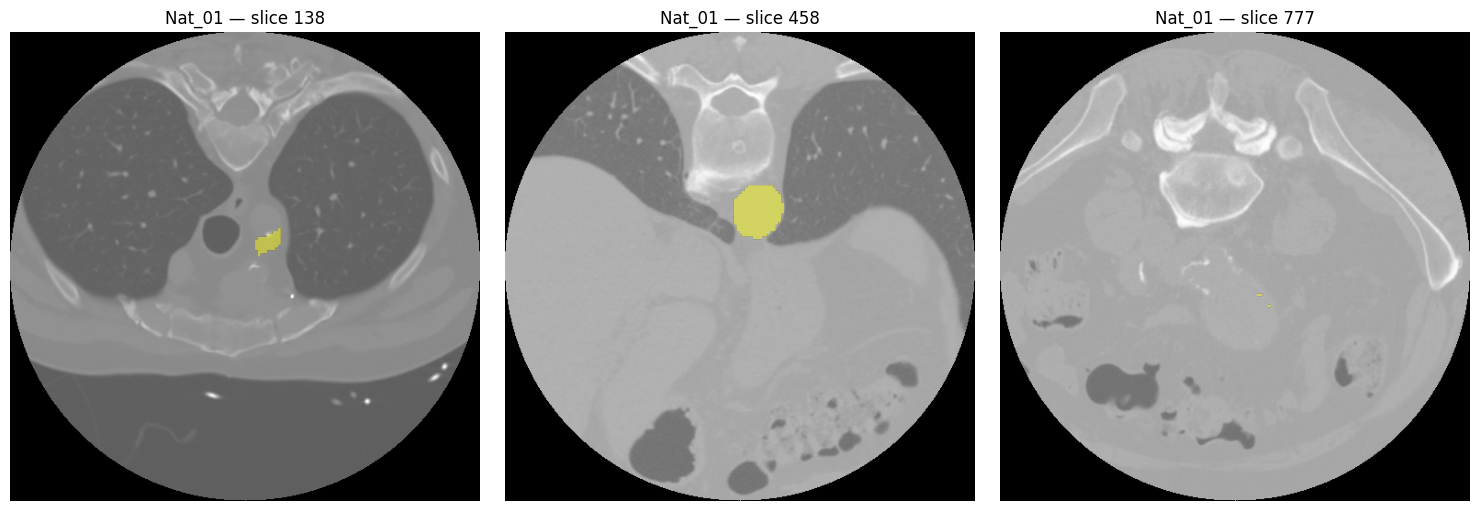

Overlay saved: /kaggle/working/Nat_01_overlay_check.png


In [15]:
import os
import numpy as np
import SimpleITK as sitk
import matplotlib.pyplot as plt

case = "Nat_01"
base = "/kaggle/working/aortaseg_remaining/Nat"
mask_dir = "/kaggle/working/nat_corrected_candidates"

ct_img = sitk.ReadImage(
    f"{base}/{case}/nifti/{case}_image.nii.gz"
)
mask_img = sitk.ReadImage(
    f"{mask_dir}/{case}_candidate_mask.nii.gz"
)

ct = sitk.GetArrayFromImage(ct_img)
mask = sitk.GetArrayFromImage(mask_img) > 0

occupied = np.flatnonzero(mask.sum(axis=(1, 2)))
indices = [
    int(occupied[0]),
    int(occupied[len(occupied)//2]),
    int(occupied[-1])
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, idx in zip(axes, indices):
    ax.imshow(ct[idx], cmap="gray")
    overlay = np.ma.masked_where(~mask[idx], mask[idx])
    ax.imshow(overlay, cmap="autumn", alpha=0.45, vmin=0, vmax=1)
    ax.set_title(f"{case} — slice {idx}")
    ax.axis("off")

plt.tight_layout()

out_path = "/kaggle/working/Nat_01_overlay_check.png"
plt.savefig(out_path, dpi=150, bbox_inches="tight")
plt.show()

print("Overlay saved:", out_path)

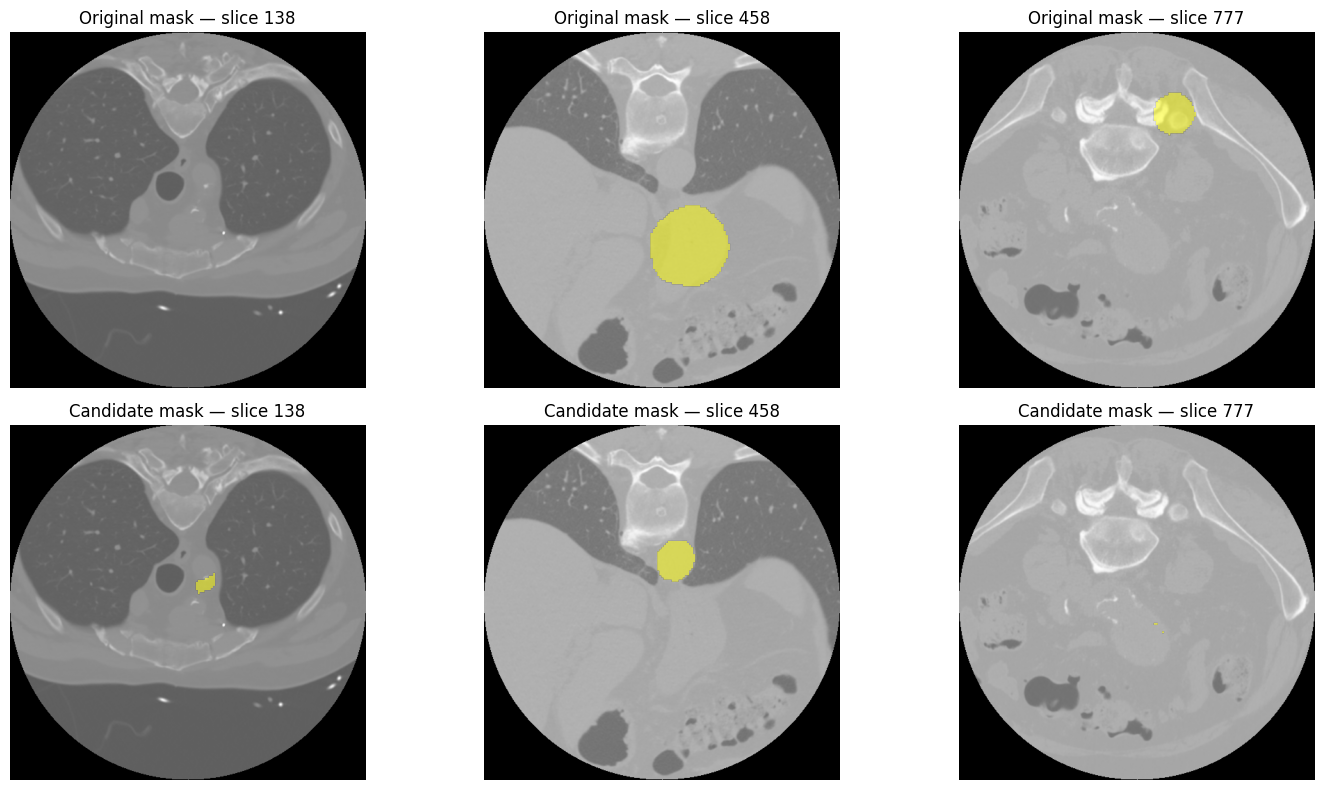

In [16]:
import os
import numpy as np
import SimpleITK as sitk
import matplotlib.pyplot as plt

case = "Nat_01"
base = "/kaggle/working/aortaseg_remaining/Nat"

ct = sitk.GetArrayFromImage(sitk.ReadImage(
    f"{base}/{case}/nifti/{case}_image.nii.gz"
))
original = sitk.GetArrayFromImage(sitk.ReadImage(
    f"{base}/{case}/segmentation/{case}_segmentation.nii.gz"
)) > 0
candidate = sitk.GetArrayFromImage(sitk.ReadImage(
    f"/kaggle/working/nat_corrected_candidates/{case}_candidate_mask.nii.gz"
)) > 0

# Use the same slice positions for a fair comparison.
indices = [138, 458, 777]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for col, idx in enumerate(indices):
    axes[0, col].imshow(ct[idx], cmap="gray")
    axes[0, col].imshow(
        np.ma.masked_where(~original[idx], original[idx]),
        cmap="autumn", alpha=0.5, vmin=0, vmax=1
    )
    axes[0, col].set_title(f"Original mask — slice {idx}")
    axes[0, col].axis("off")

    axes[1, col].imshow(ct[idx], cmap="gray")
    axes[1, col].imshow(
        np.ma.masked_where(~candidate[idx], candidate[idx]),
        cmap="autumn", alpha=0.5, vmin=0, vmax=1
    )
    axes[1, col].set_title(f"Candidate mask — slice {idx}")
    axes[1, col].axis("off")

plt.tight_layout()
plt.show()

In [17]:
import numpy as np
import SimpleITK as sitk

case = "Nat_01"
base = "/kaggle/working/aortaseg_remaining/Nat"

original = sitk.GetArrayFromImage(sitk.ReadImage(
    f"{base}/{case}/segmentation/{case}_segmentation.nii.gz"
)) > 0

candidate = sitk.GetArrayFromImage(sitk.ReadImage(
    f"/kaggle/working/nat_corrected_candidates/{case}_candidate_mask.nii.gz"
)) > 0

def dice(a, b):
    denom = a.sum() + b.sum()
    return 2 * np.logical_and(a, b).sum() / denom if denom else 1.0

print("Original foreground voxels:", int(original.sum()))
print("Candidate foreground voxels:", int(candidate.sum()))
print("Same-array Dice:", round(dice(original, candidate), 4))
print("Original first/last occupied slices:",
      np.where(original.any(axis=(1, 2)))[0][[0, -1]])
print("Candidate first/last occupied slices:",
      np.where(candidate.any(axis=(1, 2)))[0][[0, -1]])

Original foreground voxels: 4070252
Candidate foreground voxels: 4070252
Same-array Dice: 0.0361
Original first/last occupied slices: [333 972]
Candidate first/last occupied slices: [138 777]


In [18]:
import os
import numpy as np
import SimpleITK as sitk
import pandas as pd

base = "/kaggle/working/aortaseg_remaining/Nat"
rows = []

for i in range(1, 11):
    case = f"Nat_{i:02d}"

    original = sitk.GetArrayFromImage(sitk.ReadImage(
        f"{base}/{case}/segmentation/{case}_segmentation.nii.gz"
    )) > 0

    reversed_mask = original[::-1, :, :]

    dice = (
        2 * np.logical_and(original, reversed_mask).sum()
        / (original.sum() + reversed_mask.sum())
        if original.sum() + reversed_mask.sum() else 1.0
    )

    occupied = np.flatnonzero(original.any(axis=(1, 2)))
    reversed_occupied = np.flatnonzero(reversed_mask.any(axis=(1, 2)))

    rows.append({
        "case": case,
        "foreground_voxels": int(original.sum()),
        "original_first_slice": int(occupied[0]) if len(occupied) else None,
        "original_last_slice": int(occupied[-1]) if len(occupied) else None,
        "reversed_first_slice": int(reversed_occupied[0]) if len(reversed_occupied) else None,
        "reversed_last_slice": int(reversed_occupied[-1]) if len(reversed_occupied) else None,
        "same_array_dice_vs_reversal": round(float(dice), 4)
    })

df = pd.DataFrame(rows)
display(df)

report_path = "/kaggle/working/nat_reversal_comparison.csv"
df.to_csv(report_path, index=False)
print("Report saved:", report_path)

,case,foreground_voxels,original_first_slice,original_last_slice,reversed_first_slice,reversed_last_slice,same_array_dice_vs_reversal
0,Nat_01,4070252,333,972,138,777,0.0361
1,Nat_02,1660088,445,1070,127,752,0.0290
2,Nat_03,1975095,350,944,95,689,0.0414
3,Nat_04,656671,469,991,115,637,0.0253
4,Nat_05,1709509,357,906,100,649,0.0204
5,Nat_06,1165092,381,996,106,721,0.0574
6,Nat_07,715225,324,877,141,694,0.0277
7,Nat_08,2974016,472,1063,122,713,0.0206
8,Nat_09,817738,379,911,107,639,0.0184
9,Nat_10,656671,469,991,115,637,0.0253


Report saved: /kaggle/working/nat_reversal_comparison.csv


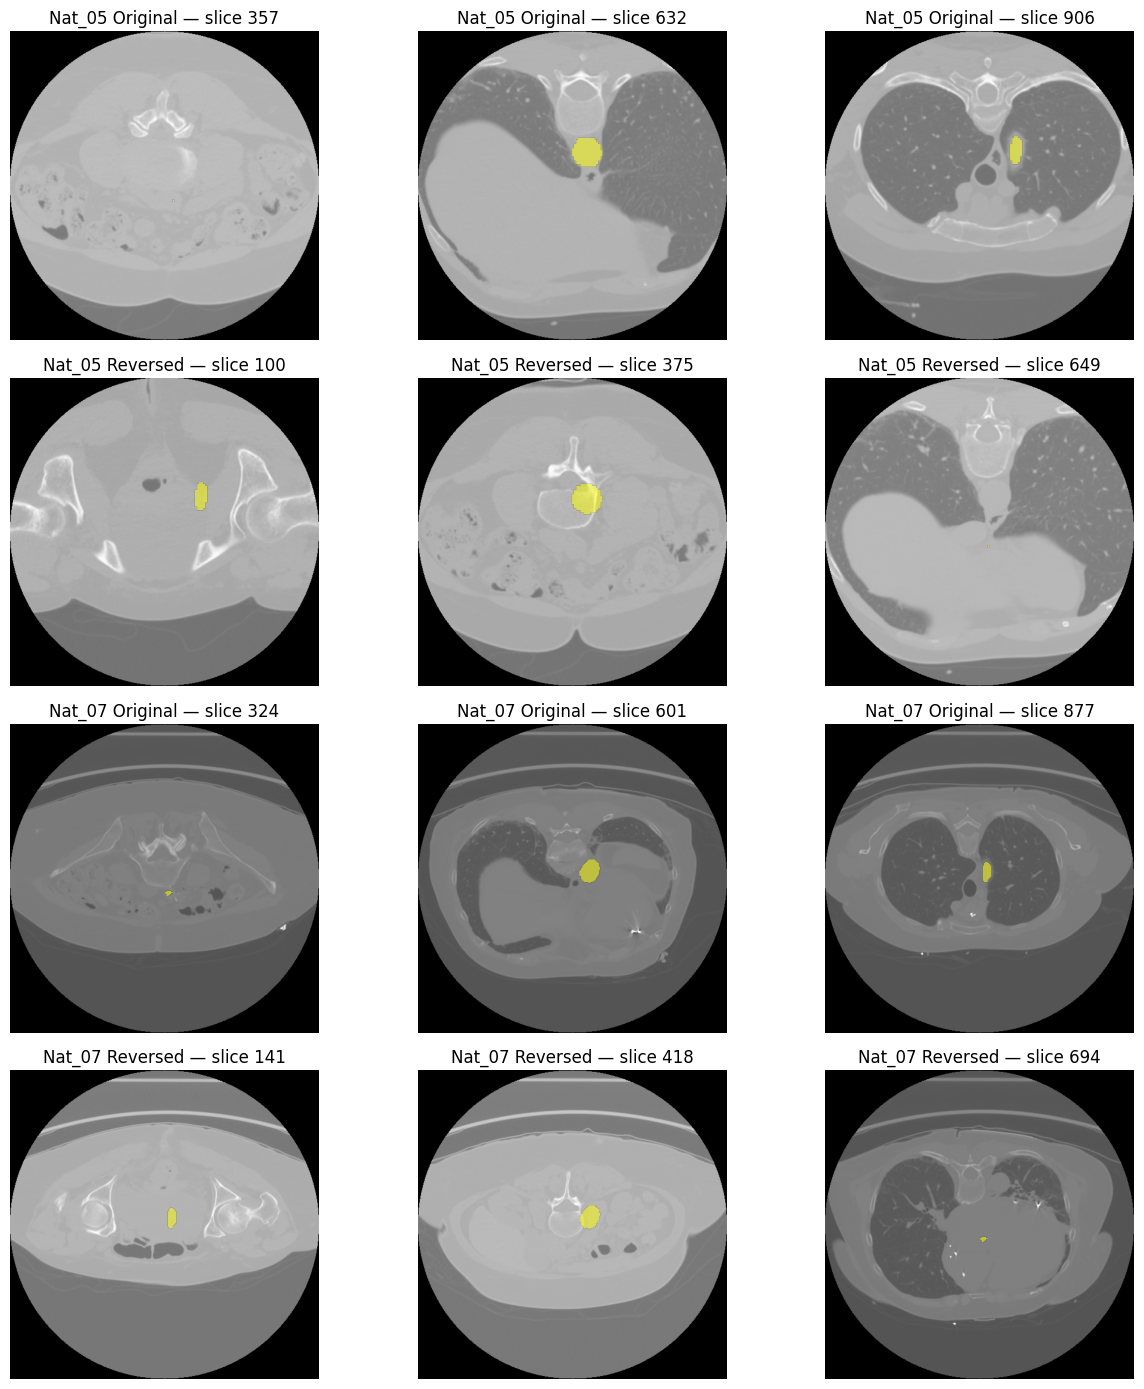

In [19]:
import os
import numpy as np
import SimpleITK as sitk
import matplotlib.pyplot as plt

base = "/kaggle/working/aortaseg_remaining/Nat"

fig, axes = plt.subplots(4, 3, figsize=(13, 14))

for row, case in enumerate(["Nat_05", "Nat_07"]):
    ct = sitk.GetArrayFromImage(sitk.ReadImage(
        f"{base}/{case}/nifti/{case}_image.nii.gz"
    ))
    original = sitk.GetArrayFromImage(sitk.ReadImage(
        f"{base}/{case}/segmentation/{case}_segmentation.nii.gz"
    )) > 0
    reversed_mask = original[::-1].copy()

    for offset, mask, label in [
        (0, original, "Original"),
        (2, reversed_mask, "Reversed")
    ]:
        occupied = np.flatnonzero(mask.any(axis=(1, 2)))
        indices = [
            int(occupied[0]),
            int(occupied[len(occupied)//2]),
            int(occupied[-1])
        ]

        for col, idx in enumerate(indices):
            ax = axes[row * 2 + offset // 2, col]
            ax.imshow(ct[idx], cmap="gray")
            ax.imshow(
                np.ma.masked_where(~mask[idx], mask[idx]),
                cmap="autumn", alpha=0.5, vmin=0, vmax=1
            )
            ax.set_title(f"{case} {label} — slice {idx}")
            ax.axis("off")

plt.tight_layout()
plt.savefig("/kaggle/working/Nat05_Nat07_orientation_check.png", dpi=140)
plt.show()

In [20]:
import os, numpy as np, torch, SimpleITK as sitk
from torch.utils.data import Dataset, DataLoader

BASE = "/kaggle/working/aortaseg_remaining/Nat"
MASKS = "/kaggle/working/nat_corrected_candidates"
CKPTS = "/kaggle/working/checkpoints"
os.makedirs(CKPTS, exist_ok=True)

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
PATCH = (64, 128, 128)

# Reuse the Small3DUNet and BCEDiceLoss definitions from your notebook.
# If these classes aren't defined in this session, stop and tell me.

class NatPatchDataset(Dataset):
    def __init__(self, cases, patches_per_case=2):
        self.cases = cases
        self.patches_per_case = patches_per_case

    def __len__(self):
        return len(self.cases) * self.patches_per_case

    def __getitem__(self, idx):
        case = self.cases[idx % len(self.cases)]
        ct = sitk.GetArrayFromImage(sitk.ReadImage(
            f"{BASE}/{case}/nifti/{case}_image.nii.gz"
        )).astype(np.float32)
        mask = sitk.GetArrayFromImage(sitk.ReadImage(
            f"{MASKS}/{case}_candidate_mask.nii.gz"
        )).astype(np.float32)

        ct = np.clip(ct, -200, 1000)
        ct = (ct + 200) / 1200

        # Random patch, favoring foreground.
        rng = np.random.default_rng()
        coords = np.argwhere(mask > 0)
        if len(coords) and rng.random() < 0.9:
            center = coords[rng.integers(len(coords))]
        else:
            center = np.array([rng.integers(s) for s in mask.shape])

        starts = [
            max(0, min(int(center[d] - PATCH[d] // 2),
                       ct.shape[d] - PATCH[d]))
            for d in range(3)
        ]
        slices = tuple(slice(starts[d], starts[d] + PATCH[d]) for d in range(3))
        x, y = ct[slices], mask[slices]

        # Pad volumes smaller than the patch, if necessary.
        pads = [(0, max(0, PATCH[d] - x.shape[d])) for d in range(3)]
        x, y = np.pad(x, pads), np.pad(y, pads)

        return (torch.from_numpy(x[None].astype(np.float32)),
                torch.from_numpy(y[None].astype(np.float32)))

train_cases = [f"Nat_{i:02d}" for i in range(1, 9)]
val_cases = ["Nat_09", "Nat_10"]
train_loader = DataLoader(
    NatPatchDataset(train_cases, 2), batch_size=1, shuffle=True, num_workers=0
)

model = Small3DUNet().to(device)
model.load_state_dict(torch.load(
    f"{CKPTS}/corovision_vessel_best.pth", map_location=device
))
criterion = BCEDiceLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=2e-5)
scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))

for epoch in range(1, 4):
    model.train()
    losses = []
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, enabled=(device.type == "cuda")):
            logits = model(x)
            loss = criterion(logits, y)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        losses.append(loss.item())

    path = f"{CKPTS}/corovision_nat_epoch_{epoch}.pth"
    torch.save(model.state_dict(), path)
    print(f"Epoch {epoch}/3 | loss={np.mean(losses):.4f} | saved={path}")

NameError: name 'Small3DUNet' is not defined

In [21]:
import os

print("Checkpoint exists:",
      os.path.exists("/kaggle/working/checkpoints/corovision_vessel_best.pth"))

print("Model class defined:", "Small3DUNet" in globals())
print("Loss class defined:", "BCEDiceLoss" in globals())

Checkpoint exists: True
Model class defined: False
Loss class defined: False


In [22]:
import torch

p = "/kaggle/working/checkpoints/corovision_vessel_best.pth"
ckpt = torch.load(p, map_location="cpu", weights_only=True)

print("Checkpoint type:", type(ckpt))
print("First keys:")
for k, v in list(ckpt.items())[:15]:
    print(k, tuple(v.shape) if hasattr(v, "shape") else type(v))

Checkpoint type: <class 'dict'>
First keys:
epoch <class 'int'>
model_state_dict <class 'collections.OrderedDict'>
mean_validation_patch_dice <class 'float'>


In [23]:
ckpt = torch.load(
    "/kaggle/working/checkpoints/corovision_vessel_best.pth",
    map_location="cpu",
    weights_only=True
)

state = ckpt["model_state_dict"]

print("Epoch:", ckpt.get("epoch"))
print("Validation patch Dice:", ckpt.get("mean_validation_patch_dice"))
print("\nModel layers:")
for name, tensor in state.items():
    print(name, tuple(tensor.shape))

Epoch: 1
Validation patch Dice: 0.7808091938495636

Model layers:
enc1.0.weight (8, 1, 3, 3, 3)
enc1.0.bias (8,)
enc1.2.weight (8, 8, 3, 3, 3)
enc1.2.bias (8,)
enc2.0.weight (16, 8, 3, 3, 3)
enc2.0.bias (16,)
enc2.2.weight (16, 16, 3, 3, 3)
enc2.2.bias (16,)
bridge.0.weight (32, 16, 3, 3, 3)
bridge.0.bias (32,)
up2.weight (32, 16, 2, 2, 2)
up2.bias (16,)
dec2.0.weight (16, 32, 3, 3, 3)
dec2.0.bias (16,)
up1.weight (16, 8, 2, 2, 2)
up1.bias (8,)
dec1.0.weight (8, 16, 3, 3, 3)
dec1.0.bias (8,)
out.weight (1, 8, 1, 1, 1)
out.bias (1,)


In [24]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class Small3DUNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.enc1 = nn.Sequential(
            nn.Conv3d(1, 8, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv3d(8, 8, 3, padding=1),
            nn.ReLU(inplace=True)
        )
        self.pool1 = nn.MaxPool3d(2)

        self.enc2 = nn.Sequential(
            nn.Conv3d(8, 16, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv3d(16, 16, 3, padding=1),
            nn.ReLU(inplace=True)
        )
        self.pool2 = nn.MaxPool3d(2)

        self.bridge = nn.Sequential(
            nn.Conv3d(16, 32, 3, padding=1),
            nn.ReLU(inplace=True)
        )

        self.up2 = nn.ConvTranspose3d(32, 16, 2, stride=2)
        self.dec2 = nn.Sequential(
            nn.Conv3d(32, 16, 3, padding=1),
            nn.ReLU(inplace=True)
        )

        self.up1 = nn.ConvTranspose3d(16, 8, 2, stride=2)
        self.dec1 = nn.Sequential(
            nn.Conv3d(16, 8, 3, padding=1),
            nn.ReLU(inplace=True)
        )

        self.out = nn.Conv3d(8, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        b = self.bridge(self.pool2(e2))

        d2 = self.up2(b)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.out(d1)


class BCEDiceLoss(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, logits, targets, eps=1e-6):
        bce = F.binary_cross_entropy_with_logits(logits, targets)
        probs = torch.sigmoid(logits)
        intersection = (probs * targets).sum(dim=(1, 2, 3, 4))
        denominator = probs.sum(dim=(1, 2, 3, 4)) + targets.sum(dim=(1, 2, 3, 4))
        dice = (2 * intersection + eps) / (denominator + eps)
        return 0.5 * bce + 0.5 * (1 - dice.mean())


device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

checkpoint = torch.load(
    "/kaggle/working/checkpoints/corovision_vessel_best.pth",
    map_location=device,
    weights_only=True
)

model = Small3DUNet().to(device)
model.load_state_dict(checkpoint["model_state_dict"])

print("Model restored successfully.")
print("Checkpoint epoch:", checkpoint["epoch"])
print("Validation patch Dice:", checkpoint["mean_validation_patch_dice"])
print("Device:", device)

Model restored successfully.
Checkpoint epoch: 1
Validation patch Dice: 0.7808091938495636
Device: cuda:0


In [25]:

import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import SimpleITK as sitk
from torch.utils.data import Dataset, DataLoader

# ============================================================
# 1. PATHS AND SETTINGS
# ============================================================
BASE = "/kaggle/working/aortaseg_remaining/Nat"
MASK_DIR = "/kaggle/working/nat_corrected_candidates"
CHECKPOINT_DIR = "/kaggle/working/checkpoints"
INITIAL_CHECKPOINT = os.path.join(
    CHECKPOINT_DIR, "corovision_vessel_best.pth"
)

os.makedirs(CHECKPOINT_DIR, exist_ok=True)

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
PATCH = (64, 128, 128)
EPOCHS = 3
PATCHES_PER_CASE = 2
BATCH_SIZE = 1
LR = 2e-5

# ============================================================
# 2. MODEL ARCHITECTURE
# ============================================================
class Small3DUNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.enc1 = nn.Sequential(
            nn.Conv3d(1, 8, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv3d(8, 8, 3, padding=1),
            nn.ReLU(inplace=True)
        )
        self.pool1 = nn.MaxPool3d(2)

        self.enc2 = nn.Sequential(
            nn.Conv3d(8, 16, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv3d(16, 16, 3, padding=1),
            nn.ReLU(inplace=True)
        )
        self.pool2 = nn.MaxPool3d(2)

        self.bridge = nn.Sequential(
            nn.Conv3d(16, 32, 3, padding=1),
            nn.ReLU(inplace=True)
        )

        self.up2 = nn.ConvTranspose3d(32, 16, 2, stride=2)
        self.dec2 = nn.Sequential(
            nn.Conv3d(32, 16, 3, padding=1),
            nn.ReLU(inplace=True)
        )

        self.up1 = nn.ConvTranspose3d(16, 8, 2, stride=2)
        self.dec1 = nn.Sequential(
            nn.Conv3d(16, 8, 3, padding=1),
            nn.ReLU(inplace=True)
        )

        self.out = nn.Conv3d(8, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        b = self.bridge(self.pool2(e2))

        d2 = self.up2(b)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.out(d1)


# ============================================================
# 3. LOSS FUNCTION
# ============================================================
class BCEDiceLoss(nn.Module):
    def forward(self, logits, targets, eps=1e-6):
        bce = F.binary_cross_entropy_with_logits(logits, targets)

        probs = torch.sigmoid(logits)
        dims = (1, 2, 3, 4)

        intersection = (probs * targets).sum(dim=dims)
        denominator = probs.sum(dim=dims) + targets.sum(dim=dims)
        dice = (2 * intersection + eps) / (denominator + eps)

        return 0.5 * bce + 0.5 * (1 - dice.mean())


# ============================================================
# 4. VALIDATE INPUT FILES
# ============================================================
if not os.path.isfile(INITIAL_CHECKPOINT):
    raise FileNotFoundError(f"Checkpoint missing: {INITIAL_CHECKPOINT}")

for i in range(1, 11):
    case = f"Nat_{i:02d}"
    ct_path = f"{BASE}/{case}/nifti/{case}_image.nii.gz"
    mask_path = f"{MASK_DIR}/{case}_candidate_mask.nii.gz"

    if not os.path.isfile(ct_path):
        raise FileNotFoundError(f"CT missing: {ct_path}")
    if not os.path.isfile(mask_path):
        raise FileNotFoundError(f"Mask missing: {mask_path}")

print("All 10 Nat CT and candidate mask files found.")
print("Device:", device)


# ============================================================
# 5. RANDOM PATCH DATASET
# ============================================================
class NatPatchDataset(Dataset):
    def __init__(self, cases, patches_per_case=2):
        self.cases = cases
        self.patches_per_case = patches_per_case

    def __len__(self):
        return len(self.cases) * self.patches_per_case

    def __getitem__(self, idx):
        case = self.cases[idx % len(self.cases)]

        ct_img = sitk.ReadImage(
            f"{BASE}/{case}/nifti/{case}_image.nii.gz"
        )
        mask_img = sitk.ReadImage(
            f"{MASK_DIR}/{case}_candidate_mask.nii.gz"
        )

        # Ensure spatial geometry agrees before extracting patches.
        if (
            ct_img.GetSize() != mask_img.GetSize()
            or ct_img.GetSpacing() != mask_img.GetSpacing()
            or ct_img.GetOrigin() != mask_img.GetOrigin()
            or ct_img.GetDirection() != mask_img.GetDirection()
        ):
            raise ValueError(f"Geometry mismatch in {case}")

        ct = sitk.GetArrayFromImage(ct_img).astype(np.float32)
        mask = (sitk.GetArrayFromImage(mask_img) > 0).astype(np.float32)

        # Same intensity normalization used in earlier experiments.
        ct = np.clip(ct, -200, 1000)
        ct = (ct + 200.0) / 1200.0

        # Sample a foreground-centered patch most of the time.
        rng = np.random.default_rng()
        coords = np.argwhere(mask > 0)

        if len(coords) > 0 and rng.random() < 0.9:
            center = coords[rng.integers(len(coords))]
        else:
            center = np.array([
                rng.integers(s) for s in mask.shape
            ])

        starts = [
            max(0, min(
                int(center[d] - PATCH[d] // 2),
                ct.shape[d] - PATCH[d]
            ))
            for d in range(3)
        ]

        slices = tuple(
            slice(starts[d], starts[d] + PATCH[d])
            for d in range(3)
        )

        x = ct[slices]
        y = mask[slices]

        # Pad safely if a dimension is smaller than the patch size.
        pads = [
            (0, max(0, PATCH[d] - x.shape[d]))
            for d in range(3)
        ]
        x = np.pad(x, pads, mode="constant")
        y = np.pad(y, pads, mode="constant")

        return (
            torch.from_numpy(x[None].astype(np.float32)),
            torch.from_numpy(y[None].astype(np.float32))
        )


# ============================================================
# 6. LOAD THE SAVED ANEV CHECKPOINT
# ============================================================
checkpoint = torch.load(
    INITIAL_CHECKPOINT,
    map_location=device,
    weights_only=True
)

model = Small3DUNet().to(device)
model.load_state_dict(checkpoint["model_state_dict"])

criterion = BCEDiceLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

amp_enabled = device.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=amp_enabled)

print("Loaded Anev checkpoint.")
print("Starting checkpoint epoch:", checkpoint.get("epoch"))
print("Previous patch Dice:", checkpoint.get("mean_validation_patch_dice"))


# ============================================================
# 7. TRAIN ON NAT_01 THROUGH NAT_08
# ============================================================
train_cases = [f"Nat_{i:02d}" for i in range(1, 9)]

train_dataset = NatPatchDataset(
    train_cases,
    patches_per_case=PATCHES_PER_CASE
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=amp_enabled
)

history = []

for epoch in range(1, EPOCHS + 1):
    model.train()
    epoch_losses = []

    for step, (x, y) in enumerate(train_loader, start=1):
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=device.type,
            enabled=amp_enabled
        ):
            logits = model(x)
            loss = criterion(logits, y)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        epoch_losses.append(float(loss.detach().cpu()))

        if step % 4 == 0 or step == len(train_loader):
            print(
                f"Epoch {epoch}/{EPOCHS} | "
                f"Step {step}/{len(train_loader)} | "
                f"Loss {epoch_losses[-1]:.4f}"
            )

    mean_loss = float(np.mean(epoch_losses))
    history.append({
        "epoch": epoch,
        "mean_training_loss": mean_loss
    })

    save_path = os.path.join(
        CHECKPOINT_DIR, f"corovision_nat_epoch_{epoch}.pth"
    )

    torch.save({
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "mean_training_loss": mean_loss,
        "source_checkpoint": "corovision_vessel_best.pth",
        "note": "Experimental Nat fine-tuning; candidate masks not fully validated."
    }, save_path)

    print(f"Epoch {epoch} complete | Mean loss: {mean_loss:.4f}")
    print("Checkpoint saved:", save_path)

print("\nNat experimental training finished.")
print("Training history:")
for row in history:
    print(row)

print(
    "Free storage (GB):",
    round(__import__("shutil").disk_usage("/kaggle/working").free / (1024**3), 2)
)


All 10 Nat CT and candidate mask files found.
Device: cuda:0
Loaded Anev checkpoint.
Starting checkpoint epoch: 1
Previous patch Dice: 0.7808091938495636
Epoch 1/3 | Step 4/16 | Loss 0.6093
Epoch 1/3 | Step 8/16 | Loss 0.4091
Epoch 1/3 | Step 12/16 | Loss 0.4943
Epoch 1/3 | Step 16/16 | Loss 0.4235
Epoch 1 complete | Mean loss: 0.5279
Checkpoint saved: /kaggle/working/checkpoints/corovision_nat_epoch_1.pth
Epoch 2/3 | Step 4/16 | Loss 0.5071
Epoch 2/3 | Step 8/16 | Loss 0.5653
Epoch 2/3 | Step 12/16 | Loss 0.6637
Epoch 2/3 | Step 16/16 | Loss 0.6714
Epoch 2 complete | Mean loss: 0.5663
Checkpoint saved: /kaggle/working/checkpoints/corovision_nat_epoch_2.pth
Epoch 3/3 | Step 4/16 | Loss 0.5931
Epoch 3/3 | Step 8/16 | Loss 0.5848
Epoch 3/3 | Step 12/16 | Loss 0.6060
Epoch 3/3 | Step 16/16 | Loss 0.4508
Epoch 3 complete | Mean loss: 0.5539
Checkpoint saved: /kaggle/working/checkpoints/corovision_nat_epoch_3.pth

Nat experimental training finished.
Training history:
{'epoch': 1, 'mean_trai

In [26]:
import os

checkpoint_dir = "/kaggle/working/checkpoints"

for epoch in range(1, 4):
    path = os.path.join(
        checkpoint_dir, f"corovision_nat_epoch_{epoch}.pth"
    )
    print(
        f"Epoch {epoch}:",
        "SAVED" if os.path.exists(path) else "MISSING"
    )

Epoch 1: SAVED
Epoch 2: SAVED
Epoch 3: SAVED


In [27]:

import os
import numpy as np
import pandas as pd
import torch
import SimpleITK as sitk

BASE = "/kaggle/working/aortaseg_remaining/Nat"
MASK_DIR = "/kaggle/working/nat_corrected_candidates"
CHECKPOINT = "/kaggle/working/checkpoints/corovision_nat_epoch_1.pth"
OUT_DIR = "/kaggle/working/nat_predictions"
os.makedirs(OUT_DIR, exist_ok=True)

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
PATCH = (64, 128, 128)

# Restore the model
checkpoint = torch.load(CHECKPOINT, map_location=device, weights_only=True)
model = Small3DUNet().to(device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

def predict_volume(volume, patch_size=PATCH):
    """Tiled 3D inference with overlap averaging."""
    d, h, w = volume.shape
    pd_, ph, pw = patch_size
    step = (32, 64, 64)

    accum = np.zeros(volume.shape, dtype=np.float32)
    counts = np.zeros(volume.shape, dtype=np.float32)

    z_starts = list(range(0, max(d - pd_, 0) + 1, step[0]))
    y_starts = list(range(0, max(h - ph, 0) + 1, step[1]))
    x_starts = list(range(0, max(w - pw, 0) + 1, step[2]))

    for starts, dim, patch_dim in [
        (z_starts, d, pd_), (y_starts, h, ph), (x_starts, w, pw)
    ]:
        if not starts or starts[-1] + patch_dim < dim:
            starts.append(max(dim - patch_dim, 0))

    with torch.no_grad():
        for z in sorted(set(z_starts)):
            for y in sorted(set(y_starts)):
                for x in sorted(set(x_starts)):
                    patch = volume[
                        z:min(z+pd_, d),
                        y:min(y+ph, h),
                        x:min(x+pw, w)
                    ]

                    pads = (
                        (0, pd_ - patch.shape[0]),
                        (0, ph - patch.shape[1]),
                        (0, pw - patch.shape[2])
                    )
                    patch = np.pad(patch, pads, mode="constant")
                    inp = torch.from_numpy(patch[None, None].astype(np.float32)).to(device)
                    probs = torch.sigmoid(model(inp))[0, 0].cpu().numpy()
                    probs = probs[:min(pd_, d-z), :min(ph, h-y), :min(pw, w-x)]

                    accum[z:z+probs.shape[0],
                          y:y+probs.shape[1],
                          x:x+probs.shape[2]] += probs
                    counts[z:z+probs.shape[0],
                           y:y+probs.shape[1],
                           x:x+probs.shape[2]] += 1

    return accum / np.maximum(counts, 1)

def dice_score(pred, target, eps=1e-6):
    return (2 * np.logical_and(pred, target).sum() + eps) / (
        pred.sum() + target.sum() + eps
    )

rows = []

for case in ["Nat_09", "Nat_10"]:
    ct_path = f"{BASE}/{case}/nifti/{case}_image.nii.gz"
    mask_path = f"{MASK_DIR}/{case}_candidate_mask.nii.gz"

    ct_img = sitk.ReadImage(ct_path)
    ref_img = sitk.ReadImage(mask_path)
    ct = sitk.GetArrayFromImage(ct_img).astype(np.float32)
    ref = sitk.GetArrayFromImage(ref_img) > 0

    ct = (np.clip(ct, -200, 1000) + 200) / 1200.0
    probabilities = predict_volume(ct)
    pred = probabilities >= 0.5

    dice = dice_score(pred, ref)
    precision = (np.logical_and(pred, ref).sum() + 1e-6) / (pred.sum() + 1e-6)
    recall = (np.logical_and(pred, ref).sum() + 1e-6) / (ref.sum() + 1e-6)

    pred_img = sitk.GetImageFromArray(pred.astype(np.uint8))
    pred_img.CopyInformation(ct_img)
    pred_path = f"{OUT_DIR}/{case}_predicted_segmentation.nii.gz"
    sitk.WriteImage(pred_img, pred_path)

    rows.append({
        "case": case,
        "dice": float(dice),
        "precision": float(precision),
        "recall": float(recall),
        "predicted_voxels": int(pred.sum()),
        "reference_voxels": int(ref.sum()),
        "prediction_path": pred_path
    })

df = pd.DataFrame(rows)
csv_path = "/kaggle/working/nat_evaluation.csv"
df.to_csv(csv_path, index=False)

display(df)
print("Evaluation saved:", csv_path)
print("Predictions saved:", OUT_DIR)
print("Reminder: metrics are provisional because candidate mask alignment is not fully validated.")


,case,dice,precision,recall,predicted_voxels,reference_voxels,prediction_path
0,Nat_09,0.020985,0.01129,0.148504,10756219,817738,/kaggle/working/nat_predictions/Nat_09_predict...
1,Nat_10,0.014566,0.00784,0.102493,8584558,656671,/kaggle/working/nat_predictions/Nat_10_predict...


Evaluation saved: /kaggle/working/nat_evaluation.csv
Predictions saved: /kaggle/working/nat_predictions
Reminder: metrics are provisional because candidate mask alignment is not fully validated.


In [28]:
import os
import zipfile
import shutil

zip_path = "/kaggle/working/nat_results_backup.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    # Predictions and evaluation
    for root, _, files in os.walk("/kaggle/working/nat_predictions"):
        for name in files:
            path = os.path.join(root, name)
            zf.write(path, os.path.relpath(path, "/kaggle/working"))

    csv_path = "/kaggle/working/nat_evaluation.csv"
    if os.path.exists(csv_path):
        zf.write(csv_path, "nat_evaluation.csv")

    # Nat checkpoints
    for epoch in range(1, 4):
        path = f"/kaggle/working/checkpoints/corovision_nat_epoch_{epoch}.pth"
        if os.path.exists(path):
            zf.write(path, f"checkpoints/corovision_nat_epoch_{epoch}.pth")

    report = "/kaggle/working/nat_reversal_comparison.csv"
    if os.path.exists(report):
        zf.write(report, "nat_reversal_comparison.csv")

print("Backup:", zip_path)
print("Size (MB):", round(os.path.getsize(zip_path) / (1024**2), 2))
print("Free storage (GB):", round(shutil.disk_usage("/kaggle/working").free / (1024**3), 2))

Backup: /kaggle/working/nat_results_backup.zip
Size (MB): 4.93
Free storage (GB): 9.24


In [29]:
import pandas as pd
import os

path = "/kaggle/working/nat_evaluation.csv"

if os.path.exists(path):
    df = pd.read_csv(path)
    print(df[[
        "case", "dice", "precision", "recall",
        "predicted_voxels", "reference_voxels"
    ]].to_string(index=False))
else:
    print("Evaluation CSV not found.")

  case     dice  precision   recall  predicted_voxels  reference_voxels
Nat_09 0.020985    0.01129 0.148504          10756219            817738
Nat_10 0.014566    0.00784 0.102493           8584558            656671


In [30]:
import nibabel as nib
import numpy as np
import os

base = "/kaggle/input/datasets/anupatigouthamteja/corovision-anev-original"
nat_base = "/kaggle/working/aortaseg_remaining/Nat"

for case in ["Nat_09", "Nat_10"]:
    ct_path = os.path.join(nat_base, case, "nifti", f"{case}_image.nii.gz")
    mask_path = os.path.join(
        "/kaggle/working/nat_corrected_candidates",
        f"{case}_candidate_mask.nii.gz"
    )
    pred_path = os.path.join(
        "/kaggle/working/nat_predictions",
        f"{case}_predicted_segmentation.nii.gz"
    )

    ct = np.asarray(nib.load(ct_path).dataobj)
    mask = np.asarray(nib.load(mask_path).dataobj)
    pred = np.asarray(nib.load(pred_path).dataobj)

    print(f"\n{case}")
    print("CT shape/range/percentiles:",
          ct.shape, (float(ct.min()), float(ct.max())),
          np.percentile(ct, [1, 50, 99]).round(2))
    print("Mask unique values:", np.unique(mask)[:10])
    print("Mask foreground voxels:", int(np.count_nonzero(mask)))
    print("Prediction unique values:", np.unique(pred)[:10])
    print("Prediction foreground voxels:", int(np.count_nonzero(pred)))


Nat_09
CT shape/range/percentiles: (512, 512, 1019) (-3024.0, 3071.0) [-3024.  -903.   454.]
Mask unique values: [0 1]
Mask foreground voxels: 817738
Prediction unique values: [0 1]
Prediction foreground voxels: 10756219

Nat_10
CT shape/range/percentiles: (512, 512, 1107) (-3024.0, 3071.0) [-3024.  -935.   333.]
Mask unique values: [0 1]
Mask foreground voxels: 656671
Prediction unique values: [0 1]
Prediction foreground voxels: 8584558


In [31]:
import os
import nibabel as nib
import numpy as np

base = "/kaggle/working/aortaseg_remaining/Nat"

for case in ["Nat_09", "Nat_10"]:
    ct_path = f"{base}/{case}/nifti/{case}_image.nii.gz"
    mask_path = (
        f"/kaggle/working/nat_corrected_candidates/"
        f"{case}_candidate_mask.nii.gz"
    )
    pred_path = (
        f"/kaggle/working/nat_predictions/"
        f"{case}_predicted_segmentation.nii.gz"
    )

    ct_img = nib.load(ct_path)
    mask_img = nib.load(mask_path)
    pred_img = nib.load(pred_path)

    ct = np.asarray(ct_img.dataobj)
    mask = np.asarray(mask_img.dataobj) > 0
    pred = np.asarray(pred_img.dataobj) > 0

    print(f"\n--- {case} ---")
    print("CT slope/intercept:", ct_img.header.get_slope_inter())
    print("CT scaling proxy percentiles:",
          np.percentile(ct, [0, 1, 10, 50, 90, 99, 100]).round(1))
    print("CT-mask shape match:", ct.shape == mask.shape)
    print("CT-mask affine match:",
          np.allclose(ct_img.affine, mask_img.affine))
    print("CT-prediction affine match:",
          np.allclose(ct_img.affine, pred_img.affine))
    print("Reference foreground fraction:", round(mask.mean(), 5))
    print("Prediction foreground fraction:", round(pred.mean(), 5))

    overlap = np.count_nonzero(mask & pred)
    print("Intersection voxels:", overlap)
    print("Dice:", round(2 * overlap / (mask.sum() + pred.sum()), 5))


--- Nat_09 ---
CT slope/intercept: (None, None)
CT scaling proxy percentiles: [-3024. -3024. -3024.  -903.    43.   454.  3071.]
CT-mask shape match: True
CT-mask affine match: True
CT-prediction affine match: True
Reference foreground fraction: 0.00306
Prediction foreground fraction: 0.04027
Intersection voxels: 121437
Dice: 0.02098

--- Nat_10 ---
CT slope/intercept: (None, None)
CT scaling proxy percentiles: [-3024. -3024. -3024.  -935.    41.   333.  3071.]
CT-mask shape match: True
CT-mask affine match: True
CT-prediction affine match: True
Reference foreground fraction: 0.00226
Prediction foreground fraction: 0.02958
Intersection voxels: 67304
Dice: 0.01457


In [32]:
import os
import nibabel as nib
import numpy as np
import torch

# Rebuild the model using the Small3DUNet definition
# already used in your notebook.
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

ckpt_path = "/kaggle/working/checkpoints/corovision_nat_epoch_1.pth"
ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)

model = Small3DUNet().to(device)
model.load_state_dict(ckpt["model_state_dict"])
model.eval()

print("Checkpoint epoch:", ckpt.get("epoch"))
print("Training loss:", ckpt.get("mean_training_loss"))
print("Model loaded successfully.")
print("Next, inspect the inference code's normalization and threshold.")

Checkpoint epoch: 1
Training loss: 0.5279369652271271
Model loaded successfully.
Next, inspect the inference code's normalization and threshold.


In [33]:
import os

roots = ["/kaggle/working"]

keywords = [
    "clip(-200",
    "1000",
    "sigmoid()",
    "threshold",
    "nat_predictions",
    "corovision_nat_epoch"
]

for root in roots:
    for folder, _, files in os.walk(root):
        for filename in files:
            if filename.endswith(".py") and not filename.startswith("correct_mask"):
                path = os.path.join(folder, filename)
                try:
                    with open(path, "r", encoding="utf-8", errors="ignore") as f:
                        lines = f.readlines()
                    matches = [
                        (i + 1, line.rstrip())
                        for i, line in enumerate(lines)
                        if any(k in line.lower() for k in keywords)
                    ]
                    if matches:
                        print(f"\n--- {path} ---")
                        for line_no, line in matches[:20]:
                            print(f"{line_no}: {line}")
                except Exception:
                    pass

In [34]:
import torch
import numpy as np
import nibabel as nib
import os

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model.eval()

base = "/kaggle/working/aortaseg_remaining/Nat"

for case in ["Nat_09", "Nat_10"]:
    ct_path = f"{base}/{case}/nifti/{case}_image.nii.gz"
    mask_path = (
        f"/kaggle/working/nat_corrected_candidates/"
        f"{case}_candidate_mask.nii.gz"
    )

    ct_img = nib.load(ct_path)
    ct = np.asarray(ct_img.dataobj, dtype=np.float32)
    mask = np.asarray(nib.load(mask_path).dataobj) > 0

    # Match the normalization used during training.
    ct = (np.clip(ct, -200, 1000) + 200) / 1200
    x = torch.from_numpy(ct).to(device)[None, None]

    # Sliding-window inference, using 64x128x128 patches.
    prob = torch.zeros_like(x)
    count = torch.zeros_like(x)
    D, H, W = ct.shape
    pd, ph, pw = 64, 128, 128
    sd, sh, sw = 32, 64, 64

    with torch.no_grad():
        for z in range(0, max(D-pd, 0)+1, sd):
            for y in range(0, max(H-ph, 0)+1, sh):
                for xx in range(0, max(W-pw, 0)+1, sw):
                    patch = x[:, :, z:z+pd, y:y+ph, xx:xx+pw]
                    p = torch.sigmoid(model(patch))
                    prob[:, :, z:z+pd, y:y+ph, xx:xx+pw] += p
                    count[:, :, z:z+pd, y:y+ph, xx:xx+pw] += 1

    # Cover final boundaries.
    if D >= pd and H >= ph and W >= pw:
        z, y, xx = D-pd, H-ph, W-pw
        with torch.no_grad():
            p = torch.sigmoid(model(x[:, :, z:, y:, xx:]))
        prob[:, :, z:, y:, xx:] += p
        count[:, :, z:, y:, xx:] += 1

    prob = (prob / count.clamp_min(1)).cpu().numpy()[0, 0]
    print(f"\n{case}")
    for t in [0.3, 0.5, 0.7, 0.9]:
        pred = prob >= t
        dice = 2*np.logical_and(pred, mask).sum() / (
            pred.sum() + mask.sum() + 1e-8
        )
        print(f"Threshold {t:.1f}: Dice={dice:.4f}, predicted voxels={pred.sum():,}")


Nat_09
Threshold 0.3: Dice=0.0401, predicted voxels=24,693,649
Threshold 0.5: Dice=0.0242, predicted voxels=10,104,250
Threshold 0.7: Dice=0.0003, predicted voxels=2,825,866
Threshold 0.9: Dice=0.0000, predicted voxels=610,664

Nat_10
Threshold 0.3: Dice=0.0320, predicted voxels=22,919,341
Threshold 0.5: Dice=0.0181, predicted voxels=8,514,775
Threshold 0.7: Dice=0.0001, predicted voxels=1,996,781
Threshold 0.9: Dice=0.0000, predicted voxels=339,997


In [35]:
import torch

print("Checkpoint source:", ckpt.get("source_checkpoint"))
print("Checkpoint note:", ckpt.get("note"))
print("Checkpoint epoch:", ckpt.get("epoch"))
print("Training loss:", ckpt.get("mean_training_loss"))
print("Model output layer:", model.out)

Checkpoint source: corovision_vessel_best.pth
Checkpoint note: Experimental Nat fine-tuning; candidate masks not fully validated.
Checkpoint epoch: 1
Training loss: 0.5279369652271271
Model output layer: Conv3d(8, 1, kernel_size=(1, 1, 1), stride=(1, 1, 1))


In [36]:
import nibabel as nib
import numpy as np
import os

base = "/kaggle/working/aortaseg_remaining/Nat"
mask_base = "/kaggle/working/nat_corrected_candidates"

for case in ["Nat_09", "Nat_10"]:
    ct = nib.load(f"{base}/{case}/nifti/{case}_image.nii.gz")
    mask = nib.load(f"{mask_base}/{case}_candidate_mask.nii.gz")

    ct_arr = np.asarray(ct.dataobj)
    mask_arr = np.asarray(mask.dataobj) > 0

    # Foreground extent along the third array axis
    ct_nonzero = np.any(ct_arr > -2000, axis=(0, 1))
    mask_nonzero = np.any(mask_arr, axis=(0, 1))

    ct_slices = np.where(ct_nonzero)[0]
    mask_slices = np.where(mask_nonzero)[0]

    print(f"\n{case}")
    print("CT slice extent:", (int(ct_slices[0]), int(ct_slices[-1])))
    print("Mask slice extent:", (int(mask_slices[0]), int(mask_slices[-1])))
    print("CT Z spacing:", ct.header.get_zooms()[2])
    print("Mask Z spacing:", mask.header.get_zooms()[2])


Nat_09
CT slice extent: (0, 1018)
Mask slice extent: (379, 911)
CT Z spacing: 0.6
Mask Z spacing: 0.6

Nat_10
CT slice extent: (0, 1106)
Mask slice extent: (115, 637)
CT Z spacing: 0.6
Mask Z spacing: 0.6


In [37]:
import nibabel as nib
import numpy as np

base = "/kaggle/working/aortaseg_remaining/Nat"
mask_base = "/kaggle/working/nat_corrected_candidates"
pred_base = "/kaggle/working/nat_predictions"

for case in ["Nat_09", "Nat_10"]:
    mask = np.asarray(nib.load(
        f"{mask_base}/{case}_candidate_mask.nii.gz"
    ).dataobj) > 0

    pred = np.asarray(nib.load(
        f"{pred_base}/{case}_predicted_segmentation.nii.gz"
    ).dataobj) > 0

    for orientation, ref in [
        ("current", mask),
        ("reversed Z", mask[:, :, ::-1])
    ]:
        intersection = np.count_nonzero(ref & pred)
        dice = 2 * intersection / (ref.sum() + pred.sum() + 1e-8)
        print(f"{case} | {orientation}: Dice={dice:.4f}")

Nat_09 | current: Dice=0.0210
Nat_09 | reversed Z: Dice=0.0276
Nat_10 | current: Dice=0.0146
Nat_10 | reversed Z: Dice=0.0327


In [38]:

import os
import numpy as np
import nibabel as nib
import pandas as pd
import matplotlib.pyplot as plt

ct_base = "/kaggle/working/aortaseg_remaining/Nat"
mask_base = "/kaggle/working/nat_corrected_candidates"
out_dir = "/kaggle/working/nat_auto_validation"
os.makedirs(out_dir, exist_ok=True)

results = []

for i in range(1, 11):
    case = f"Nat_{i:02d}"
    ct_path = f"{ct_base}/{case}/nifti/{case}_image.nii.gz"
    mask_path = f"{mask_base}/{case}_candidate_mask.nii.gz"

    if not os.path.exists(ct_path) or not os.path.exists(mask_path):
        print("Missing files:", case)
        continue

    ct_img = nib.load(ct_path)
    mask_img = nib.load(mask_path)
    ct = np.asarray(ct_img.dataobj)
    mask = np.asarray(mask_img.dataobj) > 0

    geometry_ok = (
        ct.shape == mask.shape
        and np.allclose(ct_img.affine, mask_img.affine)
    )

    original_voxels = int(mask.sum())
    reversed_mask = mask[:, :, ::-1]
    reverse_voxels = int(reversed_mask.sum())

    # Summarize foreground distribution across Z.
    original_z = np.where(mask.any(axis=(0, 1)))[0]
    reversed_z = np.where(reversed_mask.any(axis=(0, 1)))[0]

    results.append({
        "case": case,
        "geometry_match": geometry_ok,
        "ct_shape": str(ct.shape),
        "mask_voxels": original_voxels,
        "reversed_voxels": reverse_voxels,
        "original_z_start": int(original_z[0]) if len(original_z) else -1,
        "original_z_end": int(original_z[-1]) if len(original_z) else -1,
        "reversed_z_start": int(reversed_z[0]) if len(reversed_z) else -1,
        "reversed_z_end": int(reversed_z[-1]) if len(reversed_z) else -1,
    })

    # Automatically create overlays at beginning, middle, and end
    # of the mask's occupied slice range.
    if len(original_z):
        slices = sorted(set([
            int(original_z[0]),
            int(original_z[len(original_z)//2]),
            int(original_z[-1])
        ]))

        fig, axes = plt.subplots(1, len(slices), figsize=(5*len(slices), 5))
        if len(slices) == 1:
            axes = [axes]

        for ax, z in zip(axes, slices):
            # Display in radiological-style 2D orientation for inspection.
            image = np.rot90(ct[:, :, z])
            overlay = np.rot90(mask[:, :, z])
            ax.imshow(image, cmap="gray", vmin=-200, vmax=600)
            ax.contour(overlay, levels=[0.5], colors=["red"], linewidths=0.7)
            ax.set_title(f"{case} | Z={z}")
            ax.axis("off")

        plt.tight_layout()
        fig.savefig(f"{out_dir}/{case}_overlay.png", dpi=120)
        plt.close(fig)

df = pd.DataFrame(results)
csv_path = f"{out_dir}/nat_validation_report.csv"
df.to_csv(csv_path, index=False)

print("\nValidation summary:")
print(df.to_string(index=False))
print("\nReport:", csv_path)
print("Overlay images:", out_dir)



Validation summary:
  case  geometry_match         ct_shape  mask_voxels  reversed_voxels  original_z_start  original_z_end  reversed_z_start  reversed_z_end
Nat_01            True (512, 512, 1111)      4070252          4070252               138             777               333             972
Nat_02            True (512, 512, 1198)      1660088          1660088               127             752               445            1070
Nat_03            True (512, 512, 1040)      1975095          1975095                95             689               350             944
Nat_04            True (512, 512, 1107)       656671           656671               115             637               469             991
Nat_05            True (512, 512, 1007)      1709509          1709509               357             906               100             649
Nat_06            True (512, 512, 1103)      1165092          1165092               106             721               381             996
Nat_07       

In [39]:

import os
import nibabel as nib
import numpy as np
import pandas as pd
from scipy import ndimage

ct_base = "/kaggle/working/aortaseg_remaining/Nat"
mask_base = "/kaggle/working/nat_corrected_candidates"
out_dir = "/kaggle/working/nat_auto_validation"
rows = []

for i in range(1, 11):
    case = f"Nat_{i:02d}"
    path = f"{mask_base}/{case}_candidate_mask.nii.gz"
    if not os.path.exists(path):
        continue

    mask = np.asarray(nib.load(path).dataobj) > 0
    voxels_per_slice = mask.sum(axis=(0, 1))
    occupied = np.flatnonzero(voxels_per_slice)

    # Largest 3D connected component
    labels, n_components = ndimage.label(
        mask, structure=ndimage.generate_binary_structure(3, 1)
    )
    component_sizes = np.bincount(labels.ravel())[1:]
    largest_fraction = (
        component_sizes.max() / mask.sum() if mask.sum() else 0
    )

    # Slice-to-slice area variability where both slices are occupied
    adjacent = (voxels_per_slice[:-1] > 0) & (voxels_per_slice[1:] > 0)
    changes = np.abs(
        voxels_per_slice[1:][adjacent] -
        voxels_per_slice[:-1][adjacent]
    ) / np.maximum(
        voxels_per_slice[:-1][adjacent], 1
    )

    rows.append({
        "case": case,
        "foreground_voxels": int(mask.sum()),
        "occupied_slices": int(len(occupied)),
        "connected_components": int(n_components),
        "largest_component_fraction": round(float(largest_fraction), 4),
        "median_adjacent_slice_change": (
            round(float(np.median(changes)), 4) if len(changes) else np.nan
        ),
    })

df = pd.DataFrame(rows)
df.to_csv(f"{out_dir}/nat_mask_quality_report.csv", index=False)
print(df.to_string(index=False))
print("\nSaved:", f"{out_dir}/nat_mask_quality_report.csv")


  case  foreground_voxels  occupied_slices  connected_components  largest_component_fraction  median_adjacent_slice_change
Nat_01            4070252              640                     2                         1.0                           0.0
Nat_02            1660088              626                     1                         1.0                           0.0
Nat_03            1975095              595                     1                         1.0                           0.0
Nat_04             656671              523                     1                         1.0                           0.0
Nat_05            1709509              550                     1                         1.0                           0.0
Nat_06            1165092              616                     1                         1.0                           0.0
Nat_07             715225              554                     1                         1.0                           0.0
Nat_08          

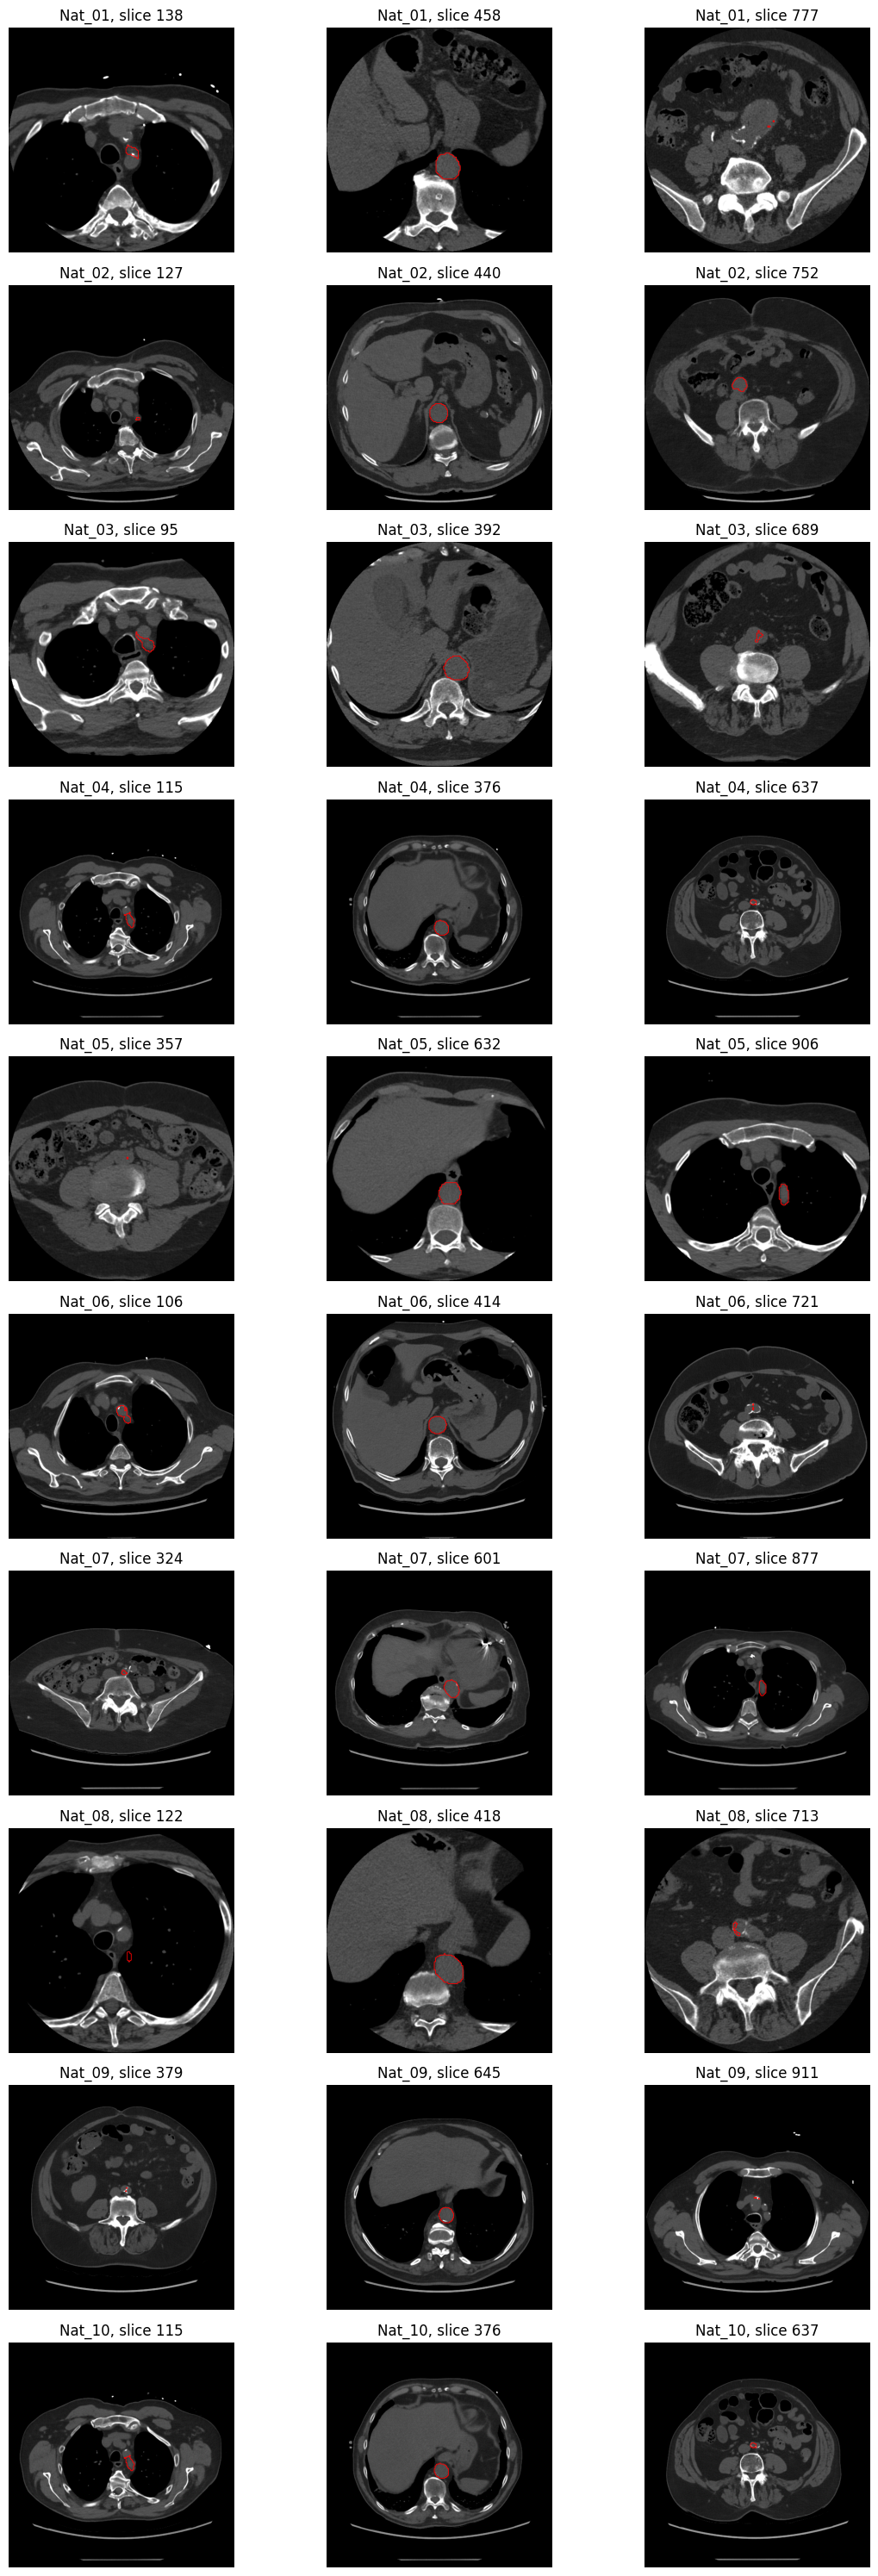

Saved contact sheet: /kaggle/working/nat_auto_validation/nat_all_cases_contact_sheet.png


In [40]:

import os
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt

ct_base = "/kaggle/working/aortaseg_remaining/Nat"
mask_base = "/kaggle/working/nat_corrected_candidates"
out_dir = "/kaggle/working/nat_auto_validation"

fig, axes = plt.subplots(10, 3, figsize=(12, 30))

for i in range(1, 11):
    case = f"Nat_{i:02d}"
    ct = np.asarray(nib.load(
        f"{ct_base}/{case}/nifti/{case}_image.nii.gz"
    ).dataobj)
    mask = np.asarray(nib.load(
        f"{mask_base}/{case}_candidate_mask.nii.gz"
    ).dataobj) > 0

    zs = np.where(mask.any(axis=(0, 1)))[0]
    sample_z = [zs[0], zs[len(zs)//2], zs[-1]]

    for j, z in enumerate(sample_z):
        ax = axes[i-1, j]
        ax.imshow(np.rot90(ct[:, :, z]), cmap="gray", vmin=-200, vmax=600)
        ax.contour(np.rot90(mask[:, :, z]), levels=[0.5],
                   colors=["red"], linewidths=0.6)
        ax.set_title(f"{case}, slice {z}")
        ax.axis("off")

plt.tight_layout()
path = f"{out_dir}/nat_all_cases_contact_sheet.png"
plt.savefig(path, dpi=100)
plt.show()
print("Saved contact sheet:", path)


In [41]:
import os
import numpy as np
import nibabel as nib
import pandas as pd

ct_base = "/kaggle/working/aortaseg_remaining/Nat"
mask_base = "/kaggle/working/nat_corrected_candidates"
out_dir = "/kaggle/working/nat_auto_validation"
rows = []

for i in range(1, 11):
    case = f"Nat_{i:02d}"
    ct_img = nib.load(f"{ct_base}/{case}/nifti/{case}_image.nii.gz")
    mask_img = nib.load(f"{mask_base}/{case}_candidate_mask.nii.gz")

    ct = np.asarray(ct_img.dataobj)
    mask = np.asarray(mask_img.dataobj) > 0
    n = mask.shape[2]
    areas = mask.sum(axis=(0, 1))
    occupied = np.flatnonzero(areas)

    rows.append({
        "case": case,
        "geometry_match": (
            ct.shape == mask.shape
            and np.allclose(ct_img.affine, mask_img.affine)
        ),
        "foreground_voxels": int(mask.sum()),
        "first_mask_slice": int(occupied[0]) if len(occupied) else -1,
        "last_mask_slice": int(occupied[-1]) if len(occupied) else -1,
        "mask_voxels_first_half_pct": round(
            100 * mask[:, :, :n//2].sum() / max(mask.sum(), 1), 2
        ),
        "mask_voxels_second_half_pct": round(
            100 * mask[:, :, n//2:].sum() / max(mask.sum(), 1), 2
        ),
        "touches_first_slice": bool(areas[0] > 0),
        "touches_last_slice": bool(areas[-1] > 0),
    })

report = pd.DataFrame(rows)
path = f"{out_dir}/nat_final_screening_report.csv"
report.to_csv(path, index=False)
print(report.to_string(index=False))
print("\nSaved:", path)

  case  geometry_match  foreground_voxels  first_mask_slice  last_mask_slice  mask_voxels_first_half_pct  mask_voxels_second_half_pct  touches_first_slice  touches_last_slice
Nat_01            True            4070252               138              777                       48.23                        51.77                False               False
Nat_02            True            1660088               127              752                       88.21                        11.79                False               False
Nat_03            True            1975095                95              689                       88.58                        11.42                False               False
Nat_04            True             656671               115              637                       96.23                         3.77                False               False
Nat_05            True            1709509               357              906                        6.77                     

In [42]:
import os
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt

ct_base = "/kaggle/working/aortaseg_remaining/Nat"
mask_base = "/kaggle/working/nat_corrected_candidates"
out_dir = "/kaggle/working/nat_auto_validation/orientation_comparison"
os.makedirs(out_dir, exist_ok=True)

for i in range(1, 11):
    case = f"Nat_{i:02d}"
    ct = np.asarray(nib.load(
        f"{ct_base}/{case}/nifti/{case}_image.nii.gz"
    ).dataobj)
    mask = np.asarray(nib.load(
        f"{mask_base}/{case}_candidate_mask.nii.gz"
    ).dataobj) > 0
    reversed_mask = mask[:, :, ::-1]

    z = mask.shape[2] // 2
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    for ax, m, title in [
        (axes[0], mask, "Current mask"),
        (axes[1], reversed_mask, "Reversed Z")
    ]:
        ax.imshow(np.rot90(ct[:, :, z]), cmap="gray",
                  vmin=-200, vmax=600)
        ax.contour(np.rot90(m[:, :, z]), levels=[0.5],
                   colors=["red"], linewidths=0.8)
        ax.set_title(f"{title}, slice {z}")
        ax.axis("off")

    fig.suptitle(case)
    fig.tight_layout()
    fig.savefig(f"{out_dir}/{case}_orientation.png", dpi=100)
    plt.close(fig)

print("Saved orientation comparisons:", out_dir)

Saved orientation comparisons: /kaggle/working/nat_auto_validation/orientation_comparison


In [43]:
import os
import zipfile

source = "/kaggle/working/nat_auto_validation"
output = "/kaggle/working/nat_validation_bundle.zip"

with zipfile.ZipFile(output, "w", zipfile.ZIP_DEFLATED) as z:
    for root, _, files in os.walk(source):
        for name in files:
            path = os.path.join(root, name)
            z.write(path, os.path.relpath(path, source))

print("Validation bundle:", output)
print("Size: {:.2f} MB".format(os.path.getsize(output) / 1024**2))

Validation bundle: /kaggle/working/nat_validation_bundle.zip
Size: 6.73 MB


In [44]:
import os

base = "/kaggle/working/aortaseg_remaining"

for category in ["Old", "Ven", "Young"]:
    path = os.path.join(base, category)
    valid = []

    if os.path.isdir(path):
        for case in sorted(os.listdir(path)):
            ct = os.path.join(path, case, "nifti", f"{case}_image.nii.gz")
            mask = os.path.join(
                path, case, "segmentation",
                f"{case}_segmentation.nii.gz"
            )
            if os.path.isfile(ct) and os.path.isfile(mask):
                valid.append(case)

    print(f"{category}: {len(valid)}/10 complete cases")

Old: 0/10 complete cases
Ven: 0/10 complete cases
Young: 0/10 complete cases


In [45]:

import os
import shutil

paths = [
    "/kaggle/working",
    "/kaggle/input",
]

print("=== DISK SPACE ===")
for path in paths:
    if os.path.exists(path):
        total, used, free = shutil.disk_usage(path)
        print(f"\n{path}")
        print(f"Total: {total / 1024**3:.2f} GB")
        print(f"Used:  {used / 1024**3:.2f} GB")
        print(f"Free:  {free / 1024**3:.2f} GB")

print("\n=== EXISTING DOWNLOADS ===")
for name in [
    "Old.zip", "Ven.zip", "Young.zip",
    "Dissec.zip", "Nat.zip",
    "nat_results_backup.zip",
    "nat_validation_bundle.zip",
]:
    path = f"/kaggle/working/{name}"
    if os.path.exists(path):
        print(f"{name}: {os.path.getsize(path) / 1024**3:.2f} GB")
    else:
        print(f"{name}: not present")

print("\n=== CATEGORY FOLDER SIZES ===")
base = "/kaggle/working/aortaseg_remaining"

for category in ["Dissec", "Nat", "Old", "Ven", "Young"]:
    path = os.path.join(base, category)
    if not os.path.isdir(path):
        print(f"{category}: not extracted")
        continue

    size = 0
    for root, _, files in os.walk(path):
        for filename in files:
            try:
                size += os.path.getsize(os.path.join(root, filename))
            except OSError:
                pass

    print(f"{category}: {size / 1024**3:.2f} GB")


=== DISK SPACE ===

/kaggle/working
Total: 19.52 GB
Used:  10.28 GB
Free:  9.23 GB

/kaggle/input
Total: 19.52 GB
Used:  10.28 GB
Free:  9.23 GB

=== EXISTING DOWNLOADS ===
Old.zip: not present
Ven.zip: not present
Young.zip: not present
Dissec.zip: not present
Nat.zip: not present
nat_results_backup.zip: 0.00 GB
nat_validation_bundle.zip: 0.01 GB

=== CATEGORY FOLDER SIZES ===
Dissec: not extracted
Nat: 2.49 GB
Old: not extracted
Ven: not extracted
Young: not extracted


In [46]:

import os
import shutil
import zipfile
import urllib.request

base = "/kaggle/working/aortaseg_remaining"
archive = "/kaggle/working/Old.zip"
os.makedirs(base, exist_ok=True)

def free_gb():
    return shutil.disk_usage("/kaggle/working").free / 1024**3

print(f"Free space before download: {free_gb():.2f} GB")

if free_gb() < 3.5:
    raise RuntimeError("Not enough free space for a safe Old download.")

url = "https://zenodo.org/records/18147026/files/Old.zip?download=1"

if not os.path.exists(archive):
    print("Downloading Old.zip...")
    urllib.request.urlretrieve(url, archive)

print(f"Downloaded ZIP: {os.path.getsize(archive)/1024**3:.2f} GB")
print("Extracting Old...")
with zipfile.ZipFile(archive, "r") as z:
    z.extractall(base)

# Verify expected CT and segmentation pairs.
cat_path = os.path.join(base, "Old")
valid = []

if os.path.isdir(cat_path):
    for case in sorted(os.listdir(cat_path)):
        ct = os.path.join(cat_path, case, "nifti", f"{case}_image.nii.gz")
        mask = os.path.join(
            cat_path, case, "segmentation", f"{case}_segmentation.nii.gz"
        )
        if os.path.isfile(ct) and os.path.isfile(mask):
            valid.append(case)

print(f"Verified CT/mask pairs: {len(valid)}/10")
print("Cases:", valid)
print(f"Free space after extraction: {free_gb():.2f} GB")

if len(valid) == 10:
    os.remove(archive)
    print("Old.zip deleted after successful verification.")
else:
    print("ZIP retained because verification was incomplete.")


Free space before download: 9.23 GB
Downloaded ZIP: 2.31 GB
Extracting Old...
Verified CT/mask pairs: 0/10
Cases: []
Free space after extraction: 4.60 GB
ZIP retained because verification was incomplete.


In [47]:
import os
import zipfile

archive = "/kaggle/working/Old.zip"
base = "/kaggle/working/aortaseg_remaining"

print("=== ZIP CONTENTS (first 40 entries) ===")
if os.path.exists(archive):
    with zipfile.ZipFile(archive) as z:
        for name in z.namelist()[:40]:
            print(name)
else:
    print("Old.zip not found")

print("\n=== EXTRACTED FOLDERS ===")
for root, dirs, files in os.walk(base):
    level = root.replace(base, "").count(os.sep)
    if level <= 3:
        print("  " * level + os.path.basename(root) + "/")
        for filename in files[:5]:
            print("  " * (level + 1) + filename)

=== ZIP CONTENTS (first 40 entries) ===
Old_01/
Old_01/.DS_Store
__MACOSX/Old_01/._.DS_Store
Old_01/segmentation/
Old_01/nifti/
Old_01/segmentation/Old_01_segmentation.nii.gz
__MACOSX/Old_01/segmentation/._Old_01_segmentation.nii.gz
Old_01/nifti/Old_01_image.nii.gz
Old_02/
Old_02/.DS_Store
__MACOSX/Old_02/._.DS_Store
Old_02/segmentation/
Old_02/nifti/
Old_02/segmentation/Old_02_segmentation.nii.gz
__MACOSX/Old_02/segmentation/._Old_02_segmentation.nii.gz
Old_02/nifti/Old_02_image.nii.gz
Old_03/
Old_03/.DS_Store
__MACOSX/Old_03/._.DS_Store
Old_03/segmentation/
Old_03/nifti/
Old_03/segmentation/Old_03_segmentation.nii.gz
__MACOSX/Old_03/segmentation/._Old_03_segmentation.nii.gz
Old_03/nifti/Old_03_image.nii.gz
Old_04/
Old_04/.DS_Store
__MACOSX/Old_04/._.DS_Store
Old_04/segmentation/
Old_04/nifti/
Old_04/segmentation/Old_04_segmentation.nii.gz
__MACOSX/Old_04/segmentation/._Old_04_segmentation.nii.gz
Old_04/nifti/Old_04_image.nii.gz
Old_05/
Old_05/.DS_Store
__MACOSX/Old_05/._.DS_Store
Old

In [48]:
import os
import shutil

base = "/kaggle/working/aortaseg_remaining"
old_dir = os.path.join(base, "Old")
os.makedirs(old_dir, exist_ok=True)

# Move extracted Old_XX folders into base/Old/
for i in range(1, 11):
    case = f"Old_{i:02d}"
    src = os.path.join(base, case)
    dst = os.path.join(old_dir, case)

    if os.path.isdir(src) and not os.path.exists(dst):
        shutil.move(src, dst)

# Verify CT/mask pairs
valid = []
for i in range(1, 11):
    case = f"Old_{i:02d}"
    ct = os.path.join(old_dir, case, "nifti", f"{case}_image.nii.gz")
    mask = os.path.join(
        old_dir, case, "segmentation", f"{case}_segmentation.nii.gz"
    )
    if os.path.isfile(ct) and os.path.isfile(mask):
        valid.append(case)

print(f"Old verified: {len(valid)}/10")
print("Cases:", valid)

archive = "/kaggle/working/Old.zip"
if len(valid) == 10 and os.path.exists(archive):
    os.remove(archive)
    print("Old.zip deleted; extracted data verified.")

free = shutil.disk_usage("/kaggle/working").free / 1024**3
print(f"Free disk space: {free:.2f} GB")

Old verified: 10/10
Cases: ['Old_01', 'Old_02', 'Old_03', 'Old_04', 'Old_05', 'Old_06', 'Old_07', 'Old_08', 'Old_09', 'Old_10']
Old.zip deleted; extracted data verified.
Free disk space: 6.91 GB


In [49]:

import os
import numpy as np
import nibabel as nib
import pandas as pd

base = "/kaggle/working/aortaseg_remaining/Old"
out_dir = "/kaggle/working/old_validation"
os.makedirs(out_dir, exist_ok=True)

rows = []

for i in range(1, 11):
    case = f"Old_{i:02d}"
    ct_path = f"{base}/{case}/nifti/{case}_image.nii.gz"
    mask_path = f"{base}/{case}/segmentation/{case}_segmentation.nii.gz"

    if not os.path.exists(ct_path) or not os.path.exists(mask_path):
        print(f"{case}: missing CT or mask")
        continue

    ct_img = nib.load(ct_path)
    mask_img = nib.load(mask_path)
    ct = np.asarray(ct_img.dataobj)
    mask = np.asarray(mask_img.dataobj)

    ct_spacing = np.array(ct_img.header.get_zooms()[:3])
    mask_spacing = np.array(mask_img.header.get_zooms()[:3])

    geometry_match = (
        ct.shape == mask.shape
        and np.allclose(ct_img.affine, mask_img.affine, atol=1e-3)
    )

    rows.append({
        "case": case,
        "shape_match": ct.shape == mask.shape,
        "spacing_match": np.allclose(ct_spacing, mask_spacing, atol=1e-4),
        "affine_match": np.allclose(ct_img.affine, mask_img.affine, atol=1e-3),
        "ct_shape": str(ct.shape),
        "ct_spacing": str(np.round(ct_spacing, 4)),
        "mask_spacing": str(np.round(mask_spacing, 4)),
        "origin_difference": str(np.round(
            ct_img.affine[:3, 3] - mask_img.affine[:3, 3], 3
        )),
        "mask_values": str(np.unique(mask)[:10]),
        "foreground_voxels": int(np.count_nonzero(mask)),
        "foreground_fraction": round(float(np.count_nonzero(mask) / mask.size), 5),
    })

df = pd.DataFrame(rows)
csv_path = f"{out_dir}/old_geometry_validation.csv"
df.to_csv(csv_path, index=False)

print(df.to_string(index=False))
print("\nCases with matching geometry:",
      int((df["shape_match"] & df["spacing_match"] & df["affine_match"]).sum()),
      "/", len(df))
print("Report saved:", csv_path)


  case  shape_match  spacing_match  affine_match         ct_shape             ct_spacing           mask_spacing   origin_difference mask_values  foreground_voxels  foreground_fraction
Old_01         True           True         False (512, 512, 1078)          [0.5 0.5 0.6]          [0.5 0.5 0.6] [  0.    0.  646.2]       [0 1]            3577957              0.01266
Old_02         True           True         False (512, 512, 1148) [0.4863 0.4863 0.6   ] [0.4863 0.4863 0.6   ] [  0.    0.  688.2]       [0 1]            2909482              0.00967
Old_03         True           True         False (512, 512, 1148) [0.5508 0.5508 0.6   ] [0.5508 0.5508 0.6   ] [  0.    0.  688.2]       [0 1]            3212659              0.01068
Old_04         True           True          True  (512, 512, 510) [0.5293 0.5293 1.25  ] [0.5293 0.5293 1.25  ]          [0. 0. 0.]       [0 1]             840601              0.00629
Old_05         True           True         False (512, 512, 1086) [0.5312 0.5312

In [50]:

import os
import numpy as np
import nibabel as nib
import pandas as pd

base = "/kaggle/working/aortaseg_remaining/Old"
rows = []

for i in range(1, 11):
    case = f"Old_{i:02d}"
    ct = nib.load(f"{base}/{case}/nifti/{case}_image.nii.gz")
    mask = nib.load(f"{base}/{case}/segmentation/{case}_segmentation.nii.gz")

    ct_origin = ct.affine[:3, 3]
    mask_origin = mask.affine[:3, 3]
    diff = ct_origin - mask_origin

    # Candidate displacement if the array order is reversed in Z.
    z_step = ct.affine[:3, 2]
    expected_reverse = z_step * (ct.shape[2] - 1)
    reverse_error = np.linalg.norm(diff - expected_reverse)
    normal_error = np.linalg.norm(diff)

    rows.append({
        "case": case,
        "origin_difference_mm": np.round(diff, 3).tolist(),
        "expected_reverse_displacement_mm": np.round(expected_reverse, 3).tolist(),
        "normal_origin_error_mm": round(float(normal_error), 3),
        "reverse_pattern_error_mm": round(float(reverse_error), 3),
        "likely_reversed_origin_pattern": bool(
            reverse_error < 2.0 and normal_error > 10.0
        )
    })

df = pd.DataFrame(rows)
print(df.to_string(index=False))
df.to_csv("/kaggle/working/old_validation/old_orientation_test.csv", index=False)
print("\nSaved orientation test report.")


  case origin_difference_mm expected_reverse_displacement_mm  normal_origin_error_mm  reverse_pattern_error_mm  likely_reversed_origin_pattern
Old_01    [0.0, 0.0, 646.2]              [-0.0, -0.0, 646.2]                   646.2                      0.00                            True
Old_02    [0.0, 0.0, 688.2]              [-0.0, -0.0, 688.2]                   688.2                      0.00                            True
Old_03    [0.0, 0.0, 688.2]              [-0.0, -0.0, 688.2]                   688.2                      0.00                            True
Old_04      [0.0, 0.0, 0.0]               [0.0, 0.0, 636.25]                     0.0                    636.25                           False
Old_05    [0.0, 0.0, 651.0]              [-0.0, -0.0, 651.0]                   651.0                      0.00                            True
Old_06    [0.0, 0.0, 625.8]              [-0.0, -0.0, 625.8]                   625.8                      0.00                            True

In [51]:

import os
import numpy as np
import nibabel as nib
import pandas as pd

base = "/kaggle/working/aortaseg_remaining/Old"
out_dir = "/kaggle/working/old_corrected_candidates"
os.makedirs(out_dir, exist_ok=True)

rows = []

for i in range(1, 11):
    case = f"Old_{i:02d}"
    ct_path = f"{base}/{case}/nifti/{case}_image.nii.gz"
    mask_path = f"{base}/{case}/segmentation/{case}_segmentation.nii.gz"

    ct_img = nib.load(ct_path)
    mask_img = nib.load(mask_path)
    mask = np.asarray(mask_img.dataobj)

    diff = ct_img.affine[:3, 3] - mask_img.affine[:3, 3]
    expected = ct_img.affine[:3, 2] * (ct_img.shape[2] - 1)
    reverse_match = (
        np.linalg.norm(diff - expected) < 2.0
        and np.linalg.norm(diff) > 10.0
    )

    if reverse_match:
        corrected = mask[:, :, ::-1].copy()
        action = "reversed_Z_and_CT_metadata"
    else:
        corrected = mask.copy()
        action = "unchanged_array_CT_metadata"

    # Candidate only: use CT affine/header for spatial metadata.
    out_img = nib.Nifti1Image(
        corrected.astype(np.uint8),
        ct_img.affine,
        header=ct_img.header.copy()
    )
    out_img.set_data_dtype(np.uint8)

    out_path = f"{out_dir}/{case}_candidate_mask.nii.gz"
    nib.save(out_img, out_path)

    rows.append({
        "case": case,
        "action": action,
        "candidate_path": out_path,
        "foreground_voxels": int(np.count_nonzero(corrected))
    })

df = pd.DataFrame(rows)
df.to_csv(f"{out_dir}/old_candidate_report.csv", index=False)
print(df[["case", "action", "foreground_voxels"]].to_string(index=False))
print("\nCandidates saved:", out_dir)


  case                      action  foreground_voxels
Old_01  reversed_Z_and_CT_metadata            3577957
Old_02  reversed_Z_and_CT_metadata            2909482
Old_03  reversed_Z_and_CT_metadata            3212659
Old_04 unchanged_array_CT_metadata             840601
Old_05  reversed_Z_and_CT_metadata            1350656
Old_06  reversed_Z_and_CT_metadata             532841
Old_07  reversed_Z_and_CT_metadata            1782117
Old_08  reversed_Z_and_CT_metadata             583553
Old_09 unchanged_array_CT_metadata            1274172
Old_10  reversed_Z_and_CT_metadata             880608

Candidates saved: /kaggle/working/old_corrected_candidates


In [52]:

import os
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt

base = "/kaggle/working/aortaseg_remaining/Old"
mask_base = "/kaggle/working/old_corrected_candidates"
out_dir = "/kaggle/working/old_validation/overlays"
os.makedirs(out_dir, exist_ok=True)

for i in range(1, 11):
    case = f"Old_{i:02d}"
    ct = np.asarray(nib.load(
        f"{base}/{case}/nifti/{case}_image.nii.gz"
    ).dataobj)
    mask = np.asarray(nib.load(
        f"{mask_base}/{case}_candidate_mask.nii.gz"
    ).dataobj) > 0

    z_indices = np.flatnonzero(mask.any(axis=(0, 1)))
    if len(z_indices) == 0:
        print(case, "empty mask — skipped")
        continue

    slices = sorted(set([
        int(z_indices[0]),
        int(z_indices[len(z_indices)//2]),
        int(z_indices[-1])
    ]))

    fig, axes = plt.subplots(1, len(slices), figsize=(12, 4))
    if len(slices) == 1:
        axes = [axes]

    for ax, z in zip(axes, slices):
        ax.imshow(np.rot90(ct[:, :, z]), cmap="gray", vmin=-200, vmax=600)
        ax.contour(np.rot90(mask[:, :, z]), levels=[0.5],
                   colors=["red"], linewidths=0.7)
        ax.set_title(f"{case}, Z={z}")
        ax.axis("off")

    fig.tight_layout()
    fig.savefig(f"{out_dir}/{case}_overlay.png", dpi=100)
    plt.close(fig)

print("Overlay images saved to:", out_dir)
print("Generated cases:", len([
    f for f in os.listdir(out_dir) if f.endswith(".png")
]))


Overlay images saved to: /kaggle/working/old_validation/overlays
Generated cases: 10


In [53]:

import os
import numpy as np
import nibabel as nib
import pandas as pd

base = "/kaggle/working/aortaseg_remaining/Old"
candidate_dir = "/kaggle/working/old_corrected_candidates"
rows = []

for i in range(1, 11):
    case = f"Old_{i:02d}"
    ct = nib.load(f"{base}/{case}/nifti/{case}_image.nii.gz")
    candidate = nib.load(
        f"{candidate_dir}/{case}_candidate_mask.nii.gz"
    )

    mask = np.asarray(candidate.dataobj) > 0

    rows.append({
        "case": case,
        "shape_match": ct.shape == candidate.shape,
        "affine_match": np.allclose(ct.affine, candidate.affine, atol=1e-3),
        "spacing_match": np.allclose(
            ct.header.get_zooms()[:3],
            candidate.header.get_zooms()[:3],
            atol=1e-4
        ),
        "foreground_voxels": int(mask.sum()),
        "nonempty": bool(mask.any()),
    })

df = pd.DataFrame(rows)
print(df.to_string(index=False))
print("\nGeometry-matched cases:",
      int((df["shape_match"] & df["affine_match"] & df["spacing_match"]).sum()),
      "/", len(df))


  case  shape_match  affine_match  spacing_match  foreground_voxels  nonempty
Old_01         True          True           True            3577957      True
Old_02         True          True           True            2909482      True
Old_03         True          True           True            3212659      True
Old_04         True          True           True             840601      True
Old_05         True          True           True            1350656      True
Old_06         True          True           True             532841      True
Old_07         True          True           True            1782117      True
Old_08         True          True           True             583553      True
Old_09         True          True           True            1274172      True
Old_10         True          True           True             880608      True

Geometry-matched cases: 10 / 10


In [54]:

import os, random
import numpy as np
import nibabel as nib
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# Configuration
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
BASE = "/kaggle/working/aortaseg_remaining/Old"
MASKS = "/kaggle/working/old_corrected_candidates"
CKPT = "/kaggle/working/checkpoints/corovision_vessel_best.pth"
OUT = "/kaggle/working/checkpoints"
os.makedirs(OUT, exist_ok=True)

assert os.path.isfile(CKPT), f"Checkpoint missing: {CKPT}"

# Verify all files and geometry before training
cases = [f"Old_{i:02d}" for i in range(1, 11)]
for case in cases:
    ct_path = f"{BASE}/{case}/nifti/{case}_image.nii.gz"
    mask_path = f"{MASKS}/{case}_candidate_mask.nii.gz"
    assert os.path.isfile(ct_path) and os.path.isfile(mask_path), case
    ct_img, mask_img = nib.load(ct_path), nib.load(mask_path)
    assert ct_img.shape == mask_img.shape, f"Shape mismatch: {case}"
    assert np.allclose(ct_img.affine, mask_img.affine, atol=1e-3), \
        f"Affine mismatch: {case}"
    assert np.asarray(mask_img.dataobj).sum() > 0, f"Empty mask: {case}"

# Fixed patient-level split: 8 train, 2 validation.
# Validation cases are excluded from all gradient updates.
train_cases = cases[:8]
val_cases = cases[8:]
print("Training:", train_cases)
print("Validation:", val_cases)
print("Device:", device)

PATCH = (64, 128, 128)
PATCHES_PER_CASE = 8
BATCH_SIZE = 1
EPOCHS = 20
LR = 1e-5

class OldPatches(Dataset):
    def __init__(self, selected_cases):
        self.items = []
        for case in selected_cases:
            ct = np.asarray(nib.load(
                f"{BASE}/{case}/nifti/{case}_image.nii.gz"
            ).dataobj, dtype=np.float32)
            mask = np.asarray(nib.load(
                f"{MASKS}/{case}_candidate_mask.nii.gz"
            ).dataobj, dtype=np.uint8)

            # Consistent CT normalization
            ct = (np.clip(ct, -200, 1000) + 200) / 1200.0
            self.items.append((case, ct, mask))

        self.indices = [
            (j, k)
            for j in range(len(self.items))
            for k in range(PATCHES_PER_CASE)
        ]

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        j, _ = self.indices[idx]
        _, ct, mask = self.items[j]
        D, H, W = ct.shape
        pd, ph, pw = PATCH
        rng = np.random.default_rng()

        # Mostly sample patches containing foreground.
        for _ in range(20):
            z = int(rng.integers(0, D-pd+1))
            y = int(rng.integers(0, H-ph+1))
            x = int(rng.integers(0, W-pw+1))
            m = mask[z:z+pd, y:y+ph, x:x+pw]
            if m.any():
                break

        a = ct[z:z+pd, y:y+ph, x:x+pw].copy()
        b = mask[z:z+pd, y:y+ph, x:x+pw].astype(np.float32, copy=True)
        return torch.from_numpy(a[None]), torch.from_numpy(b[None])

train_ds = OldPatches(train_cases)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE,
                          shuffle=True, num_workers=0)

# Load pretrained model
checkpoint = torch.load(CKPT, map_location=device, weights_only=False)
model = Small3DUNet().to(device)
model.load_state_dict(checkpoint["model_state_dict"])
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

def seg_loss(logits, target):
    bce = F.binary_cross_entropy_with_logits(logits, target)
    p = torch.sigmoid(logits)
    dims = (1, 2, 3, 4)
    dice = (2 * (p*target).sum(dims) + 1) / (
        p.sum(dims) + target.sum(dims) + 1
    )
    return 0.5*bce + 0.5*(1-dice.mean())

# Full-volume sliding-window evaluation on held-out patients.
@torch.no_grad()
def evaluate_case(case):
    model.eval()
    ct = np.asarray(nib.load(
        f"{BASE}/{case}/nifti/{case}_image.nii.gz"
    ).dataobj, dtype=np.float32)
    gt = np.asarray(nib.load(
        f"{MASKS}/{case}_candidate_mask.nii.gz"
    ).dataobj) > 0
    ct = (np.clip(ct, -200, 1000) + 200) / 1200.0

    pd, ph, pw = PATCH
    D, H, W = ct.shape
    stride = (32, 64, 64)
    prob_sum = np.zeros(ct.shape, dtype=np.float32)
    counts = np.zeros(ct.shape, dtype=np.float32)
    starts = [
        [*range(0, max(1, dim-patch+1), step)]
        for dim, patch, step in zip(ct.shape, PATCH, stride)
    ]
    for axis, dim in enumerate(ct.shape):
        last = dim - PATCH[axis]
        if last >= 0 and starts[axis][-1] != last:
            starts[axis].append(last)

    for z in starts[0]:
        for y in starts[1]:
            for x in starts[2]:
                patch = ct[z:z+pd, y:y+ph, x:x+pw]
                if patch.shape != PATCH:
                    continue
                inp = torch.from_numpy(patch[None, None]).to(device)
                p = torch.sigmoid(model(inp))[0, 0].cpu().numpy()
                prob_sum[z:z+pd, y:y+ph, x:x+pw] += p
                counts[z:z+pd, y:y+ph, x:x+pw] += 1

    prob = prob_sum / np.maximum(counts, 1)
    pred = prob >= 0.5
    inter = np.logical_and(pred, gt).sum()
    dice = 2*inter / (pred.sum() + gt.sum() + 1e-8)
    precision = inter / (pred.sum() + 1e-8)
    recall = inter / (gt.sum() + 1e-8)
    return float(dice), float(precision), float(recall)

best_val = -1.0
history = []

for epoch in range(1, EPOCHS+1):
    model.train()
    losses = []

    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = model(x)
        loss = seg_loss(logits, y)
        loss.backward()
        optimizer.step()
        losses.append(float(loss.item()))

    # Validate on two held-out cases; no gradient updates on them.
    val_metrics = [evaluate_case(case) for case in val_cases]
    mean_val_dice = float(np.mean([m[0] for m in val_metrics]))
    mean_train_loss = float(np.mean(losses))

    record = {
        "epoch": epoch,
        "mean_training_loss": mean_train_loss,
        "mean_validation_dice": mean_val_dice,
        "validation_cases": val_cases,
        "validation_metrics": val_metrics,
    }
    history.append(record)

    latest_path = f"{OUT}/corovision_old_latest.pth"
    torch.save({
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "mean_training_loss": mean_train_loss,
        "mean_validation_dice": mean_val_dice,
        "source_checkpoint": os.path.basename(CKPT),
        "note": "Old category; candidate labels not independently confirmed."
    }, latest_path)

    if mean_val_dice > best_val:
        best_val = mean_val_dice
        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "mean_validation_dice": mean_val_dice,
            "mean_training_loss": mean_train_loss,
            "validation_cases": val_cases,
            "note": "Selected by validation Dice; candidate labels unconfirmed."
        }, f"{OUT}/corovision_old_best.pth")

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"train loss={mean_train_loss:.4f} | "
        f"validation Dice={mean_val_dice:.4f} | "
        f"best={best_val:.4f}"
    )

np.save(
    "/kaggle/working/old_training_history.npy",
    np.array(history, dtype=object),
    allow_pickle=True
)
print("\nTraining finished.")
print("Best checkpoint:", f"{OUT}/corovision_old_best.pth")
print("Latest checkpoint:", f"{OUT}/corovision_old_latest.pth")


Training: ['Old_01', 'Old_02', 'Old_03', 'Old_04', 'Old_05', 'Old_06', 'Old_07', 'Old_08']
Validation: ['Old_09', 'Old_10']
Device: cuda:0
Epoch 01/20 | train loss=0.5717 | validation Dice=0.1390 | best=0.1390
Epoch 02/20 | train loss=0.5845 | validation Dice=0.1938 | best=0.1938
Epoch 03/20 | train loss=0.5376 | validation Dice=0.2827 | best=0.2827
Epoch 04/20 | train loss=0.5062 | validation Dice=0.3141 | best=0.3141
Epoch 05/20 | train loss=0.4944 | validation Dice=0.3112 | best=0.3141
Epoch 06/20 | train loss=0.4878 | validation Dice=0.3210 | best=0.3210
Epoch 07/20 | train loss=0.5090 | validation Dice=0.3313 | best=0.3313
Epoch 08/20 | train loss=0.5000 | validation Dice=0.3315 | best=0.3315
Epoch 09/20 | train loss=0.5098 | validation Dice=0.3334 | best=0.3334
Epoch 10/20 | train loss=0.5039 | validation Dice=0.3209 | best=0.3334
Epoch 11/20 | train loss=0.5075 | validation Dice=0.3398 | best=0.3398
Epoch 12/20 | train loss=0.5189 | validation Dice=0.3315 | best=0.3398
Epoch 13/

In [2]:
import torch
import torch.nn as nn

class Small3DUNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.enc1 = nn.Sequential(
            nn.Conv3d(1, 8, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv3d(8, 8, 3, padding=1),
            nn.ReLU(inplace=True)
        )
        self.pool1 = nn.MaxPool3d(2)

        self.enc2 = nn.Sequential(
            nn.Conv3d(8, 16, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv3d(16, 16, 3, padding=1),
            nn.ReLU(inplace=True)
        )
        self.pool2 = nn.MaxPool3d(2)

        self.bridge = nn.Sequential(
            nn.Conv3d(16, 32, 3, padding=1),
            nn.ReLU(inplace=True)
        )

        self.up2 = nn.ConvTranspose3d(32, 16, 2, stride=2)
        self.dec2 = nn.Sequential(
            nn.Conv3d(32, 16, 3, padding=1),
            nn.ReLU(inplace=True)
        )

        self.up1 = nn.ConvTranspose3d(16, 8, 2, stride=2)
        self.dec1 = nn.Sequential(
            nn.Conv3d(16, 8, 3, padding=1),
            nn.ReLU(inplace=True)
        )

        self.out = nn.Conv3d(8, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        b = self.bridge(self.pool2(e2))

        d2 = self.up2(b)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.out(d1)

In [3]:

import os
import numpy as np
import nibabel as nib
import pandas as pd
import torch

BASE = "/kaggle/working/aortaseg_remaining/Old"
MASKS = "/kaggle/working/old_corrected_candidates"
CKPT = "/kaggle/working/checkpoints/corovision_old_best.pth"
OUT = "/kaggle/working/old_evaluation"
os.makedirs(OUT, exist_ok=True)

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
checkpoint = torch.load(CKPT, map_location=device, weights_only=False)

model = Small3DUNet().to(device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

PATCH = (64, 128, 128)
STRIDE = (32, 64, 64)

@torch.no_grad()
def predict_volume(ct):
    ct = (np.clip(ct.astype(np.float32), -200, 1000) + 200) / 1200.0
    D, H, W = ct.shape
    pd, ph, pw = PATCH
    sd, sh, sw = STRIDE

    def starts(dim, patch, step):
        if dim <= patch:
            return [0]
        s = list(range(0, dim - patch + 1, step))
        if s[-1] != dim - patch:
            s.append(dim - patch)
        return s

    zs, ys, xs = starts(D, pd, sd), starts(H, ph, sh), starts(W, pw, sw)
    total = np.zeros(ct.shape, dtype=np.float32)
    count = np.zeros(ct.shape, dtype=np.float32)

    for z in zs:
        for y in ys:
            for x in xs:
                patch = ct[z:z+pd, y:y+ph, x:x+pw]
                if patch.shape != PATCH:
                    continue
                inp = torch.from_numpy(patch[None, None]).to(device)
                p = torch.sigmoid(model(inp))[0, 0].cpu().numpy()
                total[z:z+pd, y:y+ph, x:x+pw] += p
                count[z:z+pd, y:y+ph, x:x+pw] += 1

    return total / np.maximum(count, 1)

rows = []
cases = [f"Old_{i:02d}" for i in range(1, 11)]

for case in cases:
    ct_img = nib.load(f"{BASE}/{case}/nifti/{case}_image.nii.gz")
    mask_img = nib.load(f"{MASKS}/{case}_candidate_mask.nii.gz")

    ct = np.asarray(ct_img.dataobj)
    gt = np.asarray(mask_img.dataobj) > 0
    prob = predict_volume(ct)

    # Standard 0.5 threshold; additional thresholds are reported too.
    pred = prob >= 0.5
    intersection = np.logical_and(pred, gt).sum()
    dice = 2 * intersection / (pred.sum() + gt.sum() + 1e-8)
    precision = intersection / (pred.sum() + 1e-8)
    recall = intersection / (gt.sum() + 1e-8)

    pred_img = nib.Nifti1Image(pred.astype(np.uint8), ct_img.affine,
                               header=ct_img.header.copy())
    pred_img.set_data_dtype(np.uint8)
    nib.save(pred_img, f"{OUT}/{case}_prediction.nii.gz")

    rows.append({
        "case": case,
        "split": "validation" if case in ["Old_09", "Old_10"] else "train",
        "dice_05": float(dice),
        "precision_05": float(precision),
        "recall_05": float(recall),
        "predicted_voxels": int(pred.sum()),
        "reference_voxels": int(gt.sum()),
        "dice_03": float(
            2*np.logical_and(prob >= 0.3, gt).sum() /
            ((prob >= 0.3).sum() + gt.sum() + 1e-8)
        ),
    })
    print(f"{case}: Dice={dice:.4f}, Precision={precision:.4f}, Recall={recall:.4f}")

df = pd.DataFrame(rows)
csv_path = f"{OUT}/old_evaluation.csv"
df.to_csv(csv_path, index=False)

print("\nCheckpoint epoch:", checkpoint.get("epoch"))
print("Checkpoint validation Dice:", checkpoint.get("mean_validation_dice"))
print("\nPer-case results:")
print(df.to_string(index=False))
print("\nMean validation Dice:",
      round(df[df["split"] == "validation"]["dice_05"].mean(), 4))
print("CSV:", csv_path)
print("Predictions:", OUT)

Old_01: Dice=0.2687, Precision=0.1975, Recall=0.4203
Old_02: Dice=0.4508, Precision=0.3699, Recall=0.5770
Old_03: Dice=0.4424, Precision=0.3767, Recall=0.5359
Old_04: Dice=0.2354, Precision=0.1589, Recall=0.4541
Old_05: Dice=0.2724, Precision=0.1841, Recall=0.5234
Old_06: Dice=0.3658, Precision=0.2963, Recall=0.4780
Old_07: Dice=0.3623, Precision=0.2567, Recall=0.6158
Old_08: Dice=0.2475, Precision=0.1674, Recall=0.4749
Old_09: Dice=0.3949, Precision=0.3255, Recall=0.5017
Old_10: Dice=0.2929, Precision=0.2239, Recall=0.4235

Checkpoint epoch: 14
Checkpoint validation Dice: 0.34389603811462

Per-case results:
  case      split  dice_05  precision_05  recall_05  predicted_voxels  reference_voxels  dice_03
Old_01      train 0.268744      0.197528   0.420265           7612527           3577957 0.202380
Old_02      train 0.450773      0.369876   0.576965           4538467           2909482 0.317012
Old_03      train 0.442402      0.376694   0.535875           4570242           3212659 0.297

In [4]:
import os
import zipfile

output_zip = "/kaggle/working/corovision_old_final_results.zip"

files_to_include = [
    (
        "/kaggle/working/old_evaluation/old_evaluation.csv",
        "old_evaluation.csv"
    ),
    (
        "/kaggle/working/checkpoints/corovision_old_best.pth",
        "corovision_old_best.pth"
    ),
]

with zipfile.ZipFile(
    output_zip, "w", compression=zipfile.ZIP_DEFLATED
) as z:
    for path, name in files_to_include:
        if os.path.exists(path):
            z.write(path, name)
        else:
            print("Missing:", path)

    pred_dir = "/kaggle/working/old_evaluation"
    if os.path.isdir(pred_dir):
        for filename in os.listdir(pred_dir):
            if filename.endswith(".nii.gz"):
                path = os.path.join(pred_dir, filename)
                z.write(path, "predictions/" + filename)

print("ZIP created:", output_zip)
print("Size: %.2f MB" % (os.path.getsize(output_zip) / (1024**2)))

ZIP created: /kaggle/working/corovision_old_final_results.zip
Size: 12.86 MB


In [5]:
import shutil
import os

print("Free disk space: %.2f GB" % (
    shutil.disk_usage("/kaggle/working").free / (1024**3)
))

print("\nAvailable dataset categories:")
base = "/kaggle/working/aortaseg_remaining"

if os.path.exists(base):
    for category in sorted(os.listdir(base)):
        path = os.path.join(base, category)
        if os.path.isdir(path):
            print(category, "—", len(os.listdir(path)), "items")

Free disk space: 6.86 GB

Available dataset categories:
Nat — 10 items
Old — 10 items
__MACOSX — 10 items


In [6]:
import os

roots = [
    "/kaggle/input/datasets/anupatigouthamteja/corovision-anev-original",
    "/kaggle/input/datasets/anupatigouthamteja/corovision-preprocessed-backup",
    "/kaggle/input/datasets/anupatigouthamteja/corovision-essential-backup",
    "/kaggle/working/aortaseg_remaining"
]

for root in roots:
    print(f"\n{root}")
    if os.path.exists(root):
        for item in os.listdir(root):
            if "ven" in item.lower() or "young" in item.lower():
                print("  Found:", item)
    else:
        print("  Not found")


/kaggle/input/datasets/anupatigouthamteja/corovision-anev-original

/kaggle/input/datasets/anupatigouthamteja/corovision-preprocessed-backup

/kaggle/input/datasets/anupatigouthamteja/corovision-essential-backup

/kaggle/working/aortaseg_remaining


In [8]:
import os

roots = [
    "/kaggle/input",
    "/kaggle/working"
]

for root in roots:
    print(f"\nSearching {root}...")
    for current, dirs, files in os.walk(root):
        dirs[:] = [d for d in dirs if d != "__MACOSX"]
        for filename in files:
            name = filename.lower()
            if ("ven" in name or "young" in name) and (
                name.endswith(".zip") or name.endswith(".nii.gz")
            ):
                print(os.path.join(current, filename))


Searching /kaggle/input...

Searching /kaggle/working...


In [ ]:
import os
import subprocess

url = "https://zenodo.org/records/18147026/files/Ven.zip?download=1"
output = "/kaggle/working/Ven.zip"

print("Downloading Ven dataset...")
result = subprocess.run([
    "wget", "-c", "--show-progress",
    url, "-O", output
])

if result.returncode == 0 and os.path.exists(output):
    print(f"\nDownload finished: {os.path.getsize(output) / (1024**3):.2f} GB")
else:
    print("Download failed or was interrupted. Check the output above.")

--2026-10-21 07:48:25--  https://zenodo.org/records/18147026/files/Ven.zip?download=1
Resolving zenodo.org (zenodo.org)... 188.185.42.113, 137.138.121.78, 188.185.47.192, ...
Connecting to zenodo.org (zenodo.org)|188.185.42.113|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 2715652227 (2.5G) [application/octet-stream]
Saving to: ‘/kaggle/working/Ven.zip’

     0K .......... .......... .......... .......... ..........  0%  244K 3h1m
    50K .......... .......... .......... .......... ..........  0%  511K 2h13m
   100K .......... .......... .......... .......... ..........  0% 9.27M 90m45s
   150K .......... .......... .......... .......... ..........  0%  537K 88m37s
   200K .......... .......... .......... .......... ..........  0%  510K 88m14s
   250K .......... .......... .......... .......... ..........  0%  153M 73m35s
   300K .......... .......... .......... .......... ..........  0%  510K 75m27s
   350K .......... .......... .......... .......... ......

In [10]:
import os

path = "/kaggle/working/Ven.zip"

if os.path.exists(path):
    print(f"Current file size: {os.path.getsize(path) / (1024**3):.2f} GB")
else:
    print("Ven.zip not found")

Current file size: 2.53 GB


In [11]:
import os
import zipfile

path = "/kaggle/working/Ven.zip"

print(f"File size: {os.path.getsize(path) / (1024**3):.2f} GB")

with zipfile.ZipFile(path, "r") as z:
    bad_file = z.testzip()

if bad_file is None:
    print("SUCCESS: ZIP integrity check passed.")
else:
    print("ERROR: Corrupted file:", bad_file)

File size: 2.53 GB
SUCCESS: ZIP integrity check passed.


In [12]:
import os
import zipfile
import shutil

zip_path = "/kaggle/working/Ven.zip"
extract_dir = "/kaggle/working/aortaseg_remaining/Ven"

os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_dir)

print("Extraction complete.")
print("Items extracted:", len(os.listdir(extract_dir)))
print("Free disk space: %.2f GB" % (
    shutil.disk_usage("/kaggle/working").free / (1024**3)
))

print("\nFirst few items:")
print(os.listdir(extract_dir)[:10])

Extraction complete.
Items extracted: 11
Free disk space: 1.79 GB

First few items:
['Ven_06', 'Ven_02', '__MACOSX', 'Ven_08', 'Ven_04', 'Ven_07', 'Ven_03', 'Ven_09', 'Ven_05', 'Ven_10']


In [13]:
import os
import shutil

base = "/kaggle/working/aortaseg_remaining/Ven"
zip_path = "/kaggle/working/Ven.zip"

cases = sorted(
    d for d in os.listdir(base)
    if d.startswith("Ven_") and os.path.isdir(os.path.join(base, d))
)

print("Ven case folders:", len(cases))

valid = []
for case in cases:
    folder = os.path.join(base, case)
    nii = [
        f for f in os.listdir(folder)
        if f.endswith((".nii", ".nii.gz"))
    ]
    print(case, ":", nii)
    if len(nii) >= 2:
        valid.append(case)

if len(cases) == 10 and len(valid) == 10:
    os.remove(zip_path)
    print("\nAll 10 folders contain at least two NIfTI files.")
    print("Deleted Ven.zip to reclaim disk space.")
else:
    print("\nVerification incomplete. ZIP retained.")

print("Free disk space: %.2f GB" % (
    shutil.disk_usage("/kaggle/working").free / (1024**3)
))

Ven case folders: 10
Ven_01 : []
Ven_02 : []
Ven_03 : []
Ven_04 : []
Ven_05 : []
Ven_06 : []
Ven_07 : []
Ven_08 : []
Ven_09 : []
Ven_10 : []

Verification incomplete. ZIP retained.
Free disk space: 1.79 GB


In [14]:
import os

base = "/kaggle/working/aortaseg_remaining/Ven"

for case in sorted(os.listdir(base)):
    case_path = os.path.join(base, case)
    if not os.path.isdir(case_path) or case == "__MACOSX":
        continue

    print(f"\n{case}:")
    count = 0

    for root, dirs, files in os.walk(case_path):
        dirs[:] = [d for d in dirs if d != "__MACOSX"]

        for filename in files:
            if filename.endswith((".nii", ".nii.gz")):
                print(os.path.join(root, filename))
                count += 1

    print("NIfTI files found:", count)


Ven_01:
/kaggle/working/aortaseg_remaining/Ven/Ven_01/nifti/Ven_01_image.nii.gz
/kaggle/working/aortaseg_remaining/Ven/Ven_01/segmentation/Ven_01_segmentation.nii.gz
NIfTI files found: 2

Ven_02:
/kaggle/working/aortaseg_remaining/Ven/Ven_02/nifti/Ven_02_image.nii.gz
/kaggle/working/aortaseg_remaining/Ven/Ven_02/segmentation/Ven_02_segmentation.nii.gz
NIfTI files found: 2

Ven_03:
/kaggle/working/aortaseg_remaining/Ven/Ven_03/nifti/Ven_03_image.nii.gz
/kaggle/working/aortaseg_remaining/Ven/Ven_03/segmentation/Ven_03_segmentation.nii.gz
NIfTI files found: 2

Ven_04:
/kaggle/working/aortaseg_remaining/Ven/Ven_04/nifti/Ven_04_image.nii.gz
/kaggle/working/aortaseg_remaining/Ven/Ven_04/segmentation/Ven_04_segmentation.nii.gz
NIfTI files found: 2

Ven_05:
/kaggle/working/aortaseg_remaining/Ven/Ven_05/nifti/Ven_05_image.nii.gz
/kaggle/working/aortaseg_remaining/Ven/Ven_05/segmentation/Ven_05_segmentation.nii.gz
NIfTI files found: 2

Ven_06:
/kaggle/working/aortaseg_remaining/Ven/Ven_06/nifti

In [15]:
import os
import shutil

zip_path = "/kaggle/working/Ven.zip"

if os.path.exists(zip_path):
    os.remove(zip_path)
    print("Ven.zip deleted.")
else:
    print("Ven.zip already removed.")

print("Free disk space: %.2f GB" % (
    shutil.disk_usage("/kaggle/working").free / (1024**3)
))

Ven.zip deleted.
Free disk space: 4.32 GB


In [16]:
import os
import numpy as np
import nibabel as nib
import pandas as pd

base = "/kaggle/working/aortaseg_remaining/Ven"
results = []

for i in range(1, 11):
    case = f"Ven_{i:02d}"
    folder = os.path.join(base, case)

    ct_path = os.path.join(folder, "nifti", f"{case}_image.nii.gz")
    mask_path = os.path.join(folder, "segmentation", f"{case}_segmentation.nii.gz")

    ct = nib.load(ct_path)
    mask = nib.load(mask_path)

    results.append({
        "case": case,
        "shape_match": ct.shape == mask.shape,
        "spacing_match": np.allclose(ct.header.get_zooms()[:3],
                                     mask.header.get_zooms()[:3]),
        "affine_match": np.allclose(ct.affine, mask.affine, atol=1e-3),
        "CT_shape": str(ct.shape),
        "mask_voxels": int(np.count_nonzero(np.asanyarray(mask.dataobj)))
    })

df = pd.DataFrame(results)
print(df.to_string(index=False))
print("\nShape matches:", df["shape_match"].sum(), "/ 10")
print("Affine matches:", df["affine_match"].sum(), "/ 10")

df.to_csv("/kaggle/working/ven_geometry_validation.csv", index=False)

  case  shape_match  spacing_match  affine_match         CT_shape  mask_voxels
Ven_01         True           True         False (512, 512, 1069)      3891129
Ven_02         True           True         False (512, 512, 1054)      2561373
Ven_03         True           True         False (512, 512, 1148)      2891467
Ven_04         True           True         False (512, 512, 1065)      1690451
Ven_05        False          False         False (512, 512, 1069)      1487235
Ven_06         True           True          True (512, 512, 1015)      1810851
Ven_07         True           True         False (512, 512, 1115)      1862822
Ven_08         True           True         False (512, 512, 1036)       652593
Ven_09         True           True         False (512, 512, 1136)      2814024
Ven_10         True           True         False (512, 512, 1016)      1423605

Shape matches: 9 / 10
Affine matches: 1 / 10


In [17]:
import os
import nibabel as nib
import numpy as np
import pandas as pd

base = "/kaggle/working/aortaseg_remaining/Ven"
rows = []

for i in range(1, 11):
    case = f"Ven_{i:02d}"
    folder = os.path.join(base, case)

    ct = nib.load(os.path.join(folder, "nifti", f"{case}_image.nii.gz"))
    mask = nib.load(os.path.join(folder, "segmentation", f"{case}_segmentation.nii.gz"))

    rows.append({
        "case": case,
        "CT_shape": str(ct.shape),
        "Mask_shape": str(mask.shape),
        "CT_spacing": str(np.round(ct.header.get_zooms()[:3], 3)),
        "Mask_spacing": str(np.round(mask.header.get_zooms()[:3], 3)),
        "CT_origin": str(np.round(ct.affine[:3, 3], 3)),
        "Mask_origin": str(np.round(mask.affine[:3, 3], 3)),
        "CT_orientation": str(nib.aff2axcodes(ct.affine)),
        "Mask_orientation": str(nib.aff2axcodes(mask.affine)),
    })

df = pd.DataFrame(rows)
print(df.to_string(index=False))
df.to_csv("/kaggle/working/ven_metadata_details.csv", index=False)

  case         CT_shape       Mask_shape          CT_spacing        Mask_spacing                    CT_origin                  Mask_origin  CT_orientation Mask_orientation
Ven_01 (512, 512, 1069) (512, 512, 1069) [0.486 0.486 0.6  ] [0.486 0.486 0.6  ] [ 115.013 -123.77     3.928] [ 115.013 -123.77  -636.872] ('L', 'A', 'S')  ('L', 'A', 'S')
Ven_02 (512, 512, 1054) (512, 512, 1054) [0.521 0.521 0.6  ] [0.521 0.521 0.6  ] [ 129.407 -112.197   11.289] [ 129.407 -112.197 -620.51 ] ('L', 'A', 'S')  ('L', 'A', 'S')
Ven_03 (512, 512, 1148) (512, 512, 1148)    [0.57 0.57 0.6 ]    [0.57 0.57 0.6 ] [ 141.579 -145.145   51.886] [ 141.579 -145.145 -636.314] ('L', 'A', 'S')  ('L', 'A', 'S')
Ven_04 (512, 512, 1065) (512, 512, 1065) [0.543 0.543 0.6  ] [0.543 0.543 0.6  ] [ 141.07  -168.58    67.355] [ 141.07  -168.58  -571.045] ('L', 'A', 'S')  ('L', 'A', 'S')
Ven_05 (512, 512, 1069) (512, 512, 1076) [0.521 0.521 0.6  ] [0.521 0.521 0.6  ] [ 123.875 -169.795   73.039] [ 123.875 -169.795 -567.759] (

In [18]:
import os
import numpy as np
import nibabel as nib
import pandas as pd

base = "/kaggle/working/aortaseg_remaining/Ven"
out_dir = "/kaggle/working/ven_corrected_candidates"
os.makedirs(out_dir, exist_ok=True)

reverse_cases = [
    "Ven_01", "Ven_02", "Ven_03", "Ven_04",
    "Ven_07", "Ven_08", "Ven_09"
]

rows = []

for i in range(1, 11):
    case = f"Ven_{i:02d}"
    folder = os.path.join(base, case)

    ct = nib.load(os.path.join(folder, "nifti", f"{case}_image.nii.gz"))
    mask = nib.load(os.path.join(folder, "segmentation",
                                 f"{case}_segmentation.nii.gz"))

    if ct.shape != mask.shape:
        print(f"{case}: SKIPPED — shape mismatch {ct.shape} vs {mask.shape}")
        continue

    data = np.asanyarray(mask.dataobj)

    if case in reverse_cases:
        data = data[:, :, ::-1].copy()
        action = "Z-reversed candidate"
    elif case == "Ven_06":
        action = "unchanged candidate"
    else:
        print(f"{case}: SKIPPED — requires separate investigation")
        continue

    # Preserve voxel data while assigning the CT geometry.
    header = ct.header.copy()
    header.set_data_dtype(data.dtype)
    candidate = nib.Nifti1Image(data, ct.affine, header)
    candidate.set_qform(ct.get_qform(), int(ct.header["qform_code"]))
    candidate.set_sform(ct.get_sform(), int(ct.header["sform_code"]))

    path = os.path.join(out_dir, f"{case}_candidate_mask.nii.gz")
    nib.save(candidate, path)

    rows.append({
        "case": case,
        "action": action,
        "shape": str(candidate.shape),
        "voxel_count": int(np.count_nonzero(data)),
        "affine_matches_CT": np.allclose(candidate.affine, ct.affine)
    })

report = pd.DataFrame(rows)
report.to_csv(os.path.join(out_dir, "candidate_report.csv"), index=False)
print(report.to_string(index=False))
print("\nCandidates saved to:", out_dir)

Ven_05: SKIPPED — shape mismatch (512, 512, 1069) vs (512, 512, 1076)
Ven_10: SKIPPED — requires separate investigation
  case               action            shape  voxel_count  affine_matches_CT
Ven_01 Z-reversed candidate (512, 512, 1069)      3891129               True
Ven_02 Z-reversed candidate (512, 512, 1054)      2561373               True
Ven_03 Z-reversed candidate (512, 512, 1148)      2891467               True
Ven_04 Z-reversed candidate (512, 512, 1065)      1690451               True
Ven_06  unchanged candidate (512, 512, 1015)      1810851               True
Ven_07 Z-reversed candidate (512, 512, 1115)      1862822               True
Ven_08 Z-reversed candidate (512, 512, 1036)       652593               True
Ven_09 Z-reversed candidate (512, 512, 1136)      2814024               True

Candidates saved to: /kaggle/working/ven_corrected_candidates


In [19]:
import os

p = "/kaggle/working/checkpoints/corovision_vessel_best.pth"
print("Anev checkpoint exists:", os.path.exists(p))
if os.path.exists(p):
    print("Size: %.2f MB" % (os.path.getsize(p) / (1024**2)))

Anev checkpoint exists: True
Size: 0.19 MB


In [20]:
import os
import numpy as np
import pandas as pd
import nibabel as nib
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CKPT = "/kaggle/working/checkpoints/corovision_vessel_best.pth"
DATA = "/kaggle/working/aortaseg_remaining/Ven"
MASKS = "/kaggle/working/ven_corrected_candidates"
OUT = "/kaggle/working/ven_evaluation"

os.makedirs(OUT, exist_ok=True)

checkpoint = torch.load(CKPT, map_location=device, weights_only=False)
model = Small3DUNet().to(device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

PATCH = (64, 128, 128)
STRIDE = (32, 64, 64)

def starts(length, patch, stride):
    if length <= patch:
        return [0]
    result = list(range(0, length - patch + 1, stride))
    if result[-1] != length - patch:
        result.append(length - patch)
    return result

def predict_volume(volume):
    # volume is X,Y,Z, normalized consistently with prior training
    volume = np.clip(volume, -200, 1000)
    volume = (volume + 200) / 1200
    volume = volume.astype(np.float32)

    x, y, z = volume.shape
    prob_sum = np.zeros((x, y, z), dtype=np.float32)
    count = np.zeros((x, y, z), dtype=np.float32)

    with torch.no_grad():
        for i in starts(x, PATCH[0], STRIDE[0]):
            for j in starts(y, PATCH[1], STRIDE[1]):
                for k in starts(z, PATCH[2], STRIDE[2]):
                    patch = volume[
                        i:i+PATCH[0], j:j+PATCH[1], k:k+PATCH[2]
                    ]

                    actual = patch.shape
                    pad = (
                        0, PATCH[2]-actual[2],
                        0, PATCH[1]-actual[1],
                        0, PATCH[0]-actual[0]
                    )
                    patch_t = torch.from_numpy(patch).unsqueeze(0).unsqueeze(0)
                    patch_t = torch.nn.functional.pad(patch_t, pad)
                    patch_t = patch_t.to(device)

                    pred = torch.sigmoid(model(patch_t))[0, 0]
                    pred = pred[:actual[0], :actual[1], :actual[2]]
                    pred = pred.cpu().numpy()

                    prob_sum[
                        i:i+actual[0], j:j+actual[1], k:k+actual[2]
                    ] += pred
                    count[
                        i:i+actual[0], j:j+actual[1], k:k+actual[2]
                    ] += 1

    return prob_sum / np.maximum(count, 1)

results = []
cases = [
    "Ven_01", "Ven_02", "Ven_03", "Ven_04",
    "Ven_06", "Ven_07", "Ven_08", "Ven_09"
]

for case in cases:
    print(f"Evaluating {case}...", flush=True)

    folder = os.path.join(DATA, case)
    ct_path = os.path.join(folder, "nifti", f"{case}_image.nii.gz")
    mask_path = os.path.join(MASKS, f"{case}_candidate_mask.nii.gz")

    ct_img = nib.load(ct_path)
    mask_img = nib.load(mask_path)

    ct = ct_img.get_fdata(dtype=np.float32)
    gt = np.asanyarray(mask_img.dataobj) > 0

    if ct.shape != gt.shape:
        print(f"Skipping {case}: shape mismatch")
        continue

    probability = predict_volume(ct)
    pred = probability >= 0.5

    tp = np.logical_and(pred, gt).sum()
    fp = np.logical_and(pred, ~gt).sum()
    fn = np.logical_and(~pred, gt).sum()

    dice = (2 * tp) / max(2 * tp + fp + fn, 1)
    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)

    pred_img = nib.Nifti1Image(pred.astype(np.uint8), ct_img.affine, ct_img.header)
    nib.save(pred_img, os.path.join(OUT, f"{case}_prediction.nii.gz"))

    results.append({
        "case": case,
        "dice_05": dice,
        "precision_05": precision,
        "recall_05": recall,
        "predicted_voxels": int(pred.sum()),
        "reference_voxels": int(gt.sum())
    })

    print(f"{case}: Dice={dice:.4f}, Precision={precision:.4f}, Recall={recall:.4f}", flush=True)

df = pd.DataFrame(results)
df.to_csv(os.path.join(OUT, "ven_evaluation.csv"), index=False)

print("\nMean Ven Dice:", df["dice_05"].mean())
print(df.to_string(index=False))
print("\nResults saved to:", OUT)

Evaluating Ven_01...
Ven_01: Dice=0.1244, Precision=0.0681, Recall=0.7153
Evaluating Ven_02...
Ven_02: Dice=0.0316, Precision=0.0170, Recall=0.2332
Evaluating Ven_03...
Ven_03: Dice=0.0947, Precision=0.0507, Recall=0.7100
Evaluating Ven_04...
Ven_04: Dice=0.0489, Precision=0.0253, Recall=0.7365
Evaluating Ven_06...
Ven_06: Dice=0.0494, Precision=0.0255, Recall=0.7577
Evaluating Ven_07...
Ven_07: Dice=0.0669, Precision=0.0351, Recall=0.7233
Evaluating Ven_08...
Ven_08: Dice=0.0443, Precision=0.0229, Recall=0.6503
Evaluating Ven_09...
Ven_09: Dice=0.0964, Precision=0.0516, Recall=0.7246

Mean Ven Dice: 0.06957274583974474
  case  dice_05  precision_05  recall_05  predicted_voxels  reference_voxels
Ven_01 0.124373      0.068108   0.715293          40866083           3891129
Ven_02 0.031619      0.016959   0.233154          35213431           2561373
Ven_03 0.094676      0.050719   0.710009          40476948           2891467
Ven_04 0.048907      0.025294   0.736512          49223590      

In [21]:
import os
import zipfile
import shutil

out_dir = "/kaggle/working/ven_evaluation"
zip_path = "/kaggle/working/corovision_ven_results.zip"
ckpt = "/kaggle/working/checkpoints/corovision_vessel_best.pth"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for root, _, files in os.walk(out_dir):
        for filename in files:
            path = os.path.join(root, filename)
            z.write(path, os.path.relpath(path, out_dir))

    if os.path.exists(ckpt):
        z.write(ckpt, "corovision_vessel_best.pth")

print("ZIP created:", zip_path)
print("Size: %.2f MB" % (os.path.getsize(zip_path) / (1024**2)))
print("Free disk space: %.2f GB" % (
    shutil.disk_usage("/kaggle/working").free / (1024**3)
))

ZIP created: /kaggle/working/corovision_ven_results.zip
Size: 65.02 MB
Free disk space: 4.17 GB


In [22]:
import os
import shutil

print("Free disk space: %.2f GB" % (
    shutil.disk_usage("/kaggle/working").free / (1024**3)
))

print("\nYoung dataset locations:")
for root in ["/kaggle/input", "/kaggle/working"]:
    for current, dirs, files in os.walk(root):
        dirs[:] = [d for d in dirs if d != "__MACOSX"]
        for f in files:
            if "young" in f.lower() and (
                f.lower().endswith(".zip") or f.lower().endswith(".nii.gz")
            ):
                print(os.path.join(current, f))

Free disk space: 4.17 GB

Young dataset locations:


In [23]:
import os
import subprocess

url = "https://zenodo.org/records/18147026/files/Young.zip?download=1"
path = "/kaggle/working/Young.zip"

print("Downloading Young.zip...")
result = subprocess.run([
    "wget", "-c", "--progress=dot:giga",
    url, "-O", path
])

if result.returncode == 0 and os.path.exists(path):
    print("File size: %.2f GB" % (
        os.path.getsize(path) / (1024**3)
    ))
else:
    print("Download interrupted. Rerun this cell to resume.")

--2026-10-21 08:34:56--  https://zenodo.org/records/18147026/files/Young.zip?download=1
Resolving zenodo.org (zenodo.org)... 188.185.40.132, 188.185.42.113, 137.138.121.78, ...
Connecting to zenodo.org (zenodo.org)|188.185.40.132|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 2559168858 (2.4G) [application/octet-stream]
Saving to: ‘/kaggle/working/Young.zip’

     0K ........ ........ ........ ........  1% 2.30M 17m29s
 32768K ........ ........ ........ ........  2% 3.11M 14m59s
 65536K ........ ........ ........ ........  3% 2.87M 14m23s
 98304K ........ ........ ........ ........  5% 3.99M 13m4s
131072K ........ ........ ........ ........  6% 3.55M 12m27s
163840K ........ ........ ........ ........  7% 2.92M 12m22s
196608K ........ ........ ........ ........  9% 2.77M 12m21s
229376K ........ ........ ........ ........ 10% 3.16M 12m6s
262144K ........ ........ ........ ........ 11% 2.97M 11m56s
294912K ........ ........ ........ ........ 13% 4.51M 11m22s
327

File size: 2.38 GB


.                           100% 3.49M=10m55s

2026-10-21 08:45:52 (3.73 MB/s) - ‘/kaggle/working/Young.zip’ saved [2559168858/2559168858]



In [24]:
import hashlib
import os

path = "/kaggle/working/Young.zip"
expected_md5 = "e9b02228e6c4f4a3e63c181dd2cada91"

md5 = hashlib.md5()

with open(path, "rb") as f:
    for chunk in iter(lambda: f.read(8 * 1024 * 1024), b""):
        md5.update(chunk)

actual_md5 = md5.hexdigest()

print("File size: %.2f GB" % (os.path.getsize(path) / (1024**3)))
print("Actual MD5:", actual_md5)
print("Checksum matches:", actual_md5 == expected_md5)

File size: 2.38 GB
Actual MD5: e9b02228e6c4f4a3e63c181dd2cada91
Checksum matches: True


In [25]:
import os
import zipfile
import shutil

zip_path = "/kaggle/working/Young.zip"
extract_dir = "/kaggle/working/aortaseg_remaining/Young"

print("Free space before extraction: %.2f GB" % (
    shutil.disk_usage("/kaggle/working").free / (1024**3)
))

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_dir)

cases = sorted(
    d for d in os.listdir(extract_dir)
    if d.startswith("Young_") and os.path.isdir(
        os.path.join(extract_dir, d)
    )
)

print("\nExtracted case folders:", len(cases))
print(cases)
print("Free space after extraction: %.2f GB" % (
    shutil.disk_usage("/kaggle/working").free / (1024**3)
))

Free space before extraction: 1.79 GB


OSError: [Errno 28] No space left on device

In [26]:
import os
import shutil

print("Free space: %.2f GB" % (
    shutil.disk_usage("/kaggle/working").free / (1024**3)
))

for path in [
    "/kaggle/working/Young.zip",
    "/kaggle/working/aortaseg_remaining/Young",
]:
    if os.path.exists(path):
        if os.path.isfile(path):
            print(path, "— %.2f GB" % (
                os.path.getsize(path) / (1024**3)
            ))
        else:
            print(path, "— folders:", os.listdir(path)[:15])

Free space: 0.00 GB
/kaggle/working/Young.zip — 2.38 GB
/kaggle/working/aortaseg_remaining/Young — folders: ['Young_08', 'Young_06', 'Young_02', 'Young_04', '__MACOSX', 'Young_03', 'Young_01', 'Young_07', 'Young_05']


In [27]:
import os
import shutil

partial = "/kaggle/working/aortaseg_remaining/Young"

if os.path.isdir(partial):
    shutil.rmtree(partial)
    print("Incomplete Young extraction removed.")

print("Free space: %.2f GB" % (
    shutil.disk_usage("/kaggle/working").free / (1024**3)
))

Incomplete Young extraction removed.
Free space: 1.79 GB


In [28]:
import zipfile

zip_path = "/kaggle/working/Young.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    files = z.namelist()

    for case_num in range(1, 11):
        case = f"Young_{case_num:02d}"
        matches = [
            f for f in files
            if f.startswith(case + "/")
            and f.endswith((".nii", ".nii.gz"))
        ]
        print(f"\n{case}:")
        for f in matches:
            info = z.getinfo(f)
            print(f"  {f} — {info.file_size / (1024**3):.2f} GB uncompressed")


Young_01:
  Young_01/segmentation/Young_01_segmentation.nii.gz — 0.00 GB uncompressed
  Young_01/nifti/Young_01_image.nii.gz — 0.27 GB uncompressed

Young_02:
  Young_02/segmentation/Young_02_segmentation.nii.gz — 0.00 GB uncompressed
  Young_02/nifti/Young_02_image.nii.gz — 0.27 GB uncompressed

Young_03:
  Young_03/segmentation/Young_03_segmentation.nii.gz — 0.00 GB uncompressed
  Young_03/nifti/Young_03_image.nii.gz — 0.28 GB uncompressed

Young_04:
  Young_04/segmentation/Young_04_segmentation.nii.gz — 0.00 GB uncompressed
  Young_04/nifti/Young_04_image.nii.gz — 0.26 GB uncompressed

Young_05:
  Young_05/segmentation/Young_05_segmentation.nii.gz — 0.00 GB uncompressed
  Young_05/nifti/Young_05_image.nii.gz — 0.13 GB uncompressed

Young_06:
  Young_06/segmentation/Young_06_segmentation.nii.gz — 0.00 GB uncompressed
  Young_06/nifti/Young_06_image.nii.gz — 0.24 GB uncompressed

Young_07:
  Young_07/segmentation/Young_07_segmentation.nii.gz — 0.00 GB uncompressed
  Young_07/nifti/Yo

In [29]:
import os
import zipfile
import shutil

zip_path = "/kaggle/working/Young.zip"
base = "/kaggle/working/aortaseg_remaining/Young"
case = "Young_01"

os.makedirs(base, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    members = [
        name for name in z.namelist()
        if name.startswith(case + "/")
        and not name.startswith(case + "/__MACOSX/")
        and not name.endswith("/")
    ]
    z.extractall(base, members=members)

print("Extracted:", case)
print("Free disk space: %.2f GB" % (
    shutil.disk_usage("/kaggle/working").free / (1024**3)
))

for root, _, files in os.walk(os.path.join(base, case)):
    for filename in files:
        print(os.path.join(root, filename))

Extracted: Young_01
Free disk space: 1.52 GB
/kaggle/working/aortaseg_remaining/Young/Young_01/.DS_Store
/kaggle/working/aortaseg_remaining/Young/Young_01/nifti/Young_01_image.nii.gz
/kaggle/working/aortaseg_remaining/Young/Young_01/segmentation/Young_01_segmentation.nii.gz


In [30]:
import os
import numpy as np
import nibabel as nib

base = "/kaggle/working/aortaseg_remaining/Young/Young_01"

ct_path = os.path.join(base, "nifti", "Young_01_image.nii.gz")
mask_path = os.path.join(base, "segmentation", "Young_01_segmentation.nii.gz")

ct = nib.load(ct_path)
mask = nib.load(mask_path)

print("CT shape:", ct.shape)
print("Mask shape:", mask.shape)
print("CT spacing:", ct.header.get_zooms()[:3])
print("Mask spacing:", mask.header.get_zooms()[:3])
print("CT orientation:", nib.aff2axcodes(ct.affine))
print("Mask orientation:", nib.aff2axcodes(mask.affine))
print("Affine matches:", np.allclose(ct.affine, mask.affine, atol=1e-3))
print("Mask foreground voxels:", int(np.count_nonzero(np.asanyarray(mask.dataobj))))
print("Free disk space: %.2f GB" % (
    __import__("shutil").disk_usage("/kaggle/working").free / (1024**3)
))

CT shape: (512, 512, 1148)
Mask shape: (512, 512, 1148)
CT spacing: (np.float32(0.507813), np.float32(0.507813), np.float32(0.6))
Mask spacing: (np.float32(0.507813), np.float32(0.507813), np.float32(0.6))
CT orientation: ('L', 'A', 'S')
Mask orientation: ('L', 'A', 'S')
Affine matches: False
Mask foreground voxels: 1288608
Free disk space: 1.52 GB


In [31]:
import numpy as np
import nibabel as nib

print("CT affine:\n", ct.affine)
print("\nMask affine:\n", mask.affine)

print("\nCT origin:", ct.affine[:3, 3])
print("Mask origin:", mask.affine[:3, 3])
print("Origin difference (CT - mask):",
      ct.affine[:3, 3] - mask.affine[:3, 3])

print("\nCT axis codes:", nib.aff2axcodes(ct.affine))
print("Mask axis codes:", nib.aff2axcodes(mask.affine))

CT affine:
 [[  -0.50781298    0.           -0.          124.25390625]
 [  -0.            0.50781298   -0.         -116.83853149]
 [   0.            0.            0.60000002   17.56999969]
 [   0.            0.            0.            1.        ]]

Mask affine:
 [[-5.07812977e-01 -0.00000000e+00  0.00000000e+00  1.24253906e+02]
 [ 0.00000000e+00  5.07812977e-01  0.00000000e+00 -1.16838524e+02]
 [ 0.00000000e+00 -0.00000000e+00  6.00000024e-01 -6.70630005e+02]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  1.00000000e+00]]

CT origin: [ 124.25390625 -116.83853149   17.56999969]
Mask origin: [ 124.25390625 -116.83852386 -670.63000488]
Origin difference (CT - mask): [ 0.00000000e+00 -7.62939453e-06  6.88200005e+02]

CT axis codes: ('L', 'A', 'S')
Mask axis codes: ('L', 'A', 'S')


In [32]:

import os
import gc
import zipfile
import shutil
import numpy as np
import pandas as pd
import nibabel as nib
import torch
import torch.nn.functional as F

ZIP = "/kaggle/working/Young.zip"
ROOT = "/kaggle/working/aortaseg_remaining/Young"
CKPT = "/kaggle/working/checkpoints/corovision_vessel_best.pth"
OUT = "/kaggle/working/young_evaluation"
PRED_DIR = os.path.join(OUT, "predictions")
PATCH = (64, 128, 128)
STRIDE = (32, 64, 64)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

os.makedirs(PRED_DIR, exist_ok=True)

# Small3DUNet must already be defined in your notebook.
assert os.path.exists(ZIP), f"Missing archive: {ZIP}"
assert os.path.exists(CKPT), f"Missing checkpoint: {CKPT}"
assert "Small3DUNet" in globals(), "Run the Small3DUNet definition first."

checkpoint = torch.load(CKPT, map_location=DEVICE, weights_only=False)
model = Small3DUNet().to(DEVICE)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

def starts(n, p, s):
    if n <= p:
        return [0]
    vals = list(range(0, n - p + 1, s))
    if vals[-1] != n - p:
        vals.append(n - p)
    return vals

def predict_volume(ct):
    ct = np.clip(ct, -200, 1000)
    ct = ((ct + 200) / 1200).astype(np.float32)
    shape = ct.shape
    total = np.zeros(shape, np.float32)
    count = np.zeros(shape, np.float32)

    with torch.no_grad():
        for i in starts(shape[0], PATCH[0], STRIDE[0]):
            for j in starts(shape[1], PATCH[1], STRIDE[1]):
                for k in starts(shape[2], PATCH[2], STRIDE[2]):
                    patch = ct[
                        i:i+PATCH[0], j:j+PATCH[1], k:k+PATCH[2]
                    ]
                    actual = patch.shape
                    pad = (
                        0, PATCH[2]-actual[2],
                        0, PATCH[1]-actual[1],
                        0, PATCH[0]-actual[0]
                    )
                    x = torch.from_numpy(patch)[None, None]
                    x = F.pad(x, pad).to(DEVICE)
                    p = torch.sigmoid(model(x))[0, 0]
                    p = p[:actual[0], :actual[1], :actual[2]]
                    p = p.cpu().numpy()

                    total[
                        i:i+actual[0], j:j+actual[1], k:k+actual[2]
                    ] += p
                    count[
                        i:i+actual[0], j:j+actual[1], k:k+actual[2]
                    ] += 1

    return total / np.maximum(count, 1)

results = []

with zipfile.ZipFile(ZIP, "r") as archive:
    names = set(archive.namelist())

    for idx in range(1, 11):
        case = f"Young_{idx:02d}"
        print(f"\n--- {case} ---", flush=True)

        # Extract only the current case.
        members = [
            n for n in names
            if n.startswith(case + "/") and not n.endswith("/")
        ]
        if not any(n.endswith(f"{case}_image.nii.gz") for n in members):
            print("Missing CT; skipping.")
            results.append({"case": case, "status": "missing CT"})
            continue
        if not any(n.endswith(f"{case}_segmentation.nii.gz") for n in members):
            print("Missing mask; skipping.")
            results.append({"case": case, "status": "missing mask"})
            continue

        # Ensure stale partial extraction is removed before extracting.
        case_dir = os.path.join(ROOT, case)
        if os.path.exists(case_dir):
            shutil.rmtree(case_dir)
        archive.extractall(ROOT, members)

        ct_path = os.path.join(case_dir, "nifti", f"{case}_image.nii.gz")
        mask_path = os.path.join(
            case_dir, "segmentation", f"{case}_segmentation.nii.gz"
        )

        try:
            ct_img = nib.load(ct_path)
            mask_img = nib.load(mask_path)
            same_shape = ct_img.shape == mask_img.shape
            same_spacing = np.allclose(
                ct_img.header.get_zooms()[:3],
                mask_img.header.get_zooms()[:3],
                atol=1e-3
            )
            origin_delta = ct_img.affine[:3, 3] - mask_img.affine[:3, 3]
            reversed_z_pattern = (
                same_shape and same_spacing
                and np.allclose(origin_delta[:2], 0, atol=1e-2)
                and np.isclose(
                    origin_delta[2],
                    2 * mask_img.header.get_zooms()[2]
                    * (ct_img.shape[2] - 1) / 2,
                    atol=1.0
                )
            )

            if not same_shape or not same_spacing:
                print("Geometry mismatch; skipped.")
                results.append({
                    "case": case, "status": "shape/spacing mismatch",
                    "origin_delta_z_mm": float(origin_delta[2])
                })
                continue

            if np.allclose(ct_img.affine, mask_img.affine, atol=1e-3):
                gt_img = mask_img
                alignment_status = "metadata matches"
            elif reversed_z_pattern:
                # Candidate only: metadata pattern is suggestive, not proof.
                raw = np.asanyarray(mask_img.dataobj)
                candidate_data = raw[:, :, ::-1].copy()
                gt_img = nib.Nifti1Image(
                    candidate_data, ct_img.affine, ct_img.header
                )
                alignment_status = "reversed-Z candidate; not anatomically verified"
            else:
                print("Unresolved affine mismatch; skipped.")
                results.append({
                    "case": case, "status": "unresolved affine mismatch",
                    "origin_delta_z_mm": float(origin_delta[2])
                })
                continue

            ct = ct_img.get_fdata(dtype=np.float32)
            gt = np.asanyarray(gt_img.dataobj) > 0

            print("Running sliding-window inference...", flush=True)
            probability = predict_volume(ct)
            pred = probability >= 0.5

            tp = np.logical_and(pred, gt).sum(dtype=np.int64)
            fp = np.logical_and(pred, ~gt).sum(dtype=np.int64)
            fn = np.logical_and(~pred, gt).sum(dtype=np.int64)

            dice = (2 * tp) / max(2 * tp + fp + fn, 1)
            precision = tp / max(tp + fp, 1)
            recall = tp / max(tp + fn, 1)

            pred_img = nib.Nifti1Image(
                pred.astype(np.uint8), ct_img.affine, ct_img.header
            )
            nib.save(
                pred_img,
                os.path.join(PRED_DIR, f"{case}_prediction.nii.gz")
            )

            results.append({
                "case": case,
                "status": "preliminary",
                "alignment_status": alignment_status,
                "dice_05": float(dice),
                "precision_05": float(precision),
                "recall_05": float(recall),
                "predicted_voxels": int(pred.sum()),
                "reference_voxels": int(gt.sum()),
                "origin_delta_z_mm": float(origin_delta[2])
            })

            print(
                f"Dice={dice:.4f} | Precision={precision:.4f} | "
                f"Recall={recall:.4f} | {alignment_status}",
                flush=True
            )

        except Exception as e:
            print("Error:", repr(e), flush=True)
            results.append({"case": case, "status": f"error: {e}"})

        finally:
            # Free memory and disk after every case.
            if os.path.exists(case_dir):
                shutil.rmtree(case_dir)
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

        pd.DataFrame(results).to_csv(
            os.path.join(OUT, "young_evaluation.csv"), index=False
        )
        print("Free disk: %.2f GB" % (
            shutil.disk_usage("/kaggle/working").free / (1024**3)
        ), flush=True)

df = pd.DataFrame(results)
df.to_csv(os.path.join(OUT, "young_evaluation.csv"), index=False)

print("\n--- YOUNG EVALUATION SUMMARY ---")
print(df.to_string(index=False))

valid = df.loc[df["dice_05"].notna()] if "dice_05" in df else pd.DataFrame()
if not valid.empty:
    print("Mean preliminary Dice:", valid["dice_05"].mean())

zip_out = "/kaggle/working/corovision_young_results.zip"
with zipfile.ZipFile(zip_out, "w", zipfile.ZIP_DEFLATED) as z:
    csv_path = os.path.join(OUT, "young_evaluation.csv")
    if os.path.exists(csv_path):
        z.write(csv_path, "young_evaluation.csv")
    for root, _, files in os.walk(PRED_DIR):
        for f in files:
            path = os.path.join(root, f)
            z.write(path, os.path.relpath(path, OUT))

print("\nResults ZIP:", zip_out)
print("ZIP size: %.2f MB" % (os.path.getsize(zip_out) / (1024**2)))



--- Young_01 ---
Running sliding-window inference...
Dice=0.0387 | Precision=0.0199 | Recall=0.7230 | reversed-Z candidate; not anatomically verified
Free disk: 1.78 GB

--- Young_02 ---
Running sliding-window inference...
Dice=0.0176 | Precision=0.0089 | Recall=0.8229 | reversed-Z candidate; not anatomically verified
Free disk: 1.76 GB

--- Young_03 ---
Running sliding-window inference...
Dice=0.0402 | Precision=0.0206 | Recall=0.7960 | reversed-Z candidate; not anatomically verified
Free disk: 1.75 GB

--- Young_04 ---
Running sliding-window inference...
Dice=0.0478 | Precision=0.0246 | Recall=0.8128 | reversed-Z candidate; not anatomically verified
Free disk: 1.74 GB

--- Young_05 ---
Running sliding-window inference...
Dice=0.0603 | Precision=0.0313 | Recall=0.8129 | metadata matches
Free disk: 1.74 GB

--- Young_06 ---
Running sliding-window inference...
Dice=0.0366 | Precision=0.0187 | Recall=0.9345 | metadata matches
Free disk: 1.73 GB

--- Young_07 ---
Running sliding-window i